# 01 — Análisis exploratorio, limpieza, ingeniería de variables y modelado

**Objetivo:** predecir `price_per_sqm` (rublos por m²) de departamentos en reventa en Moscú con regresión lineal, desde el análisis de los datos hasta el modelo final registrado en MLflow. El notebook tiene **cuatro módulos**, que se ejecutan en orden:

| Módulo | Secciones | Qué hace | ¿Modifica los datos? |
|---|---|---|---|
| **A — Análisis exploratorio (EDA)** | §1 – §10 | Describe los datos y diagnostica problemas | No: solo describe |
| **B — Limpieza** | §11 | Aplica las decisiones del EDA sobre filas y columnas | Sí, sobre una copia; guarda `secondary_clean.csv` |
| **C — Ingeniería de variables** | §12 – §13 | Construye las variables que recibe el modelo | Sí, sobre una copia; guarda `features.csv` |
| **D — Modelado** | §14 – §15 | Entrena, compara y evalúa los modelos; registra todo en MLflow | No: usa las features del módulo C |

El archivo original de `data/raw/` **nunca se modifica**.

---
# MÓDULO A — ANÁLISIS EXPLORATORIO (EDA)

Todo problema que encontremos en este módulo queda anotado como una decisión para los módulos B y C.

**Preguntas guía**
1. ¿Los datos están completos y son consistentes?
2. ¿Cómo se distribuye el target `price_per_sqm`? ¿Hay valores extremos?
3. ¿Qué variables se relacionan con el target, y de qué forma (lineal o no)?
4. ¿Hay predictoras redundantes entre sí (multicolinealidad)?
5. ¿Hay efectos de tiempo o de ubicación que el modelo deba capturar?

**📘 Concepto: Análisis exploratorio de datos (EDA)**

- **Qué es:** la etapa en la que se **examinan los datos antes de modelarlos**, con estadísticas descriptivas, gráficos y pruebas simples. No busca predecir nada, sino **entender**.
- **Para qué sirve:** (1) conocer la estructura del dataset (qué variables hay y de qué tipo); (2) detectar problemas de calidad (nulos, errores, inconsistencias); (3) entender cómo se distribuye cada variable; (4) descubrir qué se relaciona con el target y de qué forma; (5) anticipar problemas del modelo (multicolinealidad, relaciones no lineales, variables espurias).
- **Qué permite determinar:** **todas las decisiones de las etapas siguientes**: qué filas limpiar, qué variables transformar, cuáles incluir o descartar y qué supuestos del modelo pueden fallar.
- **Si se hace:** cada decisión de limpieza y de modelado tiene una **justificación con evidencia**, y los problemas se detectan antes de que contaminen el modelo.
- **Si no se hace:** se modela "a ciegas". El modelo puede usar variables con fuga de datos (resultados irrealmente buenos), aprender de errores de carga, ignorar relaciones curvas o dar coeficientes absurdos sin que se sepa por qué. Es la causa más común de modelos que fallan en la práctica.

**Cómo está organizado este notebook:** cada sección empieza con un bloque **🎯 Objetivo**, sigue con **📘 Conceptos** (qué es cada técnica, para qué sirve, qué determina y qué implica usarla o no) y después de cada celda de código hay un bloque **🔧 Qué hace el código / 📊 Interpretación**.

## 1. Configuración

**🎯 Objetivo de la sección**

Preparar el entorno: importar las bibliotecas, conectar con la configuración del proyecto y definir el estilo de los gráficos. Si esta celda falla, nada de lo demás puede correr. Que sea **la misma configuración en todos los notebooks** garantiza que todos usen las mismas rutas, la misma semilla y el mismo target.

**📘 Módulos (bibliotecas) que se usan**

#### `sys` y `pathlib.Path` (biblioteca estándar de Python)
- **Qué son:** `sys` da acceso a la configuración del intérprete de Python; `Path` representa rutas de archivos de forma independiente del sistema operativo.
- **Para qué sirven acá:** el notebook está en `notebooks/` pero `config.py` está en `src/`. Se calcula la raíz del proyecto (`ROOT`) y se agrega a `sys.path`, la lista de carpetas donde Python busca módulos.
- **Si no se hace:** `from src import config` falla con `ModuleNotFoundError`, porque Python no encuentra la carpeta `src`.

#### `src.config` (módulo propio del proyecto)
- **Qué es:** el archivo central de configuración: rutas, nombre del target, columnas excluidas, semilla y conexión con MLflow.
- **Para qué sirve:** que todo lo que se repite entre notebooks **viva en un solo lugar**. Si una ruta cambia, se cambia una vez.
- **Si no se usara:** cada notebook tendría sus propias rutas escritas a mano y bastaría un error de tipeo para leer otro archivo o usar otro target sin darse cuenta.

#### `numpy` (`np`)
- **Qué es:** la biblioteca base de cálculo numérico de Python. Opera sobre arreglos de números de forma vectorizada (sin bucles, muy rápido).
- **Para qué sirve acá:** funciones matemáticas aplicadas a columnas enteras: `np.log`, `np.log1p`, `np.corrcoef`, `np.ceil`, máscaras para el mapa de calor.
- **Si no se usara:** habría que recorrer las 50.000 filas con bucles, mucho más lento y propenso a errores.

#### `pandas` (`pd`)
- **Qué es:** la biblioteca de manipulación de **datos tabulares**. Su estructura principal es el **DataFrame** (una tabla con filas y columnas con nombre).
- **Para qué sirve acá:** leer el CSV, filtrar, agrupar (`groupby`), resumir (`describe`, `value_counts`), calcular correlaciones y agregar por fecha (`resample`).
- **Si no se usara:** no hay forma práctica de trabajar con una tabla de 50.000 × 26 en Python puro.

#### `matplotlib.pyplot` (`plt`)
- **Qué es:** la biblioteca base de gráficos de Python. Maneja **figuras** (`fig`, la imagen completa) y **ejes** (`ax`, cada gráfico dentro de la figura).
- **Para qué sirve acá:** crear las figuras, dividirlas en paneles (`subplots`), dibujar dispersiones y líneas, poner títulos y etiquetas, y guardarlas.
- **Si no se usara:** no hay gráficos, y sin gráficos el EDA pierde la mitad de su valor (la forma de los datos no se ve en una tabla).

#### `seaborn` (`sns`)
- **Qué es:** una biblioteca construida sobre matplotlib, especializada en **gráficos estadísticos**.
- **Para qué sirve acá:** histogramas (`histplot`), boxplots (`boxplot`) y mapas de calor (`heatmap`) con menos código, y un estilo visual uniforme (`set_theme`).
- **Si no se usara:** los mismos gráficos se pueden hacer con matplotlib, pero con mucho más código.

#### `scipy.stats`
- **Qué es:** el módulo de estadística de SciPy: distribuciones de probabilidad y pruebas de hipótesis.
- **Para qué sirve acá:** el Q-Q plot (`probplot`), la curtosis (`kurtosis`), los cuantiles de la normal (`norm.ppf`), el test de Shapiro-Wilk (`shapiro`) y el de Kruskal-Wallis (`kruskal`).
- **Si no se usara:** habría que programar a mano cada prueba estadística.

#### `statsmodels` → `variance_inflation_factor`
- **Qué es:** statsmodels es la biblioteca de **modelos estadísticos** de Python (regresiones con p-valores, tests de supuestos). Acá se usa solo su función de VIF.
- **Para qué sirve acá:** medir la multicolinealidad entre predictoras (§9).
- **Si no se usara:** habría que ajustar una regresión por cada variable para calcular su VIF a mano.

**📘 Otros elementos de la celda**

- **`pd.set_option`:** controla cómo se *muestran* las tablas (hasta 40 columnas; números con separador de miles y 2 decimales). No cambia los datos, solo su presentación.
- **`COLOR` y `sns.set_theme`:** un único color para todos los gráficos de una sola serie y una grilla tenue. La consistencia visual hace que la atención vaya a los datos y no al formato.
- **`guardar(fig, nombre)`:** función propia que guarda cada gráfico en `reports/figures/01_<nombre>.png`. Sirve para usar los gráficos en el informe sin volver a correr el notebook. Sin ella, los gráficos solo existirían dentro del notebook.
- **`config.RANDOM_STATE` (semilla = 42):** se usa más adelante para tomar muestras aleatorias. Una **semilla** fija hace que el azar sea **reproducible**: cada ejecución toma exactamente la misma muestra. Sin ella, los gráficos y algunos resultados cambiarían levemente cada vez que se corre el notebook.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)

# Estilo: un solo color para series únicas, grilla tenue.
COLOR = "#2a78d6"
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e6e6", "axes.edgecolor": "#cccccc"})
config.FIGURES.mkdir(parents=True, exist_ok=True)

def guardar(fig, nombre):
    """Guarda la figura en reports/figures/ con un nombre que empieza en '01_'."""
    fig.savefig(config.FIGURES / f"01_{nombre}.png", dpi=120, bbox_inches="tight")

**🔧 Qué hace el código**

1. `Path.cwd()` devuelve la carpeta desde donde se ejecuta el notebook. Si es `notebooks/`, la raíz del proyecto es la carpeta de arriba (`.parent`). Esa raíz se agrega a `sys.path` para poder importar `src.config`.
2. Se importan las bibliotecas (ver la tabla de módulos de arriba). Los alias `np`, `pd`, `plt` y `sns` son la convención estándar de la comunidad.
3. `pd.set_option` define cómo se muestran las tablas.
4. `config.FIGURES.mkdir(parents=True, exist_ok=True)` crea la carpeta `reports/figures/` si no existe (y no falla si ya existe).
5. Se define la función `guardar`: `dpi=120` fija la resolución de la imagen y `bbox_inches="tight"` recorta los márgenes vacíos.

Esta celda no produce salida: si termina sin errores, el entorno está listo.

## 2. Carga y estructura

**🎯 Objetivo de la sección**

Cargar el dataset y conocer su **estructura**: cuántas filas y columnas tiene, de qué tipo es cada columna y cuántas categorías tienen las variables de texto. Es el primer contacto con los datos y define qué análisis corresponde a cada variable. **Si no se hace**, se pueden aplicar técnicas incorrectas, como calcular una correlación sobre una variable categórica o tratar una fecha como texto.

**📘 Conceptos de esta sección**

#### DataFrame
- **Qué es:** la tabla de pandas. Cada **fila** es una observación (un anuncio de departamento) y cada **columna** es una variable.
- **Para qué sirve:** todas las operaciones del notebook se hacen sobre esta estructura.

#### Lectura de CSV y `parse_dates`
- **Qué es:** un CSV es un archivo de texto con valores separados por comas. Al leerlo, pandas *adivina* el tipo de cada columna, pero las fechas las lee como texto salvo que se le indique con `parse_dates`.
- **Para qué sirve:** convertir `date_posted` en un tipo **fecha** (`datetime64`) permite extraer el año, calcular diferencias de días y agregar por mes.
- **Si no se hace:** "2024-11-23" sería solo texto: no se podría ordenar cronológicamente de forma confiable ni agrupar por mes.

#### Tipos de datos (*dtypes*)
- **Qué es:** el tipo con el que pandas almacena cada columna:
  - `int64`: enteros (`rooms`, `floor`, `price_per_sqm`).
  - `float64`: números con decimales (`total_area`, `lat`).
  - `str`: texto (`district`, `okrug`).
  - `bool`: verdadero/falso (`has_balcony`).
  - `datetime64`: fechas (`date_posted`).
- **Para qué sirve:** el tipo determina qué operaciones son válidas (se puede promediar un `float`, no un `str`) y es el criterio para separar variables numéricas de categóricas.
- **Si no se revisa:** un número guardado como texto (por ejemplo "1.500" con punto de miles) quedaría fuera de los análisis numéricos sin aviso.

#### Variables numéricas: continuas vs. discretas
- **Continuas:** pueden tomar cualquier valor en un rango (`total_area` = 65,3 m²).
- **Discretas:** toman valores contables, generalmente enteros (`rooms` = 1, 2, 3…).
- **Por qué importa:** las discretas con pocos valores se analizan mejor con boxplots por valor que con dispersiones (§5.2), y a veces conviene tratarlas como categóricas.

#### Variable categórica y cardinalidad
- Se explican en detalle en §6 y §6.2. Acá alcanza con saber que la **cardinalidad** es la cantidad de categorías distintas, y que determina cómo se codifica la variable para el modelo.

In [2]:
df = pd.read_csv(config.SECONDARY_CSV, parse_dates=["date_posted"])
print("Filas x columnas:", df.shape)
df.info()

Filas x columnas: (50000, 26)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id                        50000 non-null  str           
 1   date_posted               50000 non-null  datetime64[us]
 2   district                  50000 non-null  str           
 3   okrug                     50000 non-null  str           
 4   lat                       50000 non-null  float64       
 5   lon                       50000 non-null  float64       
 6   total_area                50000 non-null  float64       
 7   living_area               50000 non-null  float64       
 8   kitchen_area              50000 non-null  float64       
 9   rooms                     50000 non-null  int64         
 10  floor                     50000 non-null  int64         
 11  total_floors              50000 non-null  int64         
 12 

**🔧 Qué hace el código**

- `pd.read_csv(...)` lee el archivo y crea el DataFrame `df`. `parse_dates=["date_posted"]` convierte esa columna en fecha.
- `df.shape` devuelve la tupla (filas, columnas).
- `df.info()` lista cada columna con su cantidad de valores **no nulos** (*Non-Null Count*), su tipo (*Dtype*) y la memoria total que ocupa la tabla.

**📊 Interpretación del resultado**

- El dataset tiene **50.000 filas** (anuncios) y **26 columnas** (variables), que ocupan unos 13,5 MB en memoria.
- **Todas las columnas tienen 50.000 valores no nulos**: no hay datos faltantes (se confirma en §3.1).
- Tipos: 8 `float64`, 7 `int64`, 9 de texto (`str`), 1 `bool` (`has_balcony`) y 1 fecha (`date_posted`, convertida correctamente gracias a `parse_dates`).
- Ninguna columna numérica quedó leída como texto, lo que habría indicado un problema de formato en el archivo.

Separamos las columnas por tipo. Esto define qué análisis aplica a cada una (histograma/correlación para numéricas, boxplot para categóricas).

In [3]:
TARGET = config.TARGET
num_cols = [c for c in df.select_dtypes("number").columns if c not in config.EXCLUDED_COLS + [TARGET]]
cat_cols = [c for c in df.select_dtypes(exclude=["number", "datetime"]).columns if c not in config.EXCLUDED_COLS]

print(f"Numéricas ({len(num_cols)}):", num_cols)
print(f"Categóricas ({len(cat_cols)}):", cat_cols)
print("\nCardinalidad de las categóricas:")
print(df[cat_cols].nunique().sort_values())

Numéricas (13): ['lat', 'lon', 'total_area', 'living_area', 'kitchen_area', 'rooms', 'floor', 'total_floors', 'building_year', 'ceiling_height', 'metro_distance_min', 'to_center_km', 'mortgage_rate_at_listing']
Categóricas (9): ['district', 'okrug', 'building_type', 'has_balcony', 'renovation', 'metro_station', 'metro_line', 'metro_distance_type', 'seller_type']

Cardinalidad de las categóricas:
has_balcony              2
metro_distance_type      2
seller_type              2
renovation               4
building_type            6
okrug                   11
metro_line              12
metro_station          104
district               129
dtype: int64


**🔧 Qué hace el código**

- `select_dtypes("number")` selecciona las columnas numéricas (`int` y `float`). De esa lista se quitan las excluidas (`id`, `price_rub`) y el target, porque el target no es una predictora.
- `select_dtypes(exclude=["number", "datetime"])` selecciona el resto (texto y booleanas), dejando afuera la fecha.
- `nunique()` cuenta los valores distintos de cada columna: es su **cardinalidad**.

**📊 Interpretación del resultado**

- Quedan **13 predictoras numéricas** y **9 categóricas**. `date_posted` no está en ninguna de las dos listas porque es una fecha: se analiza por separado en §7.
- La cardinalidad va de **2** (`has_balcony`, `seller_type`, `metro_distance_type`) a **129** (`district`). Las de cardinalidad baja se pueden codificar con one-hot sin problema; `district` y `metro_station` (104) requieren un análisis especial (§6.2).
- `has_balcony` es booleana pero se trata como categórica: sus dos valores (True/False) son grupos, no cantidades.

## 3. Calidad de los datos

**🎯 Objetivo de la sección**

Verificar que los datos sean **completos, únicos y coherentes** antes de analizarlos. Un dato erróneo produce conclusiones erróneas en todo lo que viene después, así que esta sección decide qué filas hay que corregir o eliminar en `02_limpieza`. **Si no se hace**, el modelo aprende de errores de carga; además, si hay una columna que contiene el target (fuga de datos), el modelo da métricas irrealmente buenas que no se reproducen con datos nuevos.

**📘 Conceptos de esta sección**

#### Valores nulos (faltantes)
- **Qué es:** celdas sin dato (`NaN` en pandas).
- **Para qué sirve detectarlos:** la regresión lineal de scikit-learn **no acepta** nulos (da error) y, si se eliminan sin pensar, se puede perder mucha información o introducir sesgo (si faltan más en un tipo de departamento que en otro).
- **Qué permite determinar:** si hace falta **imputar** (rellenar con un valor razonable) o **eliminar** filas o columnas.
- **Si no se revisan:** el modelo falla al entrenar, o se eliminan filas automáticamente sin control.

#### Duplicados
- **Qué es:** filas idénticas (el mismo anuncio cargado dos veces) o identificadores (`id`) repetidos.
- **Para qué sirve detectarlos:** un duplicado cuenta doble en el entrenamiento y, si una copia queda en entrenamiento y otra en prueba, el modelo "ve" de antemano datos de prueba, lo que **infla artificialmente** las métricas.
- **Si no se revisan:** la evaluación del modelo puede ser optimista sin que se note.

#### Reglas de consistencia (integridad lógica)
- **Qué es:** condiciones que **tienen que cumplirse por definición** (un piso no puede ser mayor que la cantidad de pisos del edificio; las partes de un departamento no pueden sumar más que el total).
- **Para qué sirve:** detectar errores que **no son nulos ni duplicados** y que, por lo tanto, pasan desapercibidos en un control superficial.
- **Qué permite determinar:** qué filas son imposibles o dudosas y cuál de sus columnas está mal.
- **Si no se revisan:** el modelo aprende relaciones a partir de datos imposibles.

#### Fuga de datos (*data leakage*)
- **Qué es:** cuando una variable predictora **contiene información del target** o información que no estaría disponible en el momento de predecir. Acá, `price_rub` = `price_per_sqm` × `total_area`: conociendo `price_rub` y `total_area`, el target se calcula exactamente.
- **Para qué sirve detectarla:** es el error más grave en modelado, porque produce modelos que parecen excelentes (R² ≈ 1) pero son **inútiles en la práctica**: para predecir el precio por m² de un departamento nuevo no se conoce su precio total.
- **Si no se detecta:** las métricas son irreales y el modelo no funciona con datos nuevos.

### 3.1 Nulos y duplicados

In [4]:
print("Nulos totales      :", df.isna().sum().sum())
print("Filas duplicadas   :", df.duplicated().sum())
print("IDs duplicados     :", df["id"].duplicated().sum())

Nulos totales      : 0
Filas duplicadas   : 0
IDs duplicados     : 0


**🔧 Qué hace el código**

- `df.isna()` marca con `True` cada celda vacía. El primer `.sum()` cuenta por columna y el segundo suma todas las columnas.
- `df.duplicated()` marca las filas idénticas a una fila anterior.
- `df["id"].duplicated()` marca los identificadores repetidos, que detectan un mismo anuncio cargado dos veces aunque alguna otra columna difiera.

**📊 Interpretación del resultado**

**Cero nulos, cero filas duplicadas y cero IDs repetidos.** No hace falta imputar ni eliminar duplicados. Es poco habitual en datos reales y sugiere que el dataset ya pasó por un proceso de preparación. Justamente por eso conviene buscar errores **menos visibles** (§3.2).

### 3.2 Reglas de consistencia

Que no haya nulos no significa que los datos sean coherentes. Verificamos reglas que tienen que cumplirse por definición:

In [5]:
anio_pub = df["date_posted"].dt.year
reglas = {
    "piso > pisos del edificio":            df["floor"] > df["total_floors"],
    "living + cocina > superficie total":   df["living_area"] + df["kitchen_area"] > df["total_area"],
    "edificio construido después de publicar": df["building_year"] > anio_pub,
    "superficie total <= 0":                df["total_area"] <= 0,
    "precio <= 0":                          df[TARGET] <= 0,
}
consistencia = pd.DataFrame({
    "filas": {k: v.sum() for k, v in reglas.items()},
    "%":     {k: 100 * v.mean() for k, v in reglas.items()},
})
consistencia

,filas,%
piso > pisos del edificio,0,0.00
living + cocina > superficie total,247,0.49
edificio construido después de publicar,1271,2.54
superficie total <= 0,0,0.00
precio <= 0,0,0.00


**🔧 Qué hace el código**

- `.dt.year` extrae el año de cada fecha de publicación.
- Cada regla es una comparación que da una columna de `True`/`False` (`True` = la fila **viola** la regla).
- Sobre esas columnas, `.sum()` cuenta cuántas filas la violan (cada `True` vale 1) y `.mean()` da la proporción, que × 100 es el porcentaje.

**📊 Interpretación del resultado**

- **Pisos, superficies y precios:** ninguna fila tiene un piso mayor que el total del edificio, ni superficie o precio ≤ 0.
- **Living + cocina > total: 247 filas (0,49%).** Es físicamente imposible, aunque la magnitud del error importa (ver la celda siguiente).
- **Edificio construido después de publicar: 1.271 filas (2,54%).** En un mercado de **reventa** el edificio tiene que existir antes de publicarse el anuncio. Se analiza en la celda siguiente.

In [6]:
# Confirmamos la fuga de datos documentada en config: price_rub = price_per_sqm * total_area
ratio = df["price_rub"] / (df[TARGET] * df["total_area"])
print(f"price_rub / (price_per_sqm * total_area): min={ratio.min():.4f}, max={ratio.max():.4f}")

price_rub / (price_per_sqm * total_area): min=0.9978, max=1.0021


**🔧 Qué hace el código**

Para cada fila divide el precio total (`price_rub`) por el producto precio por m² × superficie. Si `price_rub` se calcula a partir del target, ese cociente vale 1 en todas las filas. Se muestran el mínimo y el máximo.

**📊 Interpretación del resultado**

El cociente está entre **0,9978 y 1,0021**: es 1 salvo por redondeo. Queda **confirmado** que `price_rub` contiene el target. Si se usara como predictora, junto con `total_area` reconstruiría el precio por m² de forma casi exacta (fuga de datos). Por eso figura en `config.EXCLUDED_COLS` y no participa en ningún análisis de predictoras.

In [7]:
# (a) building_year posterior a la publicación: ¿cuántos años y en qué tipo de edificio?
inc = df[df["building_year"] > anio_pub]
print("(a) Años de diferencia entre construcción y publicación:")
print((inc["building_year"] - anio_pub[inc.index]).value_counts().sort_index().to_string())
print("\n    Tipo de edificio de esas filas:")
print(inc["building_type"].value_counts().to_string())

# (b) living + cocina > total: ¿por cuántos m² se pasa?
exceso = (df["living_area"] + df["kitchen_area"] - df["total_area"])
print("\n(b) Exceso de living + cocina sobre la superficie total (m²):")
print(exceso[exceso > 0].describe()[["count", "mean", "50%", "max"]].round(2).to_string())

(a) Años de diferencia entre construcción y publicación:
1    502
2    400
3    248
4    121

    Tipo de edificio de esas filas:
building_type
modern_panel    637
monolith        634

(b) Exceso de living + cocina sobre la superficie total (m²):
count   247.00
mean      1.36
50%       0.80
max       7.40


**🔧 Qué hace el código**

- **(a)** Filtra las filas con año de construcción posterior al de publicación (`inc`), calcula la diferencia en años y la cuenta con `value_counts()`. Después muestra de qué tipo de edificio son esas filas.
- **(b)** Calcula cuántos m² se pasa living + cocina del total y resume solo las filas donde el exceso es positivo: cantidad, media, mediana (`50%`) y máximo.

**📊 Interpretación del resultado**

- **(a)** La diferencia es de 1 a 4 años, y **todas** las filas son de edificios modernos (`modern_panel` y `monolith`). La explicación más probable es que sean **ventas de departamentos en construcción** (preventa) clasificadas como reventa, o errores en el año. En los dos casos son filas que no corresponden al mercado que se quiere modelar. **Decisión:** eliminarlas en `02_limpieza` (2,5% de los datos).
- **(b)** El exceso es **chico**: mediana de 0,8 m² y máximo de 7,4 m². Parece un error de medición o redondeo en `living_area`, no un dato absurdo. Como `living_area` se va a descartar por redundante (§9) y ni el target ni `total_area` están afectados, **estas filas se pueden conservar**.

## 4. Variable objetivo: `price_per_sqm`

**🎯 Objetivo de la sección**

Entender cómo se distribuye `price_per_sqm`, la variable que el modelo tiene que predecir. Su forma determina si conviene transformarla, cómo se van a comportar los errores del modelo y qué tan influyentes van a ser los valores extremos. **Si no se hace**, se puede entrenar una regresión sobre un target muy asimétrico, con errores dominados por los departamentos más caros y supuestos violados.

**📘 Conceptos de esta sección**

#### Histograma
- **Qué es:** gráfico de barras que divide el rango de una variable en intervalos (*bins*) y cuenta cuántas observaciones caen en cada uno.
- **Para qué sirve:** ver la **forma** de la variable: dónde se concentra, qué tan dispersa es, si tiene colas, picos o huecos.
- **Qué permite determinar:** el valor típico, si la distribución es simétrica, si hay **más de un pico** (grupos mezclados) y si hay valores aislados o imposibles.
- **Si se hace:** se decide con fundamento si la variable necesita una transformación antes de modelar.
- **Si no se hace:** se depende de resúmenes (media, desvío) que **ocultan la forma**: dos variables con la misma media y desvío pueden ser completamente distintas.
- **Limitación:** la forma depende de la cantidad de bins; por eso se complementa con el Q-Q plot.

#### Transformación logarítmica
- **Qué es:** reemplazar cada valor *x* por log(*x*). Convierte multiplicaciones en sumas: duplicar el precio siempre suma 0,69 en log, sea de 50k a 100k o de 500k a 1M.
- **Para qué sirve:** (1) reducir la asimetría comprimiendo la cola de valores grandes; (2) **estabilizar la varianza** entre grupos baratos y caros; (3) linealizar relaciones curvas; (4) interpretar los coeficientes como **porcentajes**.
- **Qué permite determinar:** si la variable "funciona en porcentajes" (diferencias relativas, no absolutas). Si al aplicar log se vuelve simétrica, la respuesta es sí.
- **Si se hace (en el target):** varianza más pareja entre zonas (supuesto de homocedasticidad), coeficientes del tipo "+10% de distancia → −X% de precio", predicciones siempre positivas. A cambio, hay que volver a rublos con `exp()` para reportar, y el resultado representa una **mediana**, no una media. Solo admite valores > 0: para variables que pueden valer 0 se usa `log1p(x) = log(1 + x)`.
- **Si no se hace:** el modelo minimiza errores **en rublos**, dominados por los departamentos caros de CAO; ajusta mal la periferia, viola la homocedasticidad (p-valores poco confiables) y puede predecir precios negativos.

#### Asimetría (*skewness*)
- **Qué es:** número que mide hacia qué lado está la cola más larga. 0 = simétrica; positiva = cola a la derecha; negativa = cola a la izquierda. Regla práctica: |asimetría| < 0,5 es aproximadamente simétrica; > 1, fuertemente asimétrica.
- **Para qué sirve:** **cuantificar** lo que el histograma muestra a ojo, y comparar antes y después de transformar.
- **Qué permite determinar:** si la variable necesita transformación, si la **media la representa bien** (con asimetría fuerte, la media se desplaza hacia la cola y conviene la mediana) y si una transformación funcionó.
- **Si se mide:** las transformaciones se eligen con un criterio objetivo y justificable.
- **Si no se mide:** se puede modelar una variable muy sesgada sin saberlo; los pocos valores de la cola tienen una influencia desproporcionada en la recta de regresión.
- **Trampa:** es un único número y puede esconder estructura (ver §4.1-b). Siempre se mira junto con el gráfico.

#### Distribución normal
- **Qué es:** la "campana de Gauss": simétrica, con la mayoría de los valores cerca de la media; el 95% queda dentro de ±1,96 desvíos.
- **Para qué sirve:** es la referencia que usa la teoría de la regresión lineal para calcular **p-valores e intervalos de confianza**.
- **Qué permite determinar:** si se pueden usar con confianza las herramientas estadísticas que la suponen.
- **Si los residuos se acercan a una normal:** la inferencia del modelo (significancia de cada variable, intervalos) es válida.
- **Si no:** las predicciones siguen funcionando, pero la inferencia puede engañar. Con 50.000 filas el teorema central del límite atenúa el problema, aunque no lo elimina si hay colas muy pesadas.

#### Cuantiles
- **Qué es:** el cuantil *p* es el valor que deja por debajo al *p*% de los datos. La mediana es el cuantil 50%; los cuartiles, el 25% y el 75%.
- **Para qué sirve:** describir una distribución **sin suponer una forma** y sin que la afecten los valores extremos.
- **Qué permite determinar:** rangos típicos ("el 90% está entre 59k y 423k"), atípicos (criterio IQR, §4.2) y comparaciones contra otra distribución (base del Q-Q plot).
- **Si se usan:** las descripciones son robustas frente a los departamentos más caros.
- **Si no se usan:** se depende de la media y el desvío, que con datos asimétricos describen mal la variable.

#### Q-Q plot (gráfico cuantil-cuantil)
- **Qué es:** enfrenta los **cuantiles de los datos** (eje Y) con los que tendrían **si fueran normales** (eje X). Si los datos fueran normales, todos los puntos caerían sobre la recta roja.
- **Cómo se lee:** puntos sobre la recta = ese tramo se comporta como normal. Extremos que se alejan **hacia afuera** de la recta = colas pesadas (más extremos de lo esperado); **hacia adentro** = colas livianas. Forma de "banana" = asimetría. Desvíos en tramos intermedios = grupos mezclados.
- **Para qué sirve:** evaluar la normalidad de una variable (o de los **residuos** de un modelo) y ver **en qué parte** se aleja.
- **Qué permite determinar:** cosas que el histograma muestra mal: el comportamiento de las colas, la asimetría y la presencia de subpoblaciones.
- **Si se hace:** se sabe con precisión si el supuesto de normalidad es razonable y qué parte de los datos lo complica.
- **Si no se hace:** quedan dos alternativas peores: el histograma, que depende de los bins y muestra mal las colas, o un **test de normalidad**, que con muestras grandes rechaza casi siempre (ver §4.1-f).

#### Normalidad del target vs. normalidad de los residuos
- La regresión lineal **no exige que el target sea normal**: exige que lo sean los **residuos** (real − predicho), además de que tengan varianza pareja.
- El análisis del target en este notebook es una **señal anticipada**: si log(precio) ya es casi normal, es probable que los residuos también lo sean. La verificación definitiva se hace en el módulo D (§14.11), con el Q-Q plot de los residuos.

In [8]:
df[TARGET].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])

count      50,000.00
mean      195,625.67
std       113,270.87
min        23,400.00
1%         41,900.00
5%         59,000.00
25%       123,000.00
50%       170,400.00
75%       239,500.00
95%       423,010.00
99%       604,602.00
max     1,239,100.00
Name: price_per_sqm, dtype: float64

**🔧 Qué hace el código**

`describe()` calcula el resumen estadístico de una columna: cantidad (`count`), media (`mean`), desvío estándar (`std`), mínimo, máximo y los percentiles pedidos en `percentiles`.

**📊 Interpretación del resultado**

- **Típico:** la mediana es **170.400** rublos/m² y el 50% central de los departamentos está entre 123.000 (Q1) y 239.500 (Q3).
- **Media > mediana** (195.626 vs. 170.400): la media está "tirada" hacia arriba por los departamentos caros. Es la primera señal de **asimetría a la derecha**.
- **Rango muy amplio:** de 23.400 a 1.239.100, unas 53 veces. El 1% más barato está por debajo de 41.900 y el 1% más caro por encima de 604.600.
- **Desvío estándar** de 113.271: muy grande en relación con la media, lo que indica una dispersión alta.

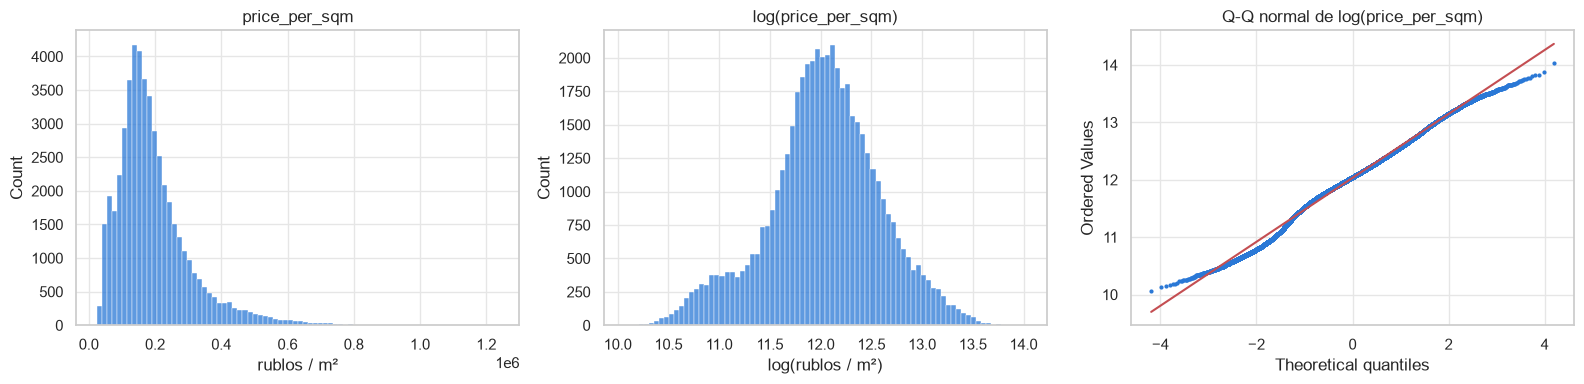

Asimetría  original: 1.69
Asimetría  log     : -0.20


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df[TARGET], bins=80, color=COLOR, ax=axes[0])
axes[0].set(title="price_per_sqm", xlabel="rublos / m²")
sns.histplot(np.log(df[TARGET]), bins=80, color=COLOR, ax=axes[1])
axes[1].set(title="log(price_per_sqm)", xlabel="log(rublos / m²)")
stats.probplot(np.log(df[TARGET]), dist="norm", plot=axes[2])
axes[2].set_title("Q-Q normal de log(price_per_sqm)")
axes[2].get_lines()[0].set(color=COLOR, markersize=2)
plt.tight_layout(); guardar(fig, "target_distribucion"); plt.show()

print(f"Asimetría  original: {df[TARGET].skew():.2f}")
print(f"Asimetría  log     : {np.log(df[TARGET]).skew():.2f}")

**🔧 Qué hace el código**

- `plt.subplots(1, 3)` crea una figura con 3 paneles en una fila.
- Panel 1: `sns.histplot` dibuja el histograma del precio con 80 intervalos (`bins`).
- Panel 2: el mismo histograma sobre `np.log(precio)`.
- Panel 3: `stats.probplot(..., dist="norm")` dibuja el Q-Q plot contra una normal, con la recta de referencia.
- `plt.tight_layout()` acomoda los paneles para que no se superpongan; `guardar` exporta la imagen y `plt.show()` la muestra.
- Al final, `.skew()` calcula la asimetría en las dos escalas.

**📊 Interpretación — distribución del target**

- **Histograma original (izquierda):** la distribución es **asimétrica a la derecha** (asimetría 1,69). La mayoría de los departamentos está entre 100k y 250k rublos/m², con una cola larga que llega a 1,2 millones.
- **Histograma en log (centro):** el logaritmo comprime la cola de los precios altos y la distribución queda **casi simétrica** (asimetría −0,20; la media, 12,03, y la mediana, 12,05, son casi iguales). A la izquierda del pico, cerca de 11 (≈ 60k rublos/m²), hay un **"hombro"**: la curva forma un escalón en lugar de bajar suave. Es un grupo distinto de departamentos, la periferia lejana (TAO, NAO, ZelAO; ver §4.1-a). Ese hombro "equilibra" una leve cola derecha del resto de Moscú, así que la simetría global es en parte una compensación (§4.1-b).
- **Q-Q plot (derecha):** compara los cuantiles de log(precio) con los que tendría si fuera normal; la recta roja marca la normalidad perfecta.
  - Entre −1 y +2 en el eje X los puntos están **sobre la recta**: la mayoría de los datos se comporta como una normal.
  - Entre −2 y −1 los puntos quedan **un poco debajo** de la recta: hay más departamentos baratos de lo que tendría una normal. Es **el hombro de la periferia** visto desde otro gráfico.
  - En el extremo derecho los puntos se **doblan hacia abajo**: los departamentos más caros son **menos extremos** de lo que predeciría una normal (cola derecha corta). En el extremo izquierdo pasa algo parecido, más suave.
  - En resumen, log(precio) es **aproximadamente normal**: el centro coincide, las colas son algo más cortas (no hay valores absurdos) y el único desvío relevante es el hombro.

**Conclusión:** conviene modelar `log(price_per_sqm)`. Con el target en log la varianza se empareja entre zonas (§4.1-e), los residuos de la regresión tienden a ser más simétricos y los coeficientes se leen como cambios porcentuales. La normalidad que importa es la de los **residuos**; se verifica en el módulo D (§14.11).

### 4.1 Forma del target en log: respaldo numérico

Los gráficos de arriba se leen "a ojo". Esta celda cuantifica lo que muestran: de dónde sale el hombro, qué tan normales son las colas y si el log empareja la varianza entre zonas.

**📘 Conceptos de esta sección**

#### Mezcla de poblaciones
- **Qué es:** una variable formada por **dos o más grupos con comportamientos distintos**. En el histograma aparecen varios picos o un escalón ("hombro").
- **Para qué sirve detectarla:** indica que **falta una variable que separe los grupos**: el precio no tiene una sola distribución, sino una por zona.
- **Qué permite determinar:** qué variable explica la mezcla; acá, la ubicación.
- **Si se detecta:** se incluye esa variable en el modelo, que ajusta cada grupo en su nivel, y la mezcla desaparece de los residuos.
- **Si no se detecta:** el modelo trata a toda Moscú como un solo grupo y **sobreestima sistemáticamente** la periferia y subestima el centro.

#### Curtosis
- **Qué es:** mide el **peso de las colas**, es decir, qué tan frecuentes son los valores extremos frente a una normal. Se reporta como "exceso": 0 = como una normal; positiva = colas pesadas; negativa = colas livianas.
- **Para qué sirve:** anticipar cuántos valores extremos va a tener que tolerar el modelo.
- **Qué permite determinar:** si los atípicos son un fenómeno aislado o algo estructural de la variable.
- **Si se mide:** se sabe si mínimos cuadrados es adecuado. Ese método eleva cada error al cuadrado, así que un valor extremo pesa muchísimo.
- **Si no se mide:** con colas pesadas no detectadas, unos pocos puntos pueden **arrastrar toda la recta** y producir coeficientes inestables sin causa aparente.

#### Homocedasticidad
- **Qué es:** que la dispersión de los errores sea **similar en todo el rango** de valores. Lo contrario es heterocedasticidad (por ejemplo, errores mucho mayores en las zonas caras).
- **Para qué sirve:** es un supuesto de la regresión lineal. Los errores estándar, los p-valores y los intervalos se calculan asumiéndola.
- **Qué permite determinar:** si la inferencia del modelo es confiable y si conviene transformar el target.
- **Si se cumple:** los p-valores y los intervalos son válidos, y todas las observaciones pesan de forma equilibrada.
- **Si no se cumple:** los coeficientes siguen siendo insesgados, pero sus errores estándar están mal calculados, así que una variable puede parecer significativa sin serlo. Además, el ajuste queda dominado por el grupo más disperso.

#### Test de normalidad (Shapiro-Wilk)
- **Qué es:** prueba de hipótesis con H₀ = "los datos provienen de una normal". Un p-valor < 0,05 lleva a rechazar H₀.
- **Para qué sirve:** dar una respuesta formal de sí o no sobre la normalidad.
- **Qué permite determinar:** si hay evidencia estadística de que los datos **no** son normales, pero no **cuánto** se alejan.
- **Si se usa solo:** con muestras grandes rechaza ante desvíos minúsculos sin importancia práctica, y puede llevar a descartar transformaciones que funcionan bien.
- **Si se usa junto con el Q-Q plot:** el test dice *si* hay desvío y el gráfico dice *cuánto y dónde*. Con muchos datos, manda el gráfico.

In [10]:
y_log = np.log(df[TARGET])

# (a) El "hombro": ¿de qué zonas son los departamentos con log < 11,3 (≈ 81k rublos/m²)?
hombro = df[y_log < 11.3]
print(f"(a) Filas en el hombro (log < 11,3): {len(hombro):,}")
print((hombro["okrug"].value_counts(normalize=True).head(4) * 100).round(1).to_string(), "\n")

# (b) La asimetría global, ¿es real o una compensación?
periferia = df["okrug"].isin(["TAO", "NAO", "ZelAO"])
print(f"(b) Asimetría log, todo el dataset : {y_log.skew():.2f}")
print(f"    Asimetría log, sin periferia   : {y_log[~periferia].skew():.2f}\n")

# (c) Peso de las colas: curtosis en exceso (normal = 0)
print(f"(c) Curtosis en exceso de log(price_per_sqm): {stats.kurtosis(y_log):.2f}\n")

# (d) Cuantiles observados (estandarizados) vs. los de una normal: es el Q-Q plot en números
z = (y_log - y_log.mean()) / y_log.std()
p = [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
print("(d) Cuantiles: normal teórica vs. observado")
print(pd.DataFrame({"percentil": [f"{q:.1%}" for q in p],
                    "normal teórica": stats.norm.ppf(p),
                    "observado": z.quantile(p).values}).round(2).to_string(index=False), "\n")

# (e) ¿El log empareja la varianza entre zonas baratas y caras? (homocedasticidad)
disp = pd.DataFrame({"desvío en rublos": df.groupby("okrug")[TARGET].std(),
                     "desvío en log":    df.assign(l=y_log).groupby("okrug")["l"].std()})
print("(e) Dispersión por okrug (de la zona más barata a la más cara):")
print(disp.loc[["TAO", "YuAO", "CAO"]].round(3).to_string(), "\n")

# (f) Test de normalidad de Shapiro-Wilk sobre una muestra de 5.000
print(f"(f) Shapiro-Wilk, p-valor: {stats.shapiro(y_log.sample(5000, random_state=config.RANDOM_STATE)).pvalue:.1e}")

(a) Filas en el hombro (log < 11,3): 5,010
okrug
TAO     73.10
NAO     20.60
ZelAO    2.60
YuAO     1.20 

(b) Asimetría log, todo el dataset : -0.20
    Asimetría log, sin periferia   : 0.53

(c) Curtosis en exceso de log(price_per_sqm): 0.22

(d) Cuantiles: normal teórica vs. observado
percentil  normal teórica  observado
     0.1%           -3.09      -2.97
     1.0%           -2.33      -2.49
     5.0%           -1.64      -1.87
    25.0%           -0.67      -0.56
    50.0%            0.00       0.02
    75.0%            0.67       0.63
    95.0%            1.64       1.65
    99.0%            2.33       2.29
    99.9%            3.09       2.77 

(e) Dispersión por okrug (de la zona más barata a la más cara):
       desvío en rublos  desvío en log
okrug                                 
TAO           14,896.14           0.25
YuAO          56,477.37           0.32
CAO          131,102.57           0.29 

(f) Shapiro-Wilk, p-valor: 6.8e-14


**🔧 Qué hace el código**

- **(a)** Filtra las filas con log(precio) < 11,3 y calcula qué porcentaje pertenece a cada okrug (`value_counts(normalize=True)` da proporciones en lugar de conteos).
- **(b)** `isin` marca las filas de la periferia; `~` invierte la máscara (las que **no** son de la periferia). Se compara la asimetría con y sin ellas.
- **(c)** `stats.kurtosis` calcula la curtosis en exceso (la normal vale 0).
- **(d)** Estandariza log(precio) (le resta la media y divide por el desvío, para que quede en la misma escala que una normal estándar) y compara sus percentiles con los teóricos de una normal (`stats.norm.ppf`). Son los mismos puntos que dibuja el Q-Q plot, en forma de tabla.
- **(e)** Calcula el desvío estándar del precio por okrug en rublos y en log. Muestra la zona más barata (TAO), una intermedia (YuAO) y la más cara (CAO).
- **(f)** Aplica Shapiro-Wilk sobre una muestra de 5.000 filas, el máximo recomendado para este test. Usa la semilla del proyecto para que la muestra sea siempre la misma.

**📊 Interpretación del resultado**

- **(a)** El hombro está formado por **TAO (~73%) y NAO (~21%)**, con un pequeño aporte de ZelAO: es la periferia lejana. El histograma es una **mezcla de dos poblaciones**: Moscú propiamente dicha (pico en 12 ≈ 163k) y la periferia barata (≈ 60k).
- **(b)** Sin la periferia, la asimetría del log sube a **+0,53**. El −0,20 global es en parte una **compensación**: la cola derecha de Moscú central queda "equilibrada" por el hombro de la izquierda. El número solo no alcanza; hay que mirarlo junto con el gráfico.
- **(c)** Curtosis ≈ **0,22**: las colas pesan casi lo mismo que en una normal. No hay una cantidad anormal de valores extremos.
- **(d)** Del 25% al 95% los cuantiles observados coinciden con los teóricos: **el centro de la distribución es normal**. En el 1%–5% los observados son más bajos (el hombro, que en el Q-Q aparece como puntos debajo de la recta entre −2 y −1). En el 99,9% el observado (2,77) es menor que el teórico (3,09): los departamentos más caros son **menos extremos** de lo que predeciría una normal.
- **(e)** En rublos, el desvío de CAO es **~9 veces** el de TAO; en log son casi iguales. El log **estabiliza la varianza**, que es uno de los supuestos de la regresión lineal (homocedasticidad).
- **(f)** Shapiro-Wilk **rechaza** la normalidad (p ≈ 10⁻¹³) aunque los gráficos muestran que es casi normal. Con muestras grandes el test detecta desvíos minúsculos sin importancia práctica; por eso se prioriza el Q-Q plot.

**Conclusión:** `log(price_per_sqm)` es un target adecuado para la regresión lineal. El hombro anticipa que la **ubicación** tiene que estar en el modelo.

### 4.2 Valores atípicos (criterio IQR)

**🎯 Objetivo de la sección**

Detectar los valores extremos del target y decidir si son **errores** (que hay que eliminar) o **casos reales** (que hay que conservar). **Si no se hace**, o se dejan errores que distorsionan la recta, o se eliminan casos legítimos y el modelo deja de servir para ese segmento.

**📘 Conceptos de esta sección**

#### Valor atípico (*outlier*)
- **Qué es:** una observación muy alejada del resto. Puede ser un **error** (de carga o de medición) o un **valor real pero raro** (un departamento de lujo en el centro).
- **Para qué sirve identificarlo:** decidir si se corrige, se elimina o se conserva. La regresión por mínimos cuadrados es muy sensible a ellos.
- **Qué permite determinar:** si hay problemas de calidad de datos o si la variable tiene una cola real que el modelo debe aprender.
- **Si se eliminan los atípicos reales:** el modelo se ajusta mejor a los datos "típicos", pero **pierde la capacidad de predecir** justo en el segmento que se eliminó (por ejemplo, CAO) y las métricas quedan artificialmente optimistas.
- **Si se conservan los errores:** distorsionan los coeficientes y empeoran todas las predicciones.

#### Criterio IQR (rango intercuartílico)
- **Qué es:** IQR = Q3 − Q1 (el rango donde está el 50% central de los datos). Se marca como atípico todo valor por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR. Es la misma regla que dibuja los "bigotes" de un boxplot.
- **Para qué sirve:** detectar atípicos de forma automática y robusta, porque usa cuantiles en lugar de media y desvío.
- **Qué permite determinar:** **candidatos** a atípicos. No decide por sí solo si son errores.
- **Si se aplica sin analizar:** en una variable asimétrica marca como atípica a toda la cola real (acá, el 5,4% de los datos, casi todos en CAO).
- **Si se aplica en la escala adecuada (log) y se mira dónde caen:** permite distinguir errores de valores legítimos.

In [11]:
def outliers_iqr(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

out_raw = outliers_iqr(df[TARGET])
out_log = outliers_iqr(np.log(df[TARGET]))
print(f"Atípicos en escala original: {out_raw.sum():,} ({out_raw.mean():.1%})")
print(f"Atípicos en escala log     : {out_log.sum():,} ({out_log.mean():.1%})")
print("\n¿Dónde están los atípicos de la escala original? (por okrug)")
print(df.loc[out_raw, "okrug"].value_counts().head())

Atípicos en escala original: 2,696 (5.4%)
Atípicos en escala log     : 1,113 (2.2%)

¿Dónde están los atípicos de la escala original? (por okrug)
okrug
CAO      2220
ZAO       202
YuZAO     136
SZAO       69
SAO        50
Name: count, dtype: int64


**🔧 Qué hace el código**

- La función `outliers_iqr` calcula Q1 y Q3, el IQR (Q3 − Q1) y devuelve `True` para los valores fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]. El operador `|` significa "o".
- Se aplica al precio en escala original y en log, y se cuenta cuántos atípicos hay en cada caso.
- `df.loc[out_raw, "okrug"]` toma el okrug de los atípicos, y `value_counts()` muestra en qué zonas están.

**📊 Interpretación del resultado**

- **En escala original:** 2.696 atípicos (5,4%). De ellos, **2.220 (82%) están en CAO**, el centro. No son errores de carga: son departamentos realmente caros en la zona más cara de la ciudad. El IQR los marca porque la distribución original es asimétrica, y cualquier valor de la cola larga queda "lejos" de la caja.
- **En escala log:** bajan a 1.113 (2,2%). Al corregir la asimetría, la mayoría de esos departamentos deja de ser extrema.
- **Decisión:** **no eliminar** atípicos por IQR. Eliminarlos dejaría al modelo sin capacidad de predecir en el centro, que es justamente la zona de mayor valor. Modelar en log reduce su influencia.

## 5. Variables numéricas

**🎯 Objetivo de la sección**

Analizar las 13 predictoras numéricas: primero **cómo se distribuye cada una** (§5.1) y después **cómo se relaciona cada una con el target** (§5.2). Determina qué variables transformar (las que tienen colas largas o relación curva) y cuáles tienen poder predictivo. **Si no se hace**, se pueden incluir variables sin relación con el precio (ruido) o dejar relaciones curvas sin transformar, y la regresión lineal las modelaría mal.

Los conceptos de histograma, asimetría y transformación logarítmica se explicaron en §4 y se aplican igual acá.

**📘 Concepto: histograma de una variable discreta**
- Cuando una variable toma pocos valores (`rooms`, `total_floors`, `ceiling_height`, la tasa hipotecaria), su histograma no es una "campana" sino **barras separadas** con huecos entre ellas. No es un error del gráfico: indica que la variable es **discreta**, y que en §5.2 conviene analizarla con boxplots por valor.

### 5.1 Distribuciones

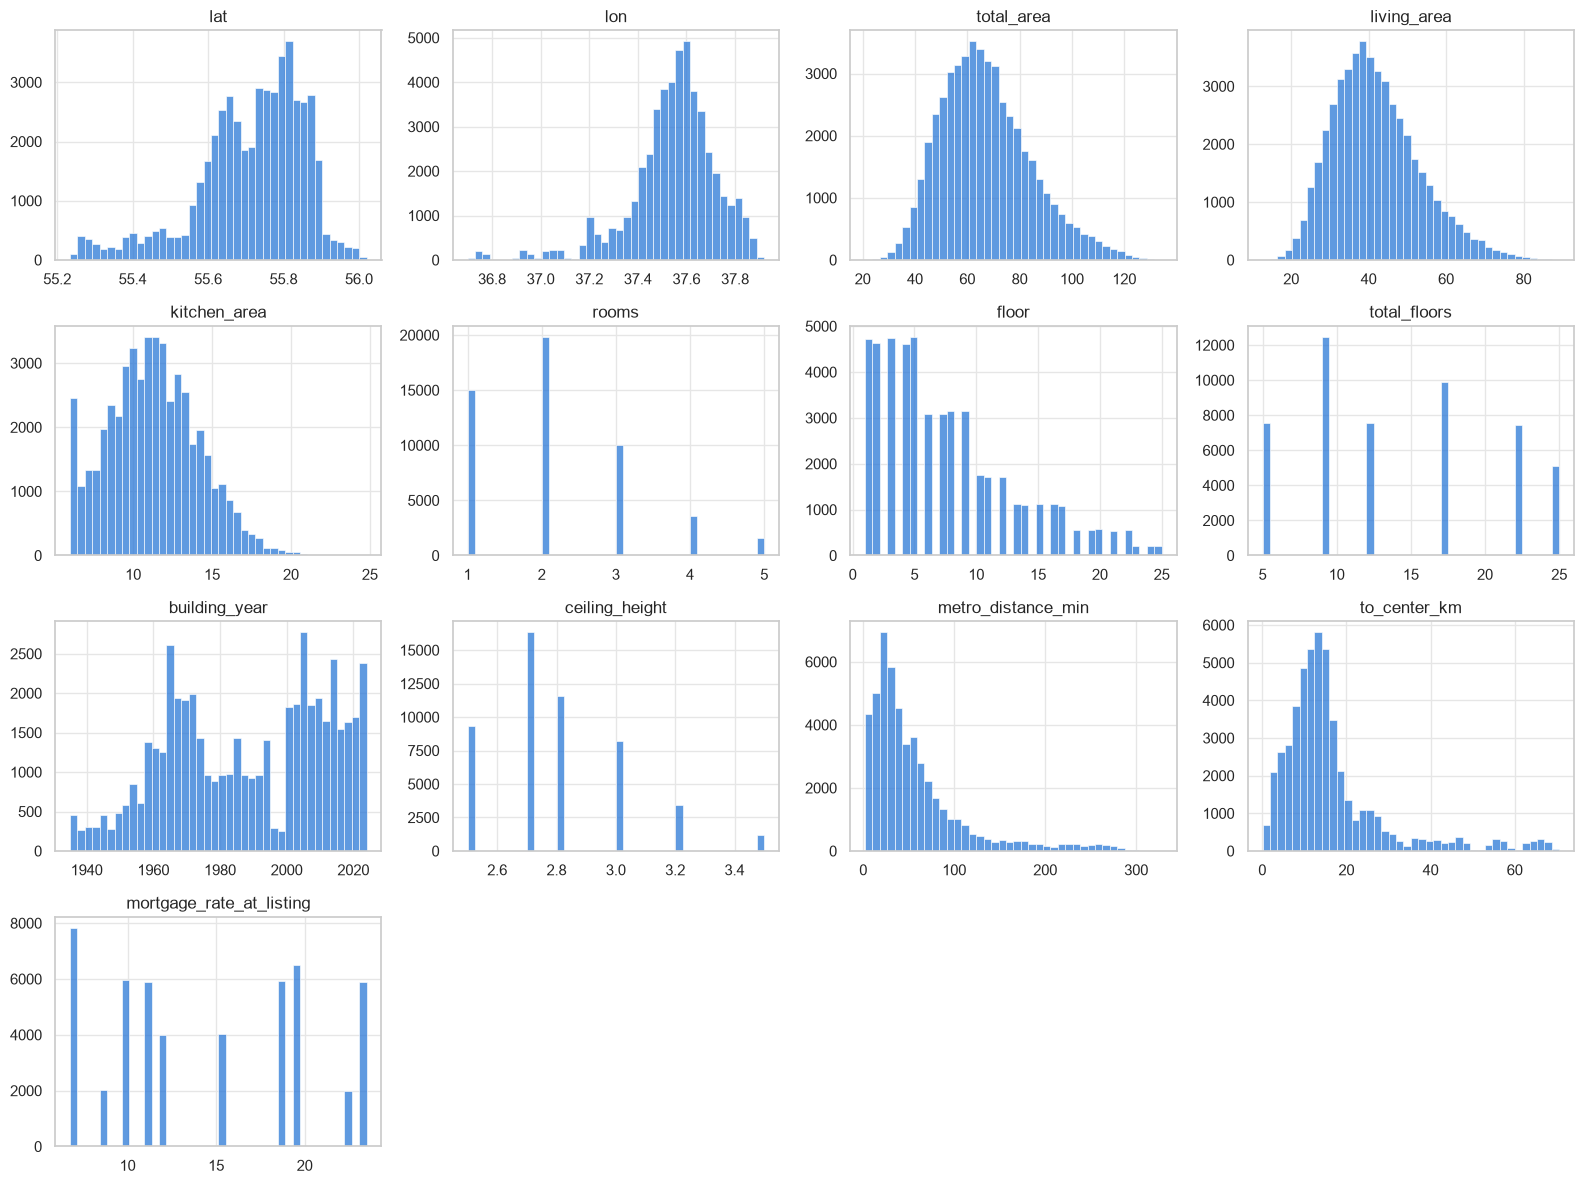

,to_center_km,metro_distance_min,floor,ceiling_height,rooms,living_area,total_area,kitchen_area,total_floors,mortgage_rate_at_listing,building_year,lat,lon
asimetría,2.11,2.04,1.01,0.94,0.82,0.64,0.58,0.27,0.27,0.18,-0.20,-0.96,-1.23


In [12]:
n = len(num_cols)
fig, axes = plt.subplots(int(np.ceil(n / 4)), 4, figsize=(16, 3 * np.ceil(n / 4)))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=40, color=COLOR, ax=ax)
    ax.set(title=col, xlabel="", ylabel="")
for ax in axes.flat[n:]:
    ax.remove()
plt.tight_layout(); guardar(fig, "numericas_distribucion"); plt.show()

df[num_cols].skew().sort_values(ascending=False).rename("asimetría").to_frame().T

**🔧 Qué hace el código**

- Calcula cuántas filas de paneles hacen falta para 13 variables en 4 columnas (`np.ceil(13 / 4)` = 4 filas).
- `axes.flat` recorre los paneles en orden y `zip` asigna una variable a cada uno. A cada panel se le dibuja un histograma de 40 intervalos.
- Los paneles sobrantes (16 − 13 = 3) se eliminan con `ax.remove()`.
- Al final, una tabla con la asimetría de cada variable, ordenada de mayor a menor.

**📊 Interpretación — distribución de las variables numéricas**

- **Superficies** (`total_area`, `living_area`, `kitchen_area`): forma de campana con una leve cola a la derecha. No presentan valores imposibles.
- **Variables casi discretas:** `rooms` (1 a 5), `total_floors` (6 alturas típicas de edificio), `ceiling_height` (6 valores) y `mortgage_rate_at_listing` (solo **10 valores**, uno por cada período de tasa) son numéricas, pero se comportan como categorías.
- **`building_year`** tiene **dos picos**, uno en los años 60–70 (edificios soviéticos de la época Khrushchev) y otro de 2000 en adelante, con un hueco cerca de 1998–2000.
- **`floor`** cae en escalones porque depende de la altura del edificio: los pisos altos solo existen en edificios altos.
- **Distancias** (`to_center_km`, `metro_distance_min`): colas largas a la derecha (asimetría ≈ 2). La mayoría está cerca, pero hay propiedades a más de 60 km o 300 minutos (la "Nueva Moscú").
- **`lat` / `lon`:** asimetría negativa por los barrios alejados del sudoeste.

**Conclusión:** las dos distancias son candidatas a una transformación logarítmica (`log1p`) para reducir el peso de la cola.

### 5.2 Relación con el target

Comparamos **Pearson** (mide relación *lineal*) con **Spearman** (mide relación *monótona*, por rangos). Si Spearman es claramente mayor que Pearson, la relación existe pero no es lineal → candidata a transformación.

**🎯 Objetivo de la sección**

Medir la fuerza y la **forma** de la relación de cada predictora numérica con el target. Determina qué variables tienen poder predictivo y cuáles necesitan transformación. **Si no se hace**, se incluyen variables que solo agregan ruido, o se modelan con una recta relaciones que son curvas.

**📘 Conceptos de esta sección**

#### Diagrama de dispersión (*scatter plot*)
- **Qué es:** cada observación es un punto con coordenadas (predictora, target).
- **Para qué sirve:** ver la **forma** de la relación entre dos variables: lineal, curva, inexistente, con grupos.
- **Qué permite determinar:** si una recta es un buen resumen de la relación o si hace falta transformar.
- **Si se hace:** se detectan relaciones no lineales que la correlación por sí sola no muestra.
- **Si no se hace:** se puede concluir "no hay relación" con una correlación baja cuando en realidad la relación existe pero es curva (o al revés).

#### Correlación de Pearson
- **Qué es:** número entre −1 y 1 que mide la fuerza de la relación **lineal**. 0 = sin relación lineal; ±1 = relación lineal perfecta; el signo da la dirección.
- **Para qué sirve:** medir qué tan bien una recta resume la relación. Es justamente lo que va a usar la regresión lineal.
- **Qué permite determinar:** qué predictoras tienen relación lineal con el target y cuáles son redundantes entre sí (§9).
- **Si se usa:** se priorizan variables con base objetiva.
- **Si se usa sola:** **subestima las relaciones curvas** y es sensible a los valores extremos.

#### Correlación de Spearman
- **Qué es:** la correlación de Pearson calculada sobre los **rangos** (posiciones ordenadas) en vez de sobre los valores. Mide relación **monótona**: si una sube, la otra siempre sube (o siempre baja), sea en línea recta o en curva.
- **Para qué sirve:** detectar relaciones no lineales pero ordenadas, y ser robusta frente a atípicos.
- **Qué permite determinar:** comparada con Pearson, **si conviene transformar**. Si Spearman es claramente mayor (en valor absoluto), la relación existe pero no es lineal.
- **Si se compara con Pearson:** se identifican las variables que necesitan transformación (acá, las dos distancias).
- **Si no se compara:** se pierde la señal de que una transformación mejoraría mucho el modelo.

#### `log1p`
- **Qué es:** log(1 + x). Se comporta como el logaritmo para valores grandes, pero está definido en x = 0 (log1p(0) = 0).
- **Para qué sirve:** aplicar una transformación logarítmica a variables que pueden valer 0, como distancias o conteos.
- **Si se usa en vez de log:** se evitan los errores por log(0) = −∞.

In [13]:
corr = pd.DataFrame({
    "pearson":        df[num_cols].corrwith(df[TARGET]),
    "spearman":       df[num_cols].corrwith(df[TARGET], method="spearman"),
    "pearson_log_y":  df[num_cols].corrwith(np.log(df[TARGET])),
}).sort_values("spearman", key=abs, ascending=False)
corr

,pearson,spearman,pearson_log_y
to_center_km,-0.60,-0.75,-0.78
metro_distance_min,-0.56,-0.72,-0.74
lat,0.30,0.28,0.48
lon,0.25,0.23,0.41
mortgage_rate_at_listing,0.17,0.19,0.18
ceiling_height,0.08,0.06,0.08
building_year,0.02,0.04,0.03
floor,0.01,0.02,0.02
total_floors,0.01,0.02,0.02
living_area,0.00,0.01,0.00


**🔧 Qué hace el código**

- `corrwith` calcula la correlación de cada predictora numérica con el target.
- Se calculan tres versiones: Pearson con el precio original, Spearman con el precio original y Pearson con log(precio).
- `sort_values("spearman", key=abs, ...)` ordena por la **magnitud** de Spearman (sin importar el signo), de mayor a menor.

**📊 Interpretación del resultado**

- **Distancias (las más fuertes):** `to_center_km` (Spearman −0,75) y `metro_distance_min` (−0,72). Son **negativas**: a mayor distancia, menor precio. Spearman es claramente mayor que Pearson (−0,60 / −0,56), así que la relación es fuerte pero **no lineal**.
- **`lat` y `lon`:** correlación moderada positiva (0,30 / 0,25), que sube con log(precio) (0,48 / 0,41). Pero no significa "más al norte = más caro": refleja la cercanía al centro (ver §8).
- **`mortgage_rate_at_listing`:** 0,17–0,19. Como se ve en §7.1, es una correlación espuria.
- **El resto** (`ceiling_height`, `building_year`, pisos, superficies, `rooms`): correlación **prácticamente nula** (< 0,08). El tamaño de un departamento **no** influye en su precio *por m²*.
- **Columna `pearson_log_y`:** pasar el target a log mejora la correlación lineal de las distancias y de lat/lon. Es otra evidencia a favor de modelar en log.

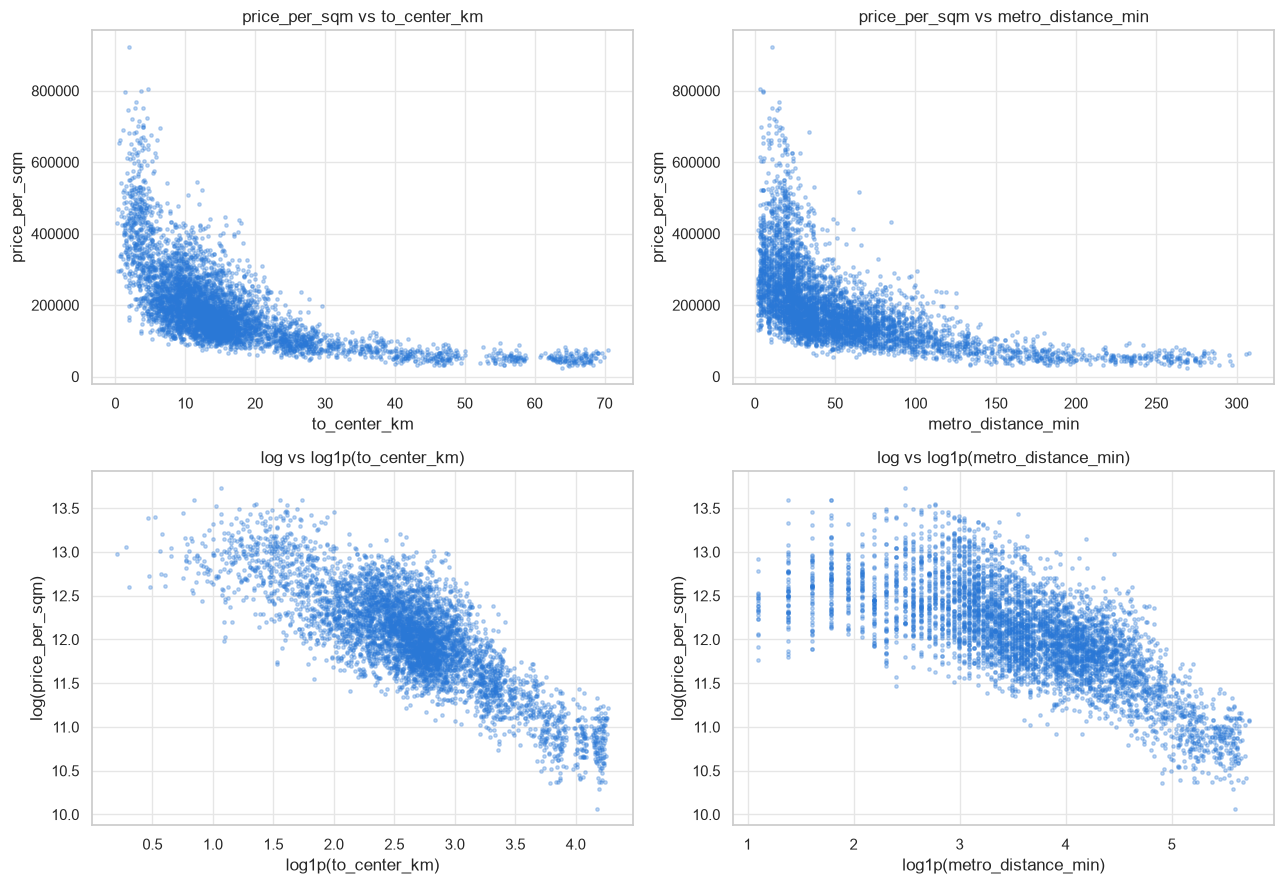

Pearson log1p(to_center_km) vs log(target): -0.816
Pearson log1p(metro_distance_min) vs log(target): -0.723


In [14]:
# Las dos variables más fuertes: escala original vs. log en ambos ejes
muestra = df.sample(5000, random_state=config.RANDOM_STATE)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for i, col in enumerate(["to_center_km", "metro_distance_min"]):
    axes[0, i].scatter(muestra[col], muestra[TARGET], s=6, alpha=.3, color=COLOR)
    axes[0, i].set(title=f"{TARGET} vs {col}", xlabel=col, ylabel=TARGET)
    axes[1, i].scatter(np.log1p(muestra[col]), np.log(muestra[TARGET]), s=6, alpha=.3, color=COLOR)
    axes[1, i].set(title=f"log vs log1p({col})", xlabel=f"log1p({col})", ylabel=f"log({TARGET})")
plt.tight_layout(); guardar(fig, "target_vs_distancias"); plt.show()

for col in ["to_center_km", "metro_distance_min"]:
    r = np.corrcoef(np.log1p(df[col]), np.log(df[TARGET]))[0, 1]
    print(f"Pearson log1p({col}) vs log(target): {r:.3f}")

**🔧 Qué hace el código**

- `df.sample(5000, random_state=...)` toma una muestra aleatoria reproducible para graficar (ver "Muestreo para graficar" en §8).
- Grilla de 2 × 2: la columna izquierda es `to_center_km` y la derecha `metro_distance_min`. La fila de arriba está en escala original; la de abajo, con log en los dos ejes.
- `scatter` dibuja un punto por departamento. `s=6` es el tamaño del punto y `alpha=.3` lo hace semitransparente, para que las zonas con muchos puntos superpuestos se vean más oscuras.
- Al final, `np.corrcoef` calcula Pearson entre las versiones transformadas, usando **todo** el dataset.

**📊 Interpretación — precio vs. distancia al centro y al metro**

- **Fila de arriba (escala original):** el precio **cae rápido en los primeros kilómetros o minutos y después se aplana**. La forma es una curva (tipo exponencial decreciente), no una recta, por eso Pearson (−0,60) subestima la relación y Spearman, que mide relación monótona, da más (−0,75).
- **Fila de abajo (log en ambos ejes):** con `log(precio)` vs. `log1p(distancia)` la nube se vuelve **aproximadamente lineal**. La correlación con `to_center_km` pasa de −0,60 a **−0,82**; con `metro_distance_min`, de −0,56 a −0,72.
- En `metro_distance_min` se ven columnas verticales porque la variable está en minutos enteros.

**Conclusión:** son las **dos predictoras más fuertes** del dataset, pero solo después de transformarlas con logaritmo. Además están muy correlacionadas entre sí (r = 0,90; ver §9), así que podrían ser redundantes.

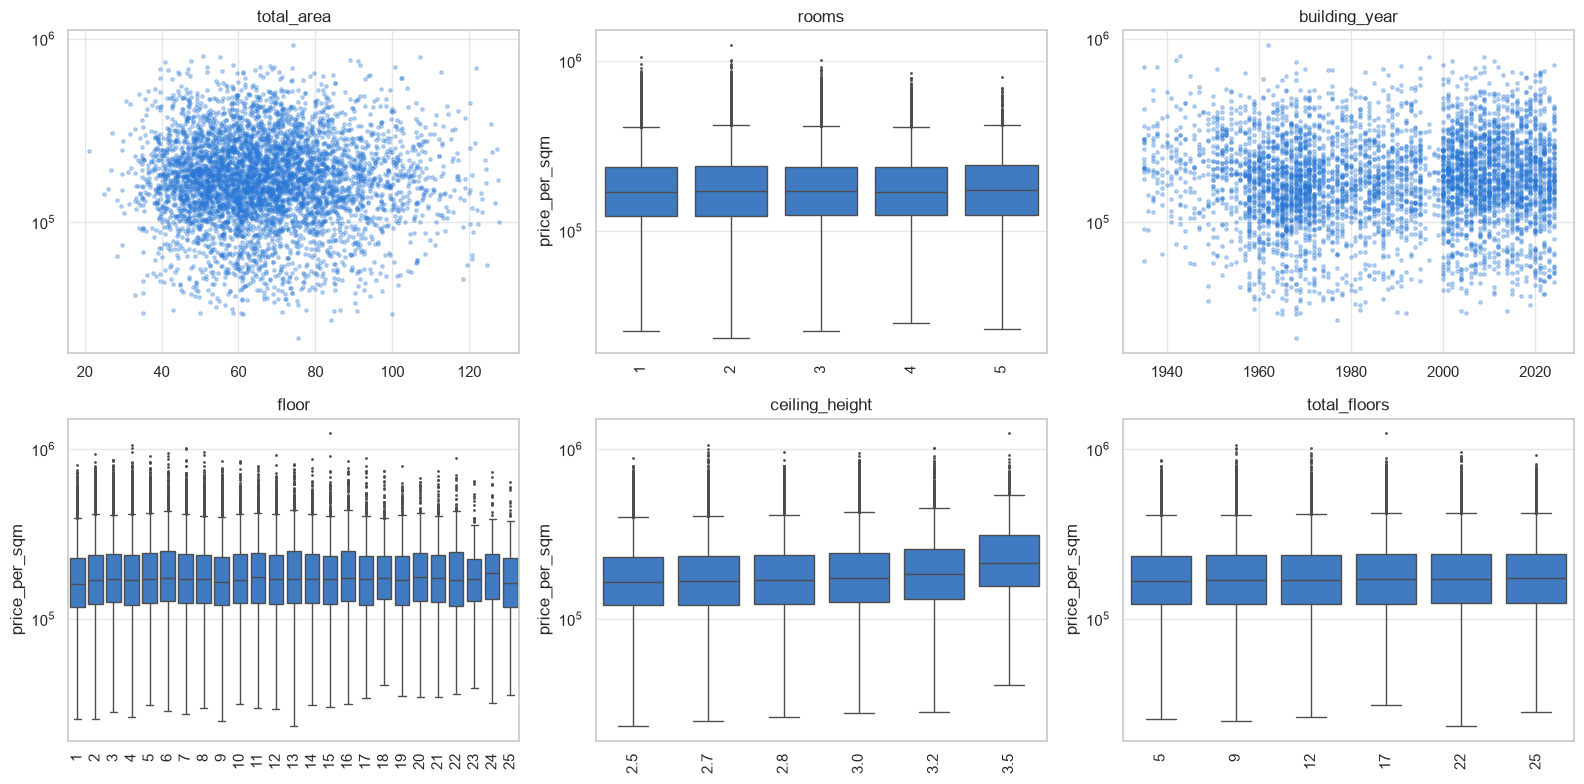

In [15]:
# El resto de numéricas tiene correlación casi nula: lo confirmamos visualmente
debiles = ["total_area", "rooms", "building_year", "floor", "ceiling_height", "total_floors"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, debiles):
    if df[col].nunique() <= 25:
        sns.boxplot(data=df, x=col, y=TARGET, color=COLOR, fliersize=1, ax=ax)
        ax.tick_params(axis="x", rotation=90)
    else:
        ax.scatter(muestra[col], muestra[TARGET], s=6, alpha=.3, color=COLOR)
    ax.set(title=col, xlabel="", yscale="log")
plt.tight_layout(); guardar(fig, "target_vs_numericas_debiles"); plt.show()

**🔧 Qué hace el código**

- Para cada variable "débil" elige el gráfico según la cantidad de valores distintos: si tiene **25 o menos** (discreta), un **boxplot por valor**; si tiene más (continua), una **dispersión**.
- `fliersize=1` achica los puntos de atípicos del boxplot, y `rotation=90` gira las etiquetas del eje X para que no se superpongan.
- `yscale="log"` pone el eje Y en escala logarítmica, para que se vean bien tanto los precios bajos como los altos.

**📊 Interpretación — variables numéricas con relación débil**

- **`total_area`:** la nube es plana. El precio *por m²* no depende del tamaño: un departamento grande cuesta más en total, pero no más por metro.
- **`rooms`, `floor`, `total_floors`:** las cajas están prácticamente a la misma altura en todas las categorías. No hay efecto visible.
- **`building_year`:** no hay tendencia; los edificios nuevos y los viejos tienen precios similares por m². Se ve el hueco de construcción cerca de 1998–2000.
- **`ceiling_height`** es **la excepción**: la mediana sube con la altura del techo (los de 3,5 m son claramente más caros) aunque su correlación global sea solo 0,08. Refleja en buena parte el tipo de edificio: los "stalin" tienen techos de 3,23 m en promedio (el resto, 2,75 m) y son los más caros (§6).

**Conclusión:** salvo `ceiling_height`, estas variables aportan poco o nada a la predicción. Se dejan en el modelo base y se decide con MLflow si conviene eliminarlas.

## 6. Variables categóricas

Usamos la **mediana** por categoría (robusta a la asimetría del target) y escala log en el eje Y para que los boxplots sean comparables.

**🎯 Objetivo de la sección**

Evaluar si el precio cambia según la categoría (zona, tipo de edificio, renovación…). Determina qué categóricas incluir en el modelo y cómo codificarlas. **Si no se hace**, se puede dejar afuera la variable más importante del dataset (la ubicación) o incluir categóricas que no aportan y solo suman columnas.

**📘 Conceptos de esta sección**

#### Variable categórica
- **Qué es:** una variable cuyos valores son **grupos o etiquetas**, no cantidades (no tiene sentido promediarlos). Puede ser **nominal**, sin orden (`okrug`, `seller_type`), u **ordinal**, con orden natural (`renovation`: sin renovar < cosmética < euro < diseñador).
- **Para qué sirve identificarlas:** reciben un análisis y una codificación distintos de los de las numéricas.
- **Qué permite determinar:** qué grupos tienen precios distintos y cómo hay que convertirlos a números para el modelo.
- **Si se tratan correctamente:** se codifican con one-hot (§6.2) y el modelo estima un efecto por categoría.
- **Si se tratan como números arbitrarios** (CAO = 1, TAO = 2…): el modelo interpreta un orden y unas distancias que no existen ("TAO es el doble de CAO") y los coeficientes no tienen sentido.

#### Boxplot (diagrama de caja)
- **Qué es:** resume una distribución con cinco valores. La **caja** va de Q1 a Q3 (el 50% central), la **línea** interna es la mediana, los **bigotes** llegan hasta 1,5·IQR y los **puntos** sueltos son los atípicos según el criterio IQR.
- **Para qué sirve:** **comparar distribuciones entre grupos** lado a lado.
- **Qué permite determinar:** si las categorías difieren en nivel (posición de la mediana), en dispersión (tamaño de la caja) o en atípicos.
- **Si se hace:** se ve de inmediato qué categorías importan (cajas a distinta altura) y cuáles no (cajas iguales).
- **Si no se hace:** comparando solo promedios se pierde la dispersión y el solapamiento entre grupos.

#### Mediana vs. media
- **Mediana:** el valor del medio. **No la afectan los extremos.**
- **Media:** el promedio. Se desplaza hacia la cola.
- Con un target asimétrico (media 196k, mediana 170k) la mediana representa mejor al departamento "típico" de cada grupo. Por eso las categorías se ordenan por mediana.

#### Escala logarítmica en el eje
- **Qué es:** el eje se dibuja de modo que cada marca multiplica por 10 (10⁵, 10⁶) en lugar de sumar.
- **Para qué sirve:** comparar grupos con niveles muy distintos (TAO ~56k y CAO ~434k) en el mismo gráfico sin que los baratos queden aplastados contra el piso.
- **Si no se usa:** las cajas de las zonas baratas se ven como líneas y no se pueden comparar.

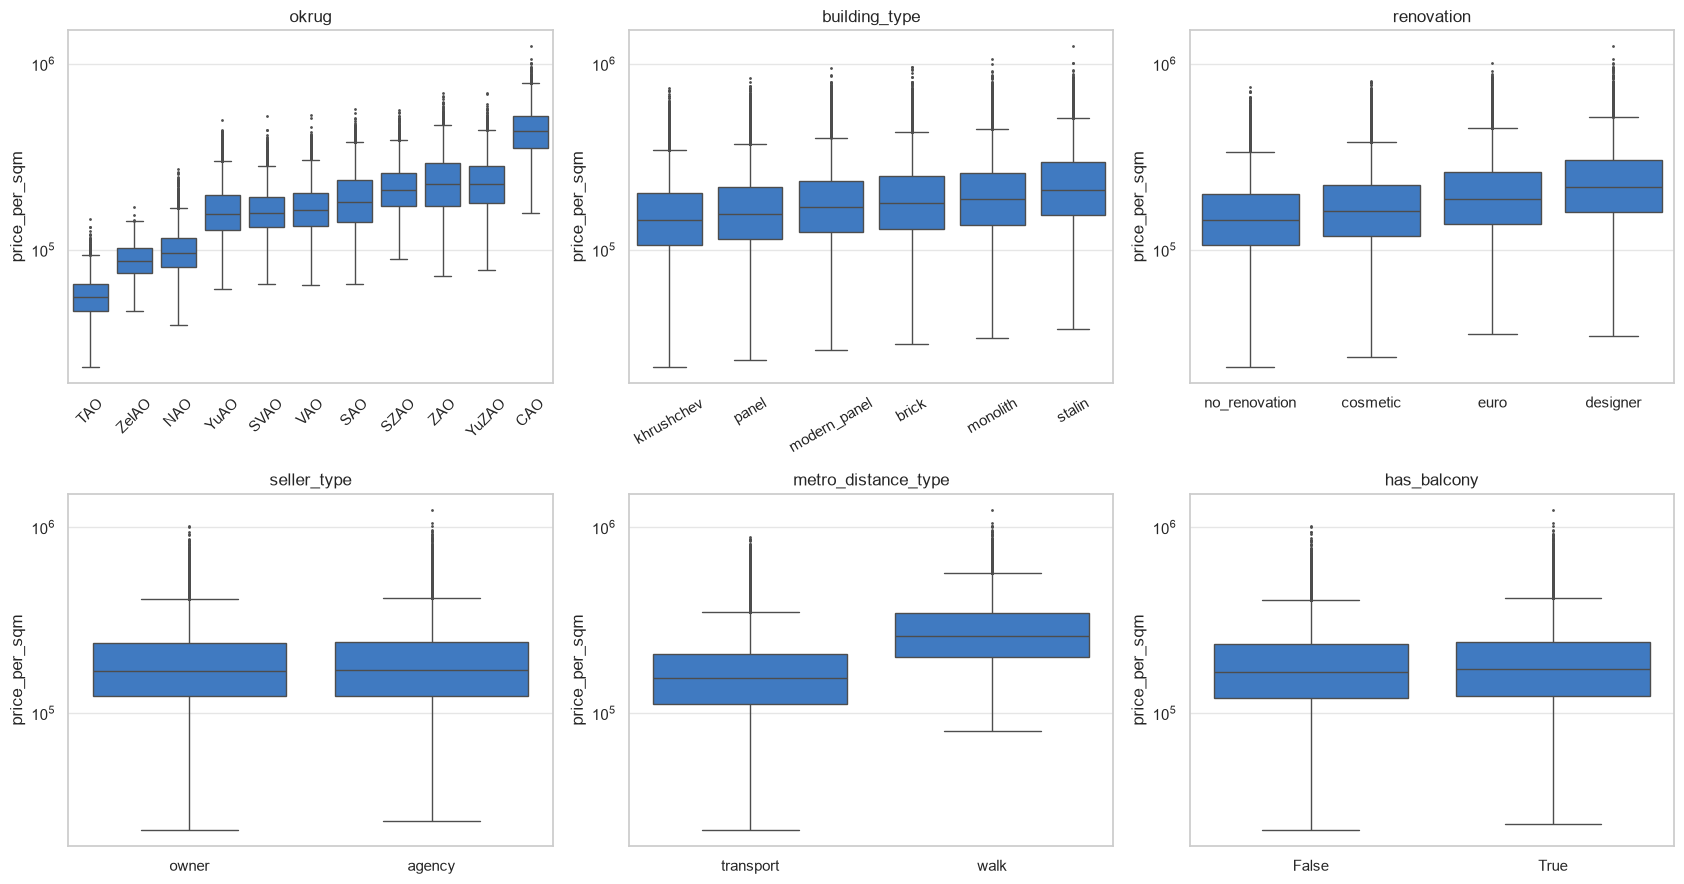

In [16]:
def boxplot_cat(col, ax, rot=0):
    orden = df.groupby(col)[TARGET].median().sort_values().index
    sns.boxplot(data=df, x=col, y=TARGET, order=orden, color=COLOR, fliersize=1, ax=ax)
    ax.set(yscale="log", xlabel="", title=col)
    ax.tick_params(axis="x", rotation=rot)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (col, rot) in zip(axes.flat, [("okrug", 45), ("building_type", 30), ("renovation", 0),
                                       ("seller_type", 0), ("metro_distance_type", 0), ("has_balcony", 0)]):
    boxplot_cat(col, ax, rot)
plt.tight_layout(); guardar(fig, "target_vs_categoricas"); plt.show()

**🔧 Qué hace el código**

- La función `boxplot_cat` agrupa por la variable (`groupby`), calcula la mediana del precio de cada categoría y la usa para **ordenar** las cajas de menor a mayor. Después dibuja el boxplot con eje Y logarítmico.
- Se aplica a las 6 categóricas de cardinalidad baja o media, cada una en un panel. El número que acompaña a cada variable es el ángulo de rotación de sus etiquetas.
- `district`, `metro_station` y `metro_line` no se grafican porque tienen demasiadas categorías para un boxplot legible; se analizan con números en §6.1 y §6.2.

**📊 Interpretación — precio según cada variable categórica**

Cada panel ordena las categorías de menor a mayor mediana; el eje Y está en escala log.

- **`okrug`:** la diferencia es enorme. CAO (el centro) tiene una mediana de **~434k**, casi **8 veces** la de TAO (~56k). Es la categórica más fuerte: la ubicación domina el precio.
- **`building_type`:** orden coherente con la historia de Moscú: khrushchev (más barato) < panel < modern_panel < brick < monolith < stalin (más caro). Efecto moderado (~45% entre extremos).
- **`renovation`:** orden lógico, no_renovation < cosmetic < euro < designer, ~50% de diferencia entre extremos. Se comporta como una **variable ordinal**.
- **`metro_distance_type`:** las propiedades a las que se llega **caminando** al metro son ~70% más caras. Pero esta variable resume la distancia: "walk" siempre corresponde a menos de 40 minutos, así que en buena parte repite la información de `metro_distance_min`.
- **`seller_type` y `has_balcony`:** las cajas son **idénticas**. No aportan información sobre el precio.

**Conclusión:** `okrug` (o `district`) es imprescindible; `renovation`, `building_type` y `metro_distance_type` aportan algo; `seller_type` y `has_balcony` son candidatas a eliminarse. La prueba de Kruskal-Wallis de abajo lo cuantifica.

In [17]:
# Resumen numérico: mediana, cantidad y brecha entre la categoría más cara y la más barata
resumen = []
for col in ["okrug", "building_type", "renovation", "seller_type", "metro_distance_type", "has_balcony", "metro_line"]:
    g = df.groupby(col)[TARGET].median()
    resumen.append({"variable": col, "categorías": g.size,
                    "mediana mín": g.min(), "mediana máx": g.max(), "máx / mín": g.max() / g.min()})
pd.DataFrame(resumen).sort_values("máx / mín", ascending=False)

,variable,categorías,mediana mín,mediana máx,máx / mín
0,okrug,11,"55,800.00","434,500.00",7.79
4,metro_distance_type,2,"153,500.00","258,600.00",1.68
2,renovation,4,"143,900.00","217,100.00",1.51
1,building_type,6,"145,300.00","210,600.00",1.45
6,metro_line,12,"152,800.00","177,200.00",1.16
5,has_balcony,2,"166,600.00","171,800.00",1.03
3,seller_type,2,"169,300.00","171,000.00",1.01


**🔧 Qué hace el código**

Para cada categórica calcula la mediana del precio por categoría y guarda la menor, la mayor y el **cociente máx / mín**. Ese cociente indica cuántas veces más cara es la categoría más cara que la más barata: 1 significa que no hay diferencia.

**📊 Interpretación del resultado**

- **`okrug`: 7,8 veces.** Es por lejos la variable con mayor brecha: la mediana de CAO (434.500) casi multiplica por 8 a la de TAO (55.800).
- **`metro_distance_type` (1,7), `renovation` (1,5) y `building_type` (1,45):** diferencias moderadas pero relevantes, del 45% al 70%.
- **`metro_line` (1,16):** diferencia chica. Una línea de metro atraviesa zonas caras y baratas, así que no discrimina bien.
- **`has_balcony` (1,03) y `seller_type` (1,01):** diferencias de 1% a 3%, prácticamente nulas.

### 6.1 Prueba de significancia (Kruskal-Wallis)

Test no paramétrico (no asume normalidad): H₀ = todas las categorías tienen la misma distribución del target. El tamaño de efecto **ε²** indica *cuánto* importa, porque con 50.000 filas casi cualquier diferencia es "significativa".

**🎯 Objetivo de la sección**

Confirmar con una prueba estadística lo que muestran los boxplots, y **ordenar las categóricas por importancia**. **Si no se hace**, la selección de variables depende de la impresión visual, que engaña cuando las diferencias son chicas.

**📘 Conceptos de esta sección**

#### Prueba de hipótesis y p-valor
- **Qué es:** un procedimiento para decidir si una diferencia observada puede deberse al azar. Se plantea una hipótesis nula **H₀** ("no hay diferencia") y se calcula el **p-valor**: la probabilidad de observar una diferencia al menos tan grande **si H₀ fuera cierta**.
- **Para qué sirve:** separar efectos reales de fluctuaciones aleatorias.
- **Qué permite determinar:** con p < 0,05 se rechaza H₀: hay evidencia de que la diferencia es real.
- **Si se usa:** se evita sacar conclusiones de diferencias que podrían ser casualidad.
- **Si se usa solo:** con muestras grandes **casi todo da significativo**, incluso diferencias irrelevantes. Por eso se complementa con el tamaño de efecto.

#### Test de Kruskal-Wallis
- **Qué es:** prueba **no paramétrica** (no supone normalidad) que compara la distribución del target entre **dos o más grupos**, usando rangos. H₀: todos los grupos tienen la misma distribución.
- **Para qué sirve:** evaluar si una variable categórica se asocia con el target. Es la alternativa robusta al ANOVA.
- **Por qué se eligió:** el target es asimétrico y los grupos tienen varianzas distintas, condiciones en las que el ANOVA clásico no es confiable.
- **Si se aplica:** se identifican las categóricas sin ninguna relación con el precio (acá, `seller_type`, p = 0,42).
- **Si no se aplica:** la elección de variables queda librada a la impresión visual de los boxplots.

#### Tamaño de efecto (ε², épsilon cuadrado)
- **Qué es:** la proporción de la variabilidad del target (en rangos) que explica la variable categórica. Va de 0 a 1. Referencias habituales: ~0,01 pequeño; ~0,06 mediano; ≥ 0,14 grande.
- **Para qué sirve:** medir **cuánto** importa una variable, no solo **si** importa.
- **Qué permite determinar:** el orden de importancia de las categóricas para el modelo.
- **Si se reporta:** se distingue lo significativo pero irrelevante (`has_balcony`: p muy chico, ε² = 0,001) de lo realmente importante (`district`: ε² = 0,76).
- **Si no se reporta:** con 50.000 filas casi todas las variables parecen "importantes" por su p-valor.

In [18]:
filas = []
for col in cat_cols:
    grupos = [g[TARGET].values for _, g in df.groupby(col)]
    h, p = stats.kruskal(*grupos)
    eps2 = (h - len(grupos) + 1) / (len(df) - len(grupos))
    filas.append({"variable": col, "categorías": len(grupos), "H": h, "p-valor": p, "ε²": eps2})
pd.DataFrame(filas).sort_values("ε²", ascending=False).style.format(
    {"H": "{:,.0f}", "p-valor": "{:.1e}", "ε²": "{:.3f}"})

,variable,categorías,H,p-valor,ε²
0,district,129,"38,020",0.0e+00,0.760
1,okrug,11,"28,829",0.0e+00,0.577
7,metro_distance_type,2,"9,410",0.0e+00,0.188
4,renovation,4,"2,679",0.0e+00,0.054
2,building_type,6,"1,841",0.0e+00,0.037
5,metro_station,104,"1,741",1.5e-295,0.033
6,metro_line,12,244,6.3e-46,0.005
3,has_balcony,2,26,3.2e-07,0.001
8,seller_type,2,1,4.2e-01,-0.000


**🔧 Qué hace el código**

- Para cada categórica arma una lista con los precios de cada categoría (`grupos`) y se la pasa a `stats.kruskal`. El `*` "desarma" la lista para pasar cada grupo como un argumento separado.
- `stats.kruskal` devuelve el estadístico **H** (cuánto difieren los rangos entre grupos) y su **p-valor**.
- ε² se calcula con la fórmula (H − k + 1) / (n − k), donde *k* es la cantidad de categorías y *n* la cantidad de filas.
- `.style.format` solo da formato a la tabla: separador de miles, notación científica y 3 decimales.

**📊 Interpretación del resultado**

- **Efecto grande:** `district` (ε² = **0,76**) y `okrug` (**0,58**). La ubicación es lo que más explica el precio. Que `district` supere a `okrug` es lógico: es una división más fina de la misma información.
- **Efecto grande-moderado:** `metro_distance_type` (0,19).
- **Efecto chico:** `renovation` (0,054), `building_type` (0,037) y `metro_station` (0,033).
- **Efecto despreciable:** `metro_line` (0,005) y `has_balcony` (0,001). Las dos son "significativas" (p muy chico), pero su efecto es tan pequeño que no tiene importancia práctica. Es el ejemplo de por qué no alcanza con el p-valor.
- **Sin efecto:** `seller_type` (p = 0,42 > 0,05). No se puede rechazar H₀: el precio por m² es el mismo si vende el dueño o una inmobiliaria.

### 6.2 Variables de alta cardinalidad: `district`, `metro_station`

Con 129 distritos y 104 estaciones, un one-hot crearía más de 200 columnas. Miramos cuántas observaciones tiene cada categoría y cuánto del target explican por sí solas.

**🎯 Objetivo de la sección**

Decidir cómo tratar las categóricas con muchas categorías (`district`: 129, `metro_station`: 104). **Si no se hace**, se pueden crear cientos de columnas que llevan al sobreajuste, o descartar una variable muy informativa (`district`) por ser "demasiado grande".

**📘 Conceptos de esta sección**

#### Cardinalidad
- **Qué es:** la cantidad de categorías distintas de una variable (`seller_type`: 2; `district`: 129).
- **Para qué sirve:** elegir cómo codificar la variable.
- **Qué permite determinar:** si one-hot es viable o si genera demasiadas columnas.
- **Si es alta y se ignora:** el modelo puede tener cientos de coeficientes, cada uno estimado con pocas observaciones. Eso lleva a **sobreajuste**: el modelo memoriza el entrenamiento y generaliza mal.

#### One-hot encoding (variables *dummy*)
- **Qué es:** convertir una categórica con *k* categorías en *k − 1* columnas de 0/1. Se omite una categoría, que queda como **referencia** para evitar redundancia perfecta (la "trampa de las dummies").
- **Para qué sirve:** que la regresión pueda usar variables categóricas. Cada coeficiente mide la diferencia de esa categoría **respecto de la de referencia**.
- **Si se hace:** el modelo estima un efecto por categoría, sin inventar órdenes.
- **Si se incluyen las *k* columnas con intercepto:** las columnas suman siempre 1 y son perfectamente colineales con el intercepto, así que los coeficientes no se pueden estimar de forma única.

#### Variables anidadas (`district` dentro de `okrug`)
- **Qué es:** cada categoría de una variable pertenece a una única categoría de otra; cada distrito está dentro de un solo okrug.
- **Qué implica:** `district` **ya contiene** toda la información de `okrug`.
- **Si se incluyen ambas con one-hot:** son redundantes (colinealidad perfecta) y los coeficientes de una se pueden escribir como combinación de los de la otra.
- **Si se elige una:** `district` es más precisa (más columnas); `okrug` es más simple (menos columnas, menos riesgo de sobreajuste). Se comparan ambas en MLflow.

#### R² (coeficiente de determinación)
- **Qué es:** la proporción de la variabilidad del target que explica un modelo. 0 = no explica nada; 1 = explica todo.
- **Para qué sirve acá:** medir cuánto explicaría un "modelo" que solo asigna a cada departamento el precio medio de su categoría.
- **Qué permite determinar:** el poder predictivo máximo de esa variable sola (`district`: 0,77; `metro_station`: 0,05).

In [19]:
for col in ["district", "metro_station"]:
    conteo = df[col].value_counts()
    medias = df.groupby(col)[TARGET].transform("mean")
    r2 = 1 - ((df[TARGET] - medias) ** 2).sum() / ((df[TARGET] - df[TARGET].mean()) ** 2).sum()
    print(f"{col:<14} categorías={conteo.size:>3} | filas por cat: min={conteo.min()}, mediana={conteo.median():.0f}"
          f" | R² explicado solo con la media por categoría: {r2:.3f}")

# ¿district aporta algo sobre okrug? (district está anidado dentro de okrug)
print("\n¿Cada district pertenece a un único okrug?", (df.groupby("district")["okrug"].nunique() == 1).all())

district       categorías=129 | filas por cat: min=340, mediana=387 | R² explicado solo con la media por categoría: 0.765
metro_station  categorías=104 | filas por cat: min=300, mediana=406 | R² explicado solo con la media por categoría: 0.053

¿Cada district pertenece a un único okrug? True


**🔧 Qué hace el código**

- `value_counts()` cuenta cuántas filas tiene cada categoría; se muestran el mínimo y la mediana.
- `groupby(col)[TARGET].transform("mean")` le asigna a **cada fila** el precio medio de su categoría. Es como un "modelo" que predice usando solo esa variable.
- El R² se calcula a mano: 1 − (error del "modelo" / error de predecir siempre la media general). Mide qué proporción de la variabilidad explica la variable sola.
- La última línea verifica si cada distrito tiene un único okrug (`nunique() == 1`) y si eso se cumple para todos (`.all()`).

**📊 Interpretación del resultado**

- **`district`:** 129 categorías, todas con al menos 340 filas (mediana 387). Con tantas filas por categoría, cada coeficiente de un one-hot se estimaría con datos suficientes, así que **es viable**. Explica sola un **R² de 0,765**: más de las tres cuartas partes de la variabilidad del precio. Es la variable más informativa del dataset.
- **`metro_station`:** 104 categorías, pero solo explica R² = 0,053. La estación más cercana no indica bien la zona, porque en la periferia la "estación más cercana" puede estar a decenas de kilómetros. **No conviene incluirla**: sumaría ~100 columnas casi sin aporte.
- **Anidamiento:** cada distrito pertenece a un único okrug (`True`). `district` contiene toda la información de `okrug`, así que no se deben usar las dos juntas con one-hot.

## 7. Dimensión temporal

Los anuncios cubren 2020–2026. Si el precio cambia con el tiempo, el modelo necesita alguna variable temporal.

**🎯 Objetivo de la sección**

Ver si el precio cambia según **cuándo** se publicó el anuncio. Determina si el modelo necesita una variable de tiempo. **Si no se hace**, el modelo no puede distinguir un departamento caro de uno publicado en un año de precios altos.

**📘 Conceptos de esta sección**

#### Serie temporal y agregación mensual
- **Qué es:** observar una variable a lo largo del tiempo. Como hay varios anuncios por día, se **agregan por mes** (mediana mensual) para ver la tendencia sin el ruido diario.
- **Para qué sirve:** detectar **tendencias** (subas o bajas sostenidas), **cambios de nivel** y **estacionalidad** (patrones que se repiten).
- **Qué permite determinar:** si el momento de publicación afecta el precio y, por lo tanto, si el modelo necesita una variable temporal.
- **Si se incluye el tiempo en el modelo:** compara departamentos "a igual momento", y se separa el efecto de las características del efecto de la inflación o del mercado.
- **Si no se incluye:** un departamento publicado en 2020 y otro idéntico en 2024 tienen precios distintos sin que el modelo pueda explicar por qué. Ese error se vuelve parte del residuo, y otras variables correlacionadas con el tiempo absorben su efecto de forma engañosa.

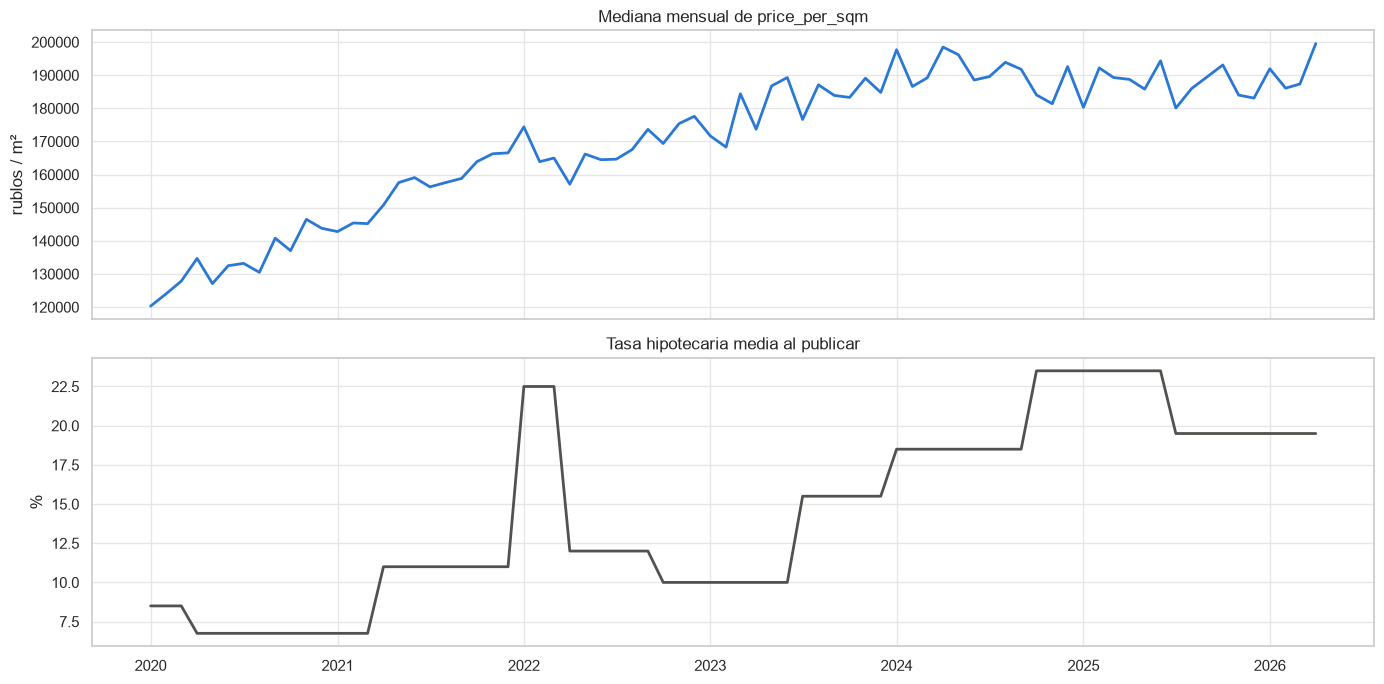

Anuncios por año:
date_posted
2020    7859
2021    7883
2022    7966
2023    7964
2024    7986
2025    7747
2026    2595


In [20]:
mensual = (df.set_index("date_posted")
             .resample("MS")
             .agg(mediana=(TARGET, "median"), tasa=("mortgage_rate_at_listing", "mean"), n=(TARGET, "size")))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(mensual.index, mensual["mediana"], color=COLOR, lw=2)
axes[0].set(title="Mediana mensual de price_per_sqm", ylabel="rublos / m²")
axes[1].plot(mensual.index, mensual["tasa"], color="#52514e", lw=2)
axes[1].set(title="Tasa hipotecaria media al publicar", ylabel="%")
plt.tight_layout(); guardar(fig, "serie_temporal"); plt.show()

print("Anuncios por año:"); print(df["date_posted"].dt.year.value_counts().sort_index().to_string())

**🔧 Qué hace el código**

- `set_index("date_posted")` usa la fecha como índice de la tabla, requisito para `resample`.
- `resample("MS")` agrupa las filas por mes (`MS` = *Month Start*: cada grupo se etiqueta con el primer día del mes).
- `.agg(...)` calcula para cada mes la mediana del precio, la tasa hipotecaria media y la cantidad de anuncios.
- Dos gráficos de líneas, uno debajo del otro, con el **mismo eje X** (`sharex=True`) para compararlos mes a mes. Van en paneles separados porque miden cosas con escalas distintas (rublos y %): ponerlas en un mismo gráfico con dos ejes Y induciría a comparar sus alturas, que no son comparables.
- Al final, la cantidad de anuncios por año.

**📊 Interpretación — evolución en el tiempo**

- **Arriba:** la mediana del precio por m² **sube de forma sostenida** de ~120k (enero 2020) a ~190k (2024) y después **se estanca** entre 180k y 200k. Hay un pequeño bajón a principios de 2022.
- **Abajo:** la tasa hipotecaria cambia **por escalones** (sigue las decisiones del Banco Central de Rusia). Tiene un salto brusco a 22,5% a principios de 2022, vuelve a bajar y después sube de forma sostenida hasta 23,5% a fines de 2024.
- Las dos series **suben juntas en el largo plazo**, por eso la tasa muestra correlación positiva con el precio (0,17). Pero cuando la tasa se duplicó a principios de 2022 (de 11% a 22,5%), el precio prácticamente no se movió (~164k).

**Conclusión:** el modelo necesita una **variable temporal**, porque un mismo departamento vale distinto según cuándo se publicó. Si la tasa influye de verdad o solo acompaña al tiempo se analiza en la celda siguiente.

### 7.1 ¿La tasa hipotecaria influye en el precio, o es el tiempo?

`mortgage_rate_at_listing` tiene correlación positiva con el target. Pero ambas variables suben con los años, así que la correlación podría ser **espuria** (un tercer factor —el tiempo— mueve a las dos). Lo controlamos mirando la correlación *dentro* de cada año.

**🎯 Objetivo de la sección**

Distinguir si la tasa hipotecaria tiene un efecto propio sobre el precio o si solo acompaña al tiempo. **Si no se hace**, se puede incluir una variable espuria con una interpretación económica absurda ("mayor tasa → mayor precio").

**📘 Conceptos de esta sección**

#### Correlación espuria y variable de confusión
- **Qué es:** una **correlación espuria** es una relación estadística entre dos variables que **no se debe a que una cause a la otra**, sino a una tercera variable (**de confusión**) que influye en ambas. Acá, el tiempo hace subir a la vez la tasa hipotecaria y el precio.
- **Para qué sirve detectarla:** evitar incluir en el modelo variables que "parecen" predictivas pero solo reflejan otra cosa, y evitar interpretaciones causales falsas.
- **Cómo se detecta:** **controlando** por la variable de confusión, es decir, mirando la correlación **dentro** de cada nivel de ella (dentro de cada año). Si desaparece, era espuria.
- **Si se detecta:** se incluye la variable de confusión (el tiempo) y se descarta o se trata con cuidado la espuria. Los coeficientes quedan interpretables.
- **Si no se detecta:** el modelo puede asignarle a la tasa un efecto positivo ("a mayor tasa, mayor precio"), una conclusión económicamente absurda. Además, si la tasa y el tiempo entran juntos, se reparten el efecto de forma inestable (multicolinealidad, §9).

#### Controlar por una variable
- **Qué es:** analizar la relación entre A y B **manteniendo fija** una tercera variable C, ya sea comparando dentro de grupos de C o incluyendo C en la regresión.
- **Para qué sirve:** aislar el efecto propio de A sobre B.
- **Si no se hace:** se confunde el efecto de C con el de A.

In [21]:
df_t = df.assign(anio=df["date_posted"].dt.year,
                 t_meses=(df["date_posted"] - df["date_posted"].min()).dt.days / 30.44)

print(f"Correlación global tasa vs target : {df_t['mortgage_rate_at_listing'].corr(df_t[TARGET]):.3f}")
print(f"Correlación global tiempo vs target: {df_t['t_meses'].corr(df_t[TARGET]):.3f}")
print(f"Correlación tasa vs tiempo        : {df_t['mortgage_rate_at_listing'].corr(df_t['t_meses']):.3f}")
print("\nCorrelación tasa vs target dentro de cada año:")
print(df_t.groupby("anio")[["mortgage_rate_at_listing", TARGET]]
          .corr().xs("mortgage_rate_at_listing", level=1)[TARGET].round(3).to_string())
print("\nValores distintos de la tasa:", df_t["mortgage_rate_at_listing"].nunique())

Correlación global tasa vs target : 0.167
Correlación global tiempo vs target: 0.195
Correlación tasa vs tiempo        : 0.828

Correlación tasa vs target dentro de cada año:
anio
2020   -0.07
2021    0.06
2022   -0.00
2023    0.03
2024   -0.02
2025    0.03
2026     NaN

Valores distintos de la tasa: 10


**🔧 Qué hace el código**

- `assign` crea una **copia** de la tabla con dos columnas nuevas, sin modificar `df`: el año (`anio`) y los meses transcurridos desde la primera publicación (`t_meses` = días / 30,44, la duración promedio de un mes).
- Se calculan tres correlaciones globales: tasa–precio, tiempo–precio y tasa–tiempo.
- `groupby("anio")[...].corr()` calcula una matriz de correlación **por cada año**; `.xs(...)` extrae de cada una solo el valor tasa–precio.
- Al final, cuántos valores distintos toma la tasa.

**📊 Interpretación del resultado**

- **Correlaciones globales:** tasa–precio = 0,17 y tiempo–precio = 0,20. Pero **tasa–tiempo = 0,83**: la tasa y el tiempo se mueven casi juntos.
- **Dentro de cada año**, la correlación tasa–precio está entre −0,07 y 0,06, es decir, **prácticamente 0**. Cuando se compara a igual momento, la tasa no tiene relación con el precio. La correlación global es **espuria**: viene del tiempo, que hace subir a ambas.
- **2026 da `NaN`** (no calculable): en todo 2026 la tasa fue la misma (19,5%). Una variable constante tiene desvío 0, y la correlación divide por el desvío.
- **Solo 10 valores distintos:** la tasa cambia por escalones (decisiones del Banco Central). En la práctica funciona como un indicador del **período**, no como una variable con información propia sobre cada departamento.
- **Decisión:** usar una variable de tiempo y **no** incluir la tasa junto con ella.

## 8. Dimensión geográfica

**🎯 Objetivo de la sección**

Ver **dónde** están los departamentos caros y los baratos, y si la ubicación se puede resumir con una sola variable (`to_center_km`) o si hacen falta las coordenadas. Determina qué variables de ubicación usar en el modelo. **Si no se hace**, se podrían incluir `lat` y `lon` como predictoras lineales, y no tienen sentido así: el precio no sube "hacia el norte", sino hacia el centro.

**📘 Conceptos de esta sección**

#### Coordenadas geográficas (latitud y longitud)
- **Qué es:** la **latitud** (`lat`) mide la posición norte-sur y la **longitud** (`lon`), la posición este-oeste. Graficar `lon` en X y `lat` en Y da un mapa aproximado.
- **Para qué sirven:** ubicar cada departamento en el espacio y ver patrones geográficos.
- **Qué implica usarlas directamente en una regresión lineal:** el modelo solo puede aprender "más al norte → más caro (o más barato)" con una pendiente constante. No puede representar "caro en el centro y barato alrededor", que es una relación **en forma de montaña**, no de rampa.
- **Si se reemplazan por la distancia al centro:** la relación de montaña se convierte en una relación monótona (más lejos → más barato), que una regresión sí puede capturar.

#### Dispersión coloreada (mapa de puntos)
- **Qué es:** un diagrama de dispersión en el que el **color** de cada punto representa una tercera variable (acá, el log del precio). La **barra de color** (*colorbar*) indica qué valor corresponde a cada tono.
- **Escala secuencial:** se usa un solo color que va de claro (bajo) a oscuro (alto), porque el precio es una magnitud con orden. Una paleta "arcoíris" haría más difícil leer qué tono es mayor.
- **Por qué log en el color:** con el precio original, unos pocos departamentos muy caros ocuparían casi toda la escala y el resto se vería de un mismo tono claro.
- **Para qué sirve:** ver patrones espaciales (anillos, zonas, grupos aislados) que ninguna tabla muestra.

#### Muestreo para graficar
- Los mapas y las dispersiones usan una **muestra aleatoria de 5.000 filas** (con la semilla del proyecto). Con 50.000 puntos superpuestos el gráfico se vuelve una mancha y tarda en dibujarse. Una muestra aleatoria de ese tamaño conserva la forma de los datos. Los **cálculos** (correlaciones, medianas) se hacen siempre con el dataset completo.

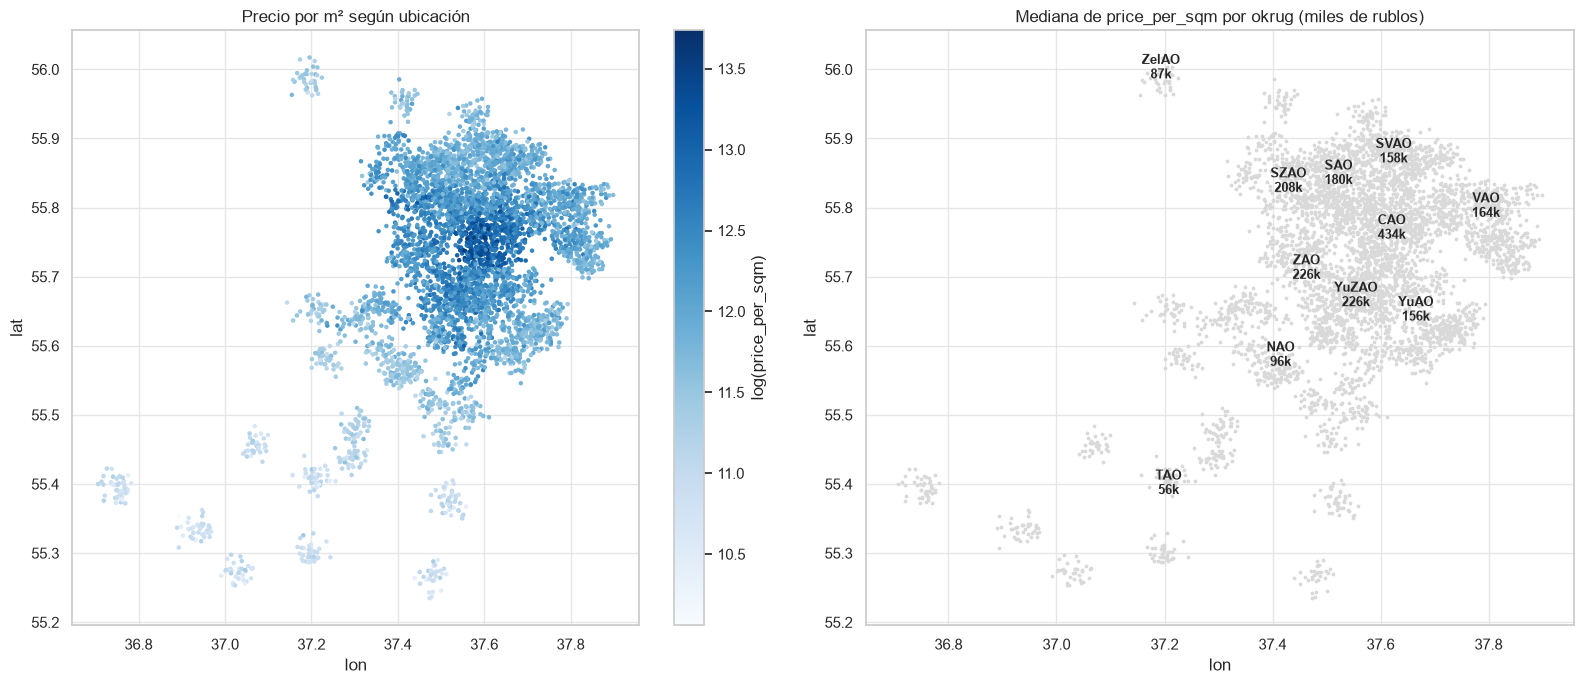

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sc = axes[0].scatter(muestra["lon"], muestra["lat"], c=np.log(muestra[TARGET]), cmap="Blues", s=5)
fig.colorbar(sc, ax=axes[0], label="log(price_per_sqm)")
axes[0].set(title="Precio por m² según ubicación", xlabel="lon", ylabel="lat")

med_ok = df.groupby("okrug").agg(lat=("lat", "median"), lon=("lon", "median"), med=(TARGET, "median"))
axes[1].scatter(muestra["lon"], muestra["lat"], s=3, color="#d9d9d9")
for ok, r in med_ok.iterrows():
    axes[1].annotate(f"{ok}\n{r.med/1000:,.0f}k", (r.lon, r.lat), ha="center", fontsize=9, weight="bold")
axes[1].set(title="Mediana de price_per_sqm por okrug (miles de rublos)", xlabel="lon", ylabel="lat")
plt.tight_layout(); guardar(fig, "mapa_precios"); plt.show()

**🔧 Qué hace el código**

- **Panel izquierdo:** dispersión con `lon` en X y `lat` en Y (forma un mapa). El parámetro `c=` colorea cada punto según su log(precio), con la paleta secuencial `Blues`. `fig.colorbar` agrega la barra de referencia de colores.
- **Panel derecho:** primero dibuja todos los puntos en gris claro, como fondo. Después calcula, para cada okrug, la mediana de lat, lon y precio (`groupby` + `agg`), y con `annotate` escribe el nombre y la mediana en miles en esa posición.

**📊 Interpretación — mapa de precios**

- **Izquierda:** cada punto es un departamento (muestra de 5.000), coloreado por log(precio): más oscuro es más caro. Los precios más altos se concentran en el **centro de Moscú** y se van aclarando hacia afuera, en forma de anillos concéntricos.
- Los **grupos aislados del sudoeste** son la "Nueva Moscú" (TAO y NAO, anexada en 2012): están lejos del centro, tienen poca conexión de metro y son los más baratos.
- **Derecha:** la mediana de cada okrug ubicada en su posición. CAO (434k) en el centro; los okrugs del oeste y sudoeste (ZAO, YuZAO, SZAO: 208k–226k) son más caros que los del este y sur (VAO, YuAO, SVAO: 156k–164k).

**Conclusión:** `lat` y `lon` tienen correlación positiva con el precio, pero **no porque "más al norte = más caro"**: lo que importa es la **cercanía al centro**, y eso ya lo captura `to_center_km` (correlación −0,70 con lat y −0,71 con lon). La regresión lineal no puede modelar "cerca del centro" usando lat/lon directamente, porque esa relación no es lineal en ninguna de las dos coordenadas.

In [23]:
# to_center_km resume buena parte de la ubicación: ¿qué tan relacionadas están lat/lon con la distancia al centro?
print(df[["lat", "lon", "to_center_km", "metro_distance_min"]].corr().round(2))

                     lat   lon  to_center_km  metro_distance_min
lat                 1.00  0.46         -0.70               -0.62
lon                 0.46  1.00         -0.71               -0.65
to_center_km       -0.70 -0.71          1.00                0.90
metro_distance_min -0.62 -0.65          0.90                1.00


**🔧 Qué hace el código**

Calcula la matriz de correlación de Pearson entre las cuatro variables de ubicación.

**📊 Interpretación del resultado**

- **`to_center_km` ↔ `lat` = −0,70 y ↔ `lon` = −0,71:** las coordenadas están fuertemente relacionadas con la distancia al centro. Esto ocurre porque gran parte de los departamentos lejanos están en el sudoeste (TAO/NAO), donde lat y lon son bajas a la vez.
- **`to_center_km` ↔ `metro_distance_min` = 0,90:** casi redundantes. Lejos del centro también hay menos metro.
- **Conclusión:** `to_center_km` resume la información de ubicación que una regresión lineal puede aprovechar. Las coordenadas crudas aportan poco más y su relación con el precio no es lineal. Para capturar diferencias entre zonas a igual distancia (por ejemplo, el oeste más caro que el este) es mejor usar `okrug` o `district`.

## 9. Multicolinealidad entre predictoras

En regresión lineal, predictoras muy correlacionadas entre sí inflan la varianza de los coeficientes y los vuelven inestables e ininterpretables. Lo medimos con la matriz de correlación y el **VIF** (> 10 = problema serio, > 5 = atención).

**🎯 Objetivo de la sección**

Detectar predictoras **redundantes entre sí**. Determina qué variables eliminar o combinar para que los coeficientes de la regresión sean estables e interpretables. **Si no se hace**, el modelo puede predecir bien pero con coeficientes que cambian de signo o de tamaño de forma inexplicable, y no se pueden usar para explicar qué influye en el precio.

**📘 Conceptos de esta sección**

#### Matriz de correlación (mapa de calor)
- **Qué es:** una tabla con la correlación de Pearson entre **todos los pares** de variables, coloreada según su valor (rojo positiva, azul negativa, blanco ≈ 0).
- **Para qué sirve:** ver de un vistazo qué variables se relacionan con el target (última fila) y **cuáles se relacionan entre sí**.
- **Qué permite determinar:** grupos de predictoras redundantes.
- **Si no se hace:** las redundancias aparecen recién en el modelado, como coeficientes con signos o tamaños inexplicables.

#### Multicolinealidad
- **Qué es:** cuando dos o más predictoras están muy correlacionadas **entre sí** (por ejemplo `total_area` y `living_area`, r = 0,96).
- **Para qué sirve detectarla:** en una regresión, cada coeficiente mide el efecto de su variable **manteniendo fijas las demás**. Si dos variables siempre se mueven juntas, el modelo no puede separar el efecto de cada una.
- **Qué implica no tratarla:** los coeficientes se vuelven **inestables** (cambian mucho, e incluso de signo, con pequeños cambios en los datos), sus errores estándar se inflan (variables importantes parecen no significativas) y la interpretación pierde sentido. **La capacidad predictiva casi no se ve afectada**: el problema es de interpretación y estabilidad.
- **Si se trata:** se elimina una de las variables redundantes, se combinan (por ejemplo, en un ratio) o se usa regularización (Ridge). Los coeficientes resultantes son interpretables.

#### VIF (*Variance Inflation Factor*, factor de inflación de la varianza)
- **Qué es:** para cada predictora, se ajusta una regresión de ella contra **todas las demás predictoras** y se calcula VIF = 1 / (1 − R²). Indica cuántas veces se infla la varianza de su coeficiente por estar correlacionada con las otras.
- **Cómo se lee:** VIF = 1, sin colinealidad; > 5, atención; > 10, problema serio. Un VIF de 17,7 significa que la varianza del coeficiente es ~18 veces mayor que si la variable fuera independiente.
- **Para qué sirve:** detectar multicolinealidad **multivariada** (una variable explicada por una combinación de varias), que la matriz de correlación, al mirar solo pares, puede no mostrar.
- **Si se calcula:** se identifican con precisión las variables a eliminar o combinar.
- **Si no se calcula:** se puede pasar por alto colinealidad entre grupos de variables.

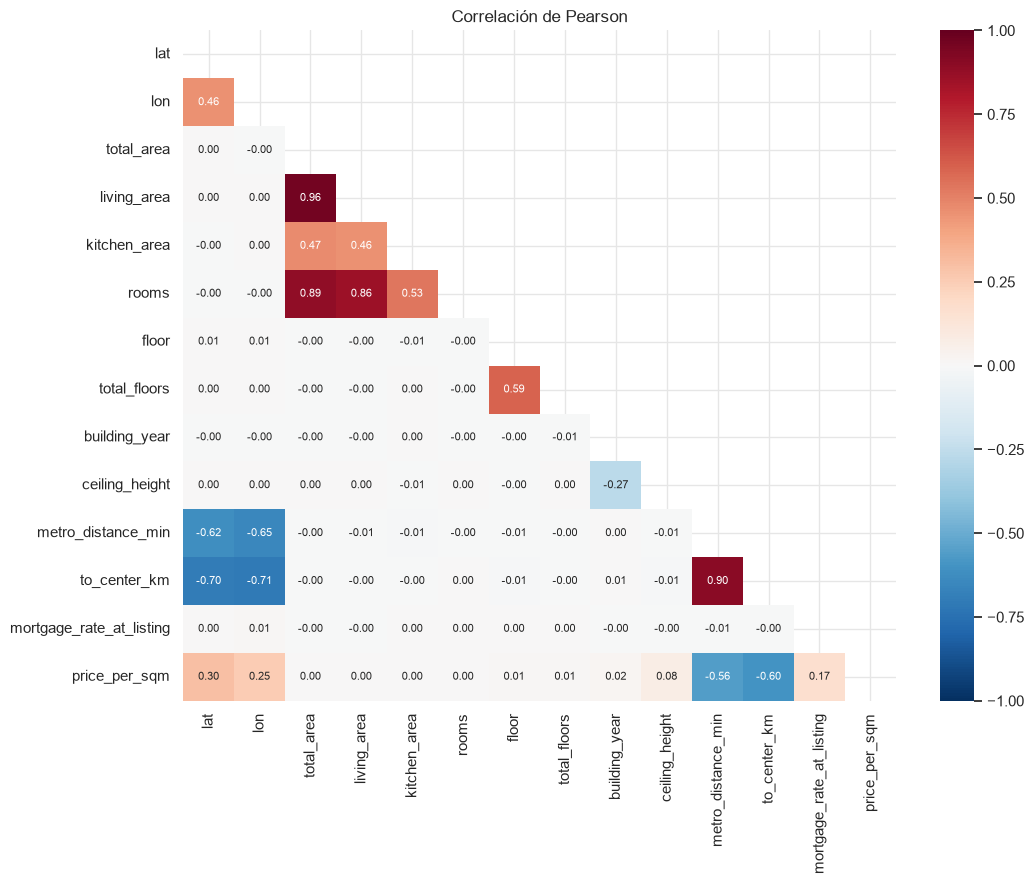

In [24]:
fig, ax = plt.subplots(figsize=(11, 9))
m = df[num_cols + [TARGET]].corr()
sns.heatmap(m, mask=np.triu(np.ones_like(m, dtype=bool)), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlación de Pearson")
plt.tight_layout(); guardar(fig, "correlacion"); plt.show()

**🔧 Qué hace el código**

- `.corr()` calcula la correlación de Pearson entre todos los pares de variables numéricas (incluido el target).
- `sns.heatmap` la dibuja como una grilla de colores. `mask=np.triu(...)` oculta el triángulo superior, porque la matriz es simétrica (la correlación de A con B es la misma que la de B con A). `annot=True` escribe el valor en cada celda.
- La paleta `RdBu_r` es **divergente**: rojo para positivas, azul para negativas y blanco en 0 (`center=0`). La escala fija de −1 a 1 (`vmin`/`vmax`) hace que el color sea comparable entre celdas.

**📊 Interpretación — matriz de correlación**

Rojo = correlación positiva, azul = negativa, blanco = sin relación. Solo se muestra el triángulo inferior porque la matriz es simétrica.

- **Grupo de superficies (problema de multicolinealidad):**
  - `total_area` ↔ `living_area` = **0,96**: casi la misma variable (la living es siempre ~62,5% de la total).
  - `total_area` ↔ `rooms` = 0,89 y `living_area` ↔ `rooms` = 0,86.
- **Grupo de ubicación:** `to_center_km` ↔ `metro_distance_min` = **0,90**: lejos del centro también hay menos metro. Las dos se correlacionan con `lat`/`lon` (−0,62 a −0,71).
- **Otros:** `floor` ↔ `total_floors` = 0,59 (solo hay pisos altos en edificios altos) y `building_year` ↔ `ceiling_height` = −0,27 (los edificios viejos tienen techos más altos).
- **Última fila (relación con el target):** solo las distancias (−0,56 / −0,60), lat/lon (0,30 / 0,25) y la tasa hipotecaria (0,17, espuria según §7.1) tienen correlación apreciable. Todo lo demás está cerca de 0.

**Conclusión:** en la regresión lineal, predictoras muy correlacionadas entre sí producen coeficientes inestables (pueden cambiar de signo de una ejecución a otra) aunque la predicción sea buena. Hay que quedarse con **una variable por grupo** o comparar alternativas. El VIF de la celda siguiente lo cuantifica.

In [25]:
def vif(cols):
    X = df[cols].astype(float).assign(const=1.0)
    return (pd.Series([variance_inflation_factor(X.values, i) for i in range(len(cols))], index=cols)
              .sort_values(ascending=False).rename("VIF"))

vif_todas = vif(num_cols)
vif_todas.to_frame().T

,total_area,living_area,to_center_km,metro_distance_min,rooms,lon,lat,floor,total_floors,kitchen_area,building_year,ceiling_height,mortgage_rate_at_listing
VIF,17.68,14.01,7.52,5.36,5.14,2.03,1.98,1.53,1.53,1.40,1.08,1.08,1.00


**🔧 Qué hace el código**

- La función `vif` arma la matriz de predictoras y le agrega una columna constante (`const = 1`), que representa el intercepto. Sin ella, los VIF salen mal calculados.
- Para cada predictora, `variance_inflation_factor` ajusta una regresión de esa variable contra todas las demás y devuelve 1 / (1 − R²).
- El resultado se ordena de mayor a menor.

**📊 Interpretación del resultado**

- **Problema serio (> 10):** `total_area` (**17,7**) y `living_area` (**14,0**). Son casi la misma variable.
- **Atención (5–10):** `to_center_km` (7,5), `metro_distance_min` (5,4) y `rooms` (5,1). Las dos distancias se explican mutuamente; `rooms` se explica por las superficies.
- **Sin problema (< 2,1):** el resto.
- **Cuidado con `mortgage_rate_at_listing` (VIF = 1,00):** parece independiente, pero solo porque **el tiempo no está entre las variables** de esta tabla. Su colinealidad es con el tiempo (r = 0,83, §7.1). Si en el modelo se agrega una variable temporal, su VIF va a subir. El VIF solo mide colinealidad con las variables incluidas.

In [26]:
# Ratios de superficie: ¿living/kitchen aportan algo más allá de total_area?
print(df[["total_area", "living_area", "kitchen_area", "rooms"]].corr().round(3))
print("\nliving_area / total_area :", (df["living_area"] / df["total_area"]).describe()[["mean", "std"]].round(3).to_dict())

              total_area  living_area  kitchen_area  rooms
total_area          1.00         0.96          0.47   0.89
living_area         0.96         1.00          0.46   0.86
kitchen_area        0.47         0.46          1.00   0.53
rooms               0.89         0.86          0.53   1.00

living_area / total_area : {'mean': 0.625, 'std': 0.043}


**🔧 Qué hace el código**

- Matriz de correlación entre las cuatro variables de tamaño.
- Calcula el cociente `living_area / total_area` para cada departamento y muestra su media y su desvío.

**📊 Interpretación del resultado**

- `total_area` ↔ `living_area` = **0,96**, y `rooms` ↔ `total_area` = 0,89. `kitchen_area` es la menos redundante (0,47 con el total).
- **La superficie habitable es casi siempre el 62,5% de la total**, con un desvío de apenas 4,3 puntos porcentuales. Conociendo `total_area` se conoce prácticamente `living_area`, así que esta última no aporta información nueva.
- **Decisión:** descartar `living_area`. Para `rooms` y `kitchen_area`, comparar en MLflow si aportan algo además de `total_area`.

## 10. Conclusiones del EDA y decisiones para la limpieza y el feature engineering

**🎯 Objetivo de la sección**

Reunir en un solo lugar lo que se encontró y **traducirlo en decisiones concretas** para la limpieza y la ingeniería de variables. Es el puente entre entender los datos y modelarlos: cada decisión de los notebooks siguientes se justifica con un hallazgo de esta tabla, y la columna **Evidencia** indica en qué sección está la prueba. **Si no se hace**, las decisiones de los módulos B y C quedan sin respaldo, y en el informe no se puede explicar por qué se eliminó una variable o se transformó otra.

### Hallazgos

| # | Tema | Hallazgo | Evidencia |
|---|---|---|---|
| 1 | Calidad | Sin nulos ni duplicados. | §3.1 |
| 2 | Calidad | **1.271 filas (2,5%)** con `building_year` posterior al año de publicación (1 a 4 años), todas de edificios modernos: probablemente preventas mal clasificadas, que no corresponden al mercado de reventa. | §3.2 |
| 3 | Calidad | **247 filas (0,5%)** donde living + cocina > superficie total, pero con un exceso chico (mediana 0,8 m²): error menor en `living_area`. | §3.2 |
| 4 | Fuga | `price_rub` = `price_per_sqm × total_area` (ratio 0,998–1,002). Confirmado: no puede ser predictora. | §3.2 |
| 5 | Target | Asimetría 1,69 → **−0,20 en log**; el Q-Q de log es casi recto. El log empareja la varianza entre zonas. Hay un "hombro" de la periferia (TAO, NAO). | §4, §4.1 |
| 6 | Atípicos | 5,4% de atípicos IQR en escala original, **82% de ellos en CAO** (el centro): son departamentos caros reales, no errores. En log bajan a 2,2%. | §4.2 |
| 7 | Distancia | `to_center_km` y `metro_distance_min` son las predictoras más fuertes, con relación **no lineal** (Spearman −0,75 / −0,72 > Pearson −0,60 / −0,56). En log-log, Pearson sube a **−0,82** / −0,72. | §5.2 |
| 8 | Tamaño | `total_area`, `rooms`, pisos y `building_year` **no se relacionan** con el precio por m² (\|r\| < 0,03). `ceiling_height` muestra una tendencia por su vínculo con los edificios "stalin". | §5.2 |
| 9 | Ubicación | `district` explica por sí solo **R² = 0,77** (ε² = 0,76); `okrug` ε² = 0,58. `district` está anidado en `okrug`. Todos los distritos tienen ≥ 340 filas. `metro_station` explica solo R² = 0,05. | §6 |
| 10 | Categóricas | Efecto moderado: `metro_distance_type` (ε² 0,19), `renovation` (0,05), `building_type` (0,04). Efecto nulo o despreciable: `seller_type` (p = 0,42), `has_balcony` (0,001), `metro_line` (0,005). | §6.1 |
| 11 | Tiempo | La mediana sube de ~133k (2020) a ~190k (2024–2026). 2026 está incompleto (hasta abril). | §7 |
| 12 | Espuria | `mortgage_rate_at_listing` correlaciona 0,17 con el target, pero **0,83 con el tiempo**, y dentro de cada año su correlación es ≈ 0. Su efecto es el del tiempo. Solo tiene 10 valores distintos. | §7.1 |
| 13 | Colinealidad | `total_area` (VIF 17,7) y `living_area` (VIF 14,0) tienen r = 0,96: `living_area` es casi siempre el 62,5% de `total_area`. `rooms` tiene r = 0,89 con `total_area`. Las dos distancias tienen r = 0,90. | §9 |

### Decisiones para el módulo B (limpieza, §11) y el módulo C (feature engineering, §12)

1. **Excluir** `id` y `price_rub` (ya en `config.EXCLUDED_COLS`).
2. **Filas inconsistentes:** eliminar las 1.271 con `building_year` posterior a la publicación (hallazgo 2). **Conservar** las 247 de superficie (hallazgo 3): el error es chico y solo afecta a `living_area`, que se descarta (decisión 8).
3. **No eliminar atípicos por IQR**: son reales y están concentrados en el centro. Modelar `log(price_per_sqm)` los vuelve manejables.
4. **Target**: entrenar sobre `log(price_per_sqm)` y reportar métricas también en rublos.
5. **Distancias**: usar `log1p(to_center_km)` y `log1p(metro_distance_min)`. Por su r = 0,90, comparar en MLflow un modelo con las dos y otro con una sola.
6. **Ubicación**: one-hot de `district` (con ≥ 340 filas por categoría es viable) **o** de `okrug`, no los dos juntos sin regularización. Probar ambas variantes. No usar `metro_station`.
7. **Tiempo**: agregar una variable temporal (meses desde enero 2020, o año). **No usar** `mortgage_rate_at_listing` junto con el tiempo: es redundante y confunde la interpretación.
8. **Superficies**: descartar `living_area` (redundante con `total_area`). Aunque las de tamaño muestran correlación nula con el target, se dejan para el baseline y se evalúa si aportan.
9. **Categóricas débiles**: `seller_type` y `has_balcony` son candidatas a eliminarse; como cuestan una columna cada una, se confirma comparando ejecuciones en MLflow. `metro_line` se descarta directamente (§12.8): costaría 11 columnas a cambio de un efecto casi nulo.

Siguiente: módulo B, §11.

---
# MÓDULO B — LIMPIEZA DE DATOS

## 11. Limpieza de datos

**🎯 Objetivo del módulo**

Aplicar las decisiones del EDA (§10) para obtener un dataset **confiable**: sin columnas que no pueden usarse y sin filas que no representan el problema que se quiere modelar. El EDA **diagnostica**; la limpieza **actúa** sobre ese diagnóstico. Cada acción tiene que poder justificarse con un hallazgo concreto.

- **Para qué sirve:** que el modelo aprenda de datos que representen correctamente el mercado de **reventa** de Moscú.
- **Qué permite determinar:** con qué filas y columnas se trabaja de acá en adelante, y cuánta información se pierde en el proceso.
- **Si se hace bien:** el modelo aprende relaciones reales y sus resultados se pueden defender.
- **Si no se hace:** el modelo aprende de errores y de casos que no corresponden al problema (las preventas). **Si se hace de más** (por ejemplo, borrando todos los atípicos), el modelo pierde justamente los casos que debería saber predecir.

**📘 Conceptos del módulo**

#### Inmutabilidad de los datos originales
- **Qué es:** el principio de **no modificar nunca** el archivo original (`data/raw/`). Toda limpieza se aplica sobre una **copia** en memoria y el resultado se guarda en otro archivo (`data/processed/`).
- **Para qué sirve:** que el proceso sea **reproducible** y **reversible**. Si una decisión resulta equivocada, se cambia el código y se vuelve a correr desde el original.
- **Si no se respeta:** un error de limpieza se vuelve permanente y nadie puede reconstruir los datos de partida ni verificar lo que se hizo.

#### Trazabilidad (registro de limpieza)
- **Qué es:** anotar cada paso con **cuántas filas y columnas había antes y después**, y por qué.
- **Para qué sirve:** cuantificar cuánta información se pierde en cada decisión y documentarla para el informe.
- **Si no se hace:** no se puede saber qué paso eliminó qué filas. Una limpieza que borra el 30% de los datos puede pasar desapercibida.

#### Eliminar, corregir, imputar o conservar
Ante un dato problemático hay cuatro opciones:
- **Eliminar** la fila: cuando el dato es irrecuperable o no pertenece a la población que se quiere modelar. Costo: se pierde información.
- **Corregir** el valor: solo cuando se conoce con certeza el valor correcto (por ejemplo, un error de unidades evidente). Si se "corrige" sin certeza, se inventan datos.
- **Imputar** (rellenar con un valor estimado, como la mediana): para valores faltantes, cuando eliminar las filas costaría demasiada información. Costo: reduce artificialmente la variabilidad.
- **Conservar:** cuando el valor "raro" es real, o cuando el error afecta solo a una columna que no se va a usar.

#### Sesgo de selección
- **Qué es:** cuando las filas eliminadas **no son un subconjunto al azar**, sino que se concentran en un grupo (una zona, un tipo de edificio). Entonces el dataset limpio deja de representar a la población.
- **Para qué sirve controlarlo:** verificar que la limpieza no cambie la composición del dataset de una forma que distorsione el modelo.
- **Cómo se controla:** comparando distribuciones (mediana del target y proporciones por grupo) **antes y después** de cada eliminación (§11.2).

In [27]:
# Copia de trabajo: df (los datos tal como se leyeron) no se modifica.
limpio = df.copy()
registro = []

def registrar(paso, motivo, antes, despues):
    """Anota un paso de limpieza: filas/columnas antes y después, y su justificación."""
    registro.append({"paso": paso, "motivo": motivo,
                     "filas antes": antes.shape[0], "filas después": despues.shape[0],
                     "columnas antes": antes.shape[1], "columnas después": despues.shape[1]})

print("Copia de trabajo:", limpio.shape)

Copia de trabajo: (50000, 26)


**🔧 Qué hace el código**

- `df.copy()` crea una **copia independiente** de la tabla. Sin `.copy()`, `limpio` sería solo otro nombre para el mismo objeto y modificarlo modificaría también `df`.
- `registro` es una lista vacía donde se va a anotar cada paso.
- La función `registrar` recibe la tabla antes y después de un paso y guarda sus dimensiones (`.shape[0]` = filas, `.shape[1]` = columnas) junto con el motivo.

**📊 Interpretación del resultado**

La copia tiene las mismas 50.000 filas y 26 columnas que el original. A partir de acá, todo cambio se hace sobre `limpio`.

### 11.1 Eliminar identificadores y columnas con fuga de datos

**Decisión 1 del EDA.** Se eliminan:
- **`id`:** es un **identificador**, un código único por anuncio (S000001, S000002…). No describe ninguna característica del departamento, así que no puede tener relación causal con el precio. Si se incluyera, el modelo podría "memorizar" anuncios en vez de aprender patrones (y, codificado, generaría 50.000 columnas).
- **`price_rub`:** contiene el target (§3.2, fuga de datos). En el momento de predecir no se conoce el precio total; si se conociera, no haría falta el modelo.

In [28]:
antes = limpio
limpio = limpio.drop(columns=config.EXCLUDED_COLS)
registrar("Eliminar id y price_rub", "Identificador y fuga de datos (§3.2)", antes, limpio)

print("Columnas eliminadas:", config.EXCLUDED_COLS)
print("Dimensiones:", antes.shape, "→", limpio.shape)

Columnas eliminadas: ['id', 'price_rub']
Dimensiones: (50000, 26) → (50000, 24)


**🔧 Qué hace el código**

- `drop(columns=...)` devuelve una tabla nueva sin las columnas indicadas. Se usa la lista de `config.EXCLUDED_COLS`, la misma que usó el EDA para no tratarlas como predictoras.
- Se registra el paso y se muestran las dimensiones antes y después.

**📊 Interpretación del resultado**

Se pasa de 26 a **24 columnas**. No se pierde ninguna fila: excluir columnas no reduce la cantidad de observaciones.

### 11.2 Eliminar filas con año de construcción posterior a la publicación

**Decisión 2 del EDA.** Las 1.271 filas con `building_year` mayor que el año de publicación (§3.2) son todas de edificios modernos (`modern_panel` y `monolith`), entre 1 y 4 años "en el futuro".

**¿Por qué eliminar y no corregir?**
- **No se puede corregir con certeza:** no se sabe si el error está en el año de construcción, en la fecha del anuncio o en la clasificación del mercado.
- **Lo más probable es que sean preventas** (departamentos en construcción). Sus precios responden a otra lógica (se paga antes de recibir el departamento, con descuento), así que **no pertenecen a la población** que se quiere modelar: la reventa.
- **El costo es bajo:** es el 2,5% de los datos.

Después de eliminar, se verifica que no se haya introducido un **sesgo de selección**.

In [29]:
antes = limpio
anio_pub = limpio["date_posted"].dt.year
limpio = limpio[limpio["building_year"] <= anio_pub]
registrar("Eliminar building_year > año de publicación",
          "Inconsistentes con un mercado de reventa; probables preventas (§3.2)", antes, limpio)
print(f"Filas eliminadas: {len(antes) - len(limpio):,} ({(len(antes) - len(limpio)) / len(antes):.1%})")

# Control de sesgo de selección: ¿cambió la composición del dataset?
print(f"\nMediana de {TARGET}: antes {antes[TARGET].median():,.0f} | después {limpio[TARGET].median():,.0f}")

comp = pd.DataFrame({
    "% antes":   antes["okrug"].value_counts(normalize=True) * 100,
    "% después": limpio["okrug"].value_counts(normalize=True) * 100,
})
comp["diferencia (pp)"] = comp["% después"] - comp["% antes"]
print("\nComposición por okrug:")
print(comp.round(2).sort_values("diferencia (pp)").to_string())

comp_bt = pd.DataFrame({
    "% antes":   antes["building_type"].value_counts(normalize=True) * 100,
    "% después": limpio["building_type"].value_counts(normalize=True) * 100,
})
comp_bt["diferencia (pp)"] = comp_bt["% después"] - comp_bt["% antes"]
print("\nComposición por tipo de edificio:")
print(comp_bt.round(2).sort_values("diferencia (pp)").to_string())

Filas eliminadas: 1,271 (2.5%)

Mediana de price_per_sqm: antes 170,400 | después 170,900

Composición por okrug:
       % antes  % después  diferencia (pp)
okrug                                     
ZAO       9.23       9.22            -0.02
TAO       7.90       7.88            -0.02
CAO       7.80       7.78            -0.02
YuAO     12.44      12.43            -0.01
NAO       8.33       8.32            -0.01
SVAO     13.32      13.32            -0.00
SZAO      6.84       6.84            -0.00
ZelAO     0.72       0.72             0.00
SAO      11.71      11.73             0.01
VAO      12.18      12.20             0.02
YuZAO     9.52       9.57             0.05

Composición por tipo de edificio:
               % antes  % después  diferencia (pp)
building_type                                     
modern_panel     19.96      19.18            -0.79
monolith         19.99      19.21            -0.78
stalin            7.03       7.21             0.18
khrushchev       15.06      15.45    

**🔧 Qué hace el código**

- `limpio[condición]` es un **filtro booleano**: conserva solo las filas donde la condición es `True`, es decir, edificios construidos en el año de publicación o antes.
- Se calcula cuántas filas se eliminaron y qué porcentaje representan.
- **Control de sesgo:** se compara la mediana del target y la composición porcentual por `okrug` y por `building_type` antes y después. La columna "diferencia (pp)" está en **puntos porcentuales**: la resta directa entre dos porcentajes (de 20,0% a 19,2% son −0,8 pp).

**📊 Interpretación del resultado**

- Se eliminan **1.271 filas (2,5%)** y quedan **48.729**.
- **Mediana del target:** prácticamente igual (170.400 → 170.900, un 0,3%). La eliminación no desplazó el nivel de precios.
- **Por okrug:** ninguna zona cambia más de 0,05 pp. Las filas eliminadas estaban **repartidas de forma pareja** entre zonas, así que no hay sesgo geográfico.
- **Por tipo de edificio:** `modern_panel` y `monolith` bajan ~0,8 pp cada uno, porque las filas eliminadas eran de esos tipos. Es un cambio **esperable y chico**: los dos siguen representando ~19% de los datos, con miles de observaciones.
- **Conclusión:** la limpieza **no introduce un sesgo de selección relevante**.

### 11.3 Decisiones que no modifican los datos

Dos hallazgos del EDA se resolvieron **conservando** las filas. Documentar las decisiones de "no hacer nada" es tan importante como documentar las que cambian los datos: sin ese registro, alguien podría pensar que el problema no se vio.

- **Atípicos del target (decisión 3):** se conservan. El 82% está en CAO y son departamentos realmente caros (§4.2). Su influencia se reduce modelando en log (§12.1).
- **Living + cocina > total (247 filas en el EDA; 242 después de §11.2, porque 5 eran preventas):** se conservan. El exceso es chico (mediana 0,8 m²) y afecta solo a `living_area`, que se descarta en el feature engineering por redundante (§12.8). El target y `total_area` de esas filas no están afectados.

La celda siguiente verifica que estas filas siguen en el dataset y que los rangos de las variables son plausibles.

In [30]:
print("Filas con living + cocina > total que se conservan:",
      int((limpio["living_area"] + limpio["kitchen_area"] > limpio["total_area"]).sum()))
print("Atípicos IQR del target que se conservan          :", int(outliers_iqr(limpio[TARGET]).sum()))

# Rangos de las variables numéricas principales: ¿son físicamente plausibles?
cols_rango = [TARGET, "total_area", "kitchen_area", "rooms", "floor", "total_floors",
              "building_year", "ceiling_height", "metro_distance_min", "to_center_km"]
limpio[cols_rango].agg(["min", "max"]).T

Filas con living + cocina > total que se conservan: 242
Atípicos IQR del target que se conservan          : 2627


,min,max
price_per_sqm,"23,400.00","1,239,100.00"
total_area,20.90,134.30
kitchen_area,6.00,24.80
rooms,1.00,5.00
floor,1.00,25.00
total_floors,5.00,25.00
building_year,"1,935.00","2,024.00"
ceiling_height,2.50,3.50
metro_distance_min,2.00,328.00
to_center_km,0.07,70.55


**🔧 Qué hace el código**

- Cuenta cuántas filas con el problema de superficie siguen en el dataset, y cuántos atípicos detecta el criterio IQR (reutiliza la función `outliers_iqr` definida en §4.2).
- `agg(["min", "max"])` calcula el mínimo y el máximo de cada columna; `.T` **transpone** la tabla (filas ↔ columnas) para que cada variable quede en una fila.

**📊 Interpretación del resultado**

- Siguen en el dataset las **242** filas con el problema de superficie (de las 247 del EDA, 5 se eliminaron en §11.2 por ser preventas) y los **2.627** atípicos IQR del target, como se decidió.
- **Todos los rangos son plausibles:** superficies de 20,9 a 134,3 m², de 1 a 5 ambientes, pisos de 1 a 25, edificios de 1935 a 2024, techos de 2,5 a 3,5 m, distancias de 0,07 a 70,6 km del centro. No aparece ningún valor imposible (negativos, ceros, techos de 10 m) que exija otra acción.

### 11.4 Verificación final y guardado del dataset limpio

In [31]:
print("Nulos en el dataset limpio      :", int(limpio.isna().sum().sum()))
print("Filas duplicadas                :", int(limpio.duplicated().sum()))
print("Dimensiones finales             :", limpio.shape)
print(f"Filas conservadas del original  : {len(limpio) / len(df):.1%}")

limpio = limpio.reset_index(drop=True)
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
limpio.to_csv(config.CLEAN_CSV, index=False)
print("\nGuardado en:", config.CLEAN_CSV.relative_to(config.ROOT))

pd.DataFrame(registro)

Nulos en el dataset limpio      : 0
Filas duplicadas                : 0
Dimensiones finales             : (48729, 24)
Filas conservadas del original  : 97.5%



Guardado en: data/processed/secondary_clean.csv


,paso,motivo,filas antes,filas después,columnas antes,columnas después
0,Eliminar id y price_rub,Identificador y fuga de datos (§3.2),50000,50000,26,24
1,Eliminar building_year > año de publicación,Inconsistentes con un mercado de reventa; prob...,50000,48729,24,24


**🔧 Qué hace el código**

- Repite los controles de calidad de §3.1 sobre el resultado, para confirmar que la limpieza no generó nulos ni duplicados.
- `reset_index(drop=True)` renumera las filas de 0 a 48.728. Al filtrar quedan "huecos" en la numeración (los índices de las filas eliminadas), y `drop=True` evita que el índice viejo se guarde como una columna.
- `to_csv(..., index=False)` guarda el dataset limpio en `data/processed/secondary_clean.csv`, sin la columna de índice.
- Al final se muestra el **registro de limpieza** completo.

**📊 Interpretación del resultado**

- El dataset limpio tiene **48.729 filas y 24 columnas**, sin nulos ni duplicados, y conserva el **97,5%** de las filas originales.
- El **registro** resume los dos pasos que modificaron los datos, con su motivo y su efecto. Es la tabla que se puede incluir directamente en el informe.
- El archivo `data/raw/secondary_market.csv` **no se modificó**.

---
# MÓDULO C — INGENIERÍA DE VARIABLES (FEATURE ENGINEERING)

## 12. Ingeniería de variables

**🎯 Objetivo del módulo**

Transformar las columnas del dataset limpio en las **variables que va a recibir el modelo** (*features*). La regresión lineal solo entiende números y solo modela relaciones **lineales**. Este módulo adapta los datos a esas dos condiciones: convierte las categorías en números, transforma las relaciones curvas en rectas, crea variables que capturan efectos que las columnas originales no expresan bien y descarta las redundantes o espurias.

- **Para qué sirve:** suele ser la etapa que **más mejora un modelo lineal**, más que cambiar de algoritmo. La misma regresión con buenas variables puede pasar de malas a muy buenas predicciones.
- **Qué permite determinar:** la **matriz de diseño** final, es decir, exactamente qué columnas (y en qué forma) entran al modelo.
- **Si se hace:** el modelo puede aprovechar relaciones no lineales (distancias), efectos de categorías (zona) y efectos de tiempo, con coeficientes interpretables.
- **Si no se hace:** la regresión ni siquiera puede usar las variables de texto (da error), modela con una recta relaciones que son curvas y se ve afectada por la multicolinealidad y las variables espurias.

**📘 Conceptos del módulo**

#### Feature (variable predictora) y matriz de diseño
- **Feature:** cada columna que el modelo usa para predecir. Puede ser una columna original (`total_area`), una transformada (`log1p_to_center_km`) o una creada a partir de otras (`building_age`).
- **Matriz de diseño (X):** la tabla final de features, con una fila por observación y solo valores numéricos. El target (y) va por separado.

#### Transformaciones sin estado vs. con estado
- **Sin estado:** se calculan **fila por fila**, con una regla fija que no depende de los demás datos: log(x), "¿es primer piso?", el año de una fecha, codificar una categoría como 0/1. Dan el mismo resultado sin importar qué otras filas haya.
- **Con estado:** **aprenden un parámetro de los datos**. Por ejemplo, la estandarización (restar la media y dividir por el desvío) necesita calcular la media y el desvío; una imputación con la mediana necesita calcular la mediana.
- **Por qué importa:** las transformaciones con estado tienen que **aprender sus parámetros solo del conjunto de entrenamiento** (ver el concepto siguiente). Por eso **todo este módulo usa solo transformaciones sin estado**, que se pueden aplicar al dataset completo sin riesgo. Las transformaciones con estado (estandarización) quedan para el módulo de modelado (§14), dentro de un *Pipeline* de scikit-learn que las ajusta solo con los datos de entrenamiento.

#### Fuga de datos en la ingeniería de variables y división entrenamiento/prueba
- **Qué es:** para evaluar un modelo de forma honesta, los datos se dividen en **entrenamiento** (con los que el modelo aprende) y **prueba** (que el modelo nunca ve, y que simulan datos futuros). Hay fuga si información del conjunto de prueba llega al entrenamiento. Por ejemplo: estandarizar con la media de **todo** el dataset hace que esa media incluya los datos de prueba.
- **Para qué sirve evitarla:** que las métricas del conjunto de prueba reflejen el rendimiento real con datos nuevos.
- **Si no se evita:** las métricas salen optimistas y el modelo rinde peor en la práctica de lo que se reportó.
- **Cómo se maneja acá:** (1) solo transformaciones sin estado; (2) las categorías del one-hot se conocen de antemano y no dependen del target; (3) la división entrenamiento/prueba y la estandarización se hacen en el módulo de modelado (§14).
- **Una salvedad honesta:** algunas decisiones de este módulo (qué variables crear o descartar) se tomaron mirando todo el dataset en el EDA. Con 48.729 filas y pocas decisiones el riesgo es bajo, pero por eso la evaluación final **siempre** se hace sobre el conjunto de prueba.

#### Efecto ajustado por distrito
- **Qué es:** algunas celdas de este módulo comparan grupos **dentro del mismo distrito**. Para cada fila se calcula log(precio) − promedio de log(precio) de su distrito. Ese valor (un **residuo**) indica si el departamento es más caro o más barato **que lo normal en su zona**. El promedio de ese residuo por grupo es el efecto del grupo "a igual ubicación". Como está en escala log, 0,05 equivale a aproximadamente +5%.
- **Para qué sirve:** la ubicación domina el precio (R² = 0,77) y puede **tapar** o **inventar** efectos. Si los primeros pisos abundaran en zonas baratas, parecerían más baratos aunque el piso no influyera. Ajustar por distrito aísla el efecto propio de la variable.
- **Si no se hace:** se crean o descartan variables por efectos que en realidad son de la ubicación.

In [32]:
feats = limpio.copy()
y_log_l = np.log(feats[TARGET])
# Residuo respecto del promedio del distrito: efecto "a igual ubicación" (ver concepto arriba)
resid_distrito = y_log_l - y_log_l.groupby(feats["district"]).transform("mean")

def efecto_ajustado(grupo, nombre):
    """Promedio del residuo por distrito para cada valor de `grupo` (≈ % de diferencia de precio)."""
    return (resid_distrito.groupby(grupo).agg(["mean", "size"])
            .rename(columns={"mean": "efecto (log)", "size": "filas"})
            .rename_axis(nombre))

print("Dataset de partida:", feats.shape)

Dataset de partida: (48729, 24)


**🔧 Qué hace el código**

- `feats` es una copia del dataset limpio, sobre la que se construyen las features.
- `resid_distrito` calcula para cada fila su log(precio) menos el promedio de log(precio) de su distrito. `transform("mean")` le asigna a cada fila el promedio de su grupo.
- La función `efecto_ajustado` agrupa ese residuo por una variable y devuelve su promedio (el efecto) y la cantidad de filas de cada grupo.

### 12.1 Target: `log_price_per_sqm`

**Decisión 4 del EDA.** El modelo se entrena sobre **log(precio por m²)** en lugar del precio en rublos.

**Justificación (evidencia de §4 y §4.1):**
- La asimetría baja de 1,69 a −0,20 y el Q-Q plot queda casi recto.
- El log **empareja la varianza** entre zonas: en rublos, CAO tiene un desvío 9 veces mayor que TAO; en log son casi iguales. Eso acerca el modelo al supuesto de **homocedasticidad**.
- Los coeficientes se interpretan como **cambios porcentuales**: un coeficiente de 0,05 significa aproximadamente +5% de precio.

**📘 Concepto: volver a la escala original (*back-transform*)**
- **Qué es:** el modelo predice log(precio); para obtener rublos se aplica la función inversa, `exp()`.
- **Qué implica:** exp(predicción en log) estima la **mediana** del precio, no la media, porque el promedio de los logaritmos es menor que el logaritmo del promedio (desigualdad de Jensen). Para datos asimétricos la mediana es, de todos modos, el valor "típico" más representativo.
- **Para el informe:** las métricas se reportan **en las dos escalas**. En log, porque es lo que optimiza el modelo; en rublos, porque es lo que se entiende en la práctica.

Se conserva la columna original `price_per_sqm` para poder calcular las métricas en rublos.

In [33]:
feats[config.TARGET_LOG] = np.log(feats[TARGET])
feats[[TARGET, config.TARGET_LOG]].describe().T[["mean", "50%", "std", "min", "max"]]

,mean,50%,std,min,max
price_per_sqm,"196,114.84","170,900.00","113,589.94","23,400.00","1,239,100.00"
log_price_per_sqm,12.04,12.05,0.56,10.06,14.03


**🔧 Qué hace el código**

- Crea la columna `log_price_per_sqm` con el logaritmo natural del precio. El nombre viene de `config.TARGET_LOG`, para que el módulo de modelado (§14) use exactamente el mismo.
- Muestra el resumen de las dos versiones.

**📊 Interpretación del resultado**

- En log, la media (≈ 12,04) y la mediana (≈ 12,05) son casi iguales: es la simetría que se buscaba.
- El rango pasa de 23.400–1.239.100 rublos (53 veces) a 10,06–14,03 en log: la escala se comprime y los departamentos más caros dejan de ser valores extremos.

### 12.2 Distancias: `log1p_to_center_km` y `log1p_metro_distance_min`

**Decisión 5 del EDA.** Las dos distancias tienen una relación **curva** con el precio: cae rápido en los primeros kilómetros o minutos y después se aplana (§5.2). Una recta no puede representar esa forma. En log-log la relación se vuelve aproximadamente lineal.

**Por qué `log1p` y no `log`:** `log1p(x) = log(1 + x)` está definido en 0. Aunque hoy la distancia mínima es 0,07 km, un departamento nuevo podría estar a 0 km, y `log(0)` da −∞, lo que rompería el modelo.

**Interpretación del coeficiente en log-log:** se lee como una **elasticidad**. Un coeficiente de −0,3 significa que un 10% más de distancia se asocia con ~3% menos de precio por m².

In [34]:
for col in ["to_center_km", "metro_distance_min"]:
    feats[f"log1p_{col}"] = np.log1p(feats[col])

comparacion = pd.DataFrame({
    "Pearson original vs log(y)":    [feats[c].corr(feats[config.TARGET_LOG]) for c in ["to_center_km", "metro_distance_min"]],
    "Pearson log1p vs log(y)":       [feats[f"log1p_{c}"].corr(feats[config.TARGET_LOG]) for c in ["to_center_km", "metro_distance_min"]],
    "Efecto ajustado por distrito":  [np.corrcoef(feats[f"log1p_{c}"], resid_distrito)[0, 1] for c in ["to_center_km", "metro_distance_min"]],
}, index=["to_center_km", "metro_distance_min"])
comparacion.round(3)

,Pearson original vs log(y),Pearson log1p vs log(y),Efecto ajustado por distrito
to_center_km,-0.78,-0.81,-0.01
metro_distance_min,-0.74,-0.72,-0.18


**🔧 Qué hace el código**

- Crea una columna `log1p_<nombre>` por cada distancia.
- Compara tres correlaciones con log(precio): la variable original, la transformada y la transformada contra el residuo por distrito, es decir, **cuánto aporta la variable dentro de un mismo distrito**.

**📊 Interpretación del resultado**

- **La transformación mejora la relación lineal:** `to_center_km` pasa de ≈ −0,78 a **≈ −0,81**. `metro_distance_min` queda parecida (≈ −0,74 → −0,72), pero su forma se vuelve recta (§5.2).
- **Hallazgo nuevo (efecto ajustado):** dentro de un mismo distrito, `to_center_km` **casi no aporta** (≈ −0,01), mientras que `metro_distance_min` **sí** (≈ −0,18). Tiene sentido: el distrito ya indica qué tan lejos del centro está el departamento, pero dentro del distrito todavía importa qué tan cerca queda del metro.
- **Implicación para el modelado:** si se usa `district`, `log1p_to_center_km` es casi redundante. Si se usa `okrug` (zonas más grandes), las dos distancias aportan. Se crean las dos y la elección se hace por conjunto de variables (§12.10).

### 12.3 Tiempo: año de publicación (`year_*`) y meses transcurridos (`t_months`)

**Decisión 7 del EDA.** El precio sube de 2020 a 2024 y después **se estanca** (§7). El modelo necesita una variable temporal, y hay dos formas de representarla:

**📘 Concepto: tendencia lineal vs. efectos por período**
- **`t_months` (numérica):** meses desde enero de 2020. El modelo le asigna **una sola pendiente**, la misma suba por mes durante todo el período.
  - Ventaja: una sola columna, fácil de interpretar ("+X% por mes").
  - Desventaja: **no puede representar el estancamiento** de 2024–2026. Predeciría que el precio sigue subiendo al mismo ritmo.
- **`year` como categórica (one-hot, §12.7):** una columna 0/1 por año. El modelo estima un **nivel distinto para cada año**, sin suponer ninguna forma.
  - Ventaja: captura cualquier patrón (suba, estancamiento, caída).
  - Desventaja: más columnas (6 en lugar de 1) y no sirve para extrapolar a años que no están en los datos.
- **Decisión:** se crean las dos. El conjunto de variables principal usa el año (captura el estancamiento) y se compara contra `t_months` en MLflow.

**Por qué no se usa `mortgage_rate_at_listing`:** su relación con el precio es espuria (§7.1). Con el tiempo en el modelo no aporta información propia, y lo único que haría es generar colinealidad.

In [35]:
feats["year"] = feats["date_posted"].dt.year
feats["t_months"] = (feats["date_posted"] - pd.Timestamp("2020-01-01")).dt.days / 30.44

print("Media de log(precio) por año (sube hasta 2024 y se estanca):")
print(feats.groupby("year")[config.TARGET_LOG].mean().round(3).to_string())
print(f"\nt_months: de {feats['t_months'].min():.1f} a {feats['t_months'].max():.1f}")

Media de log(precio) por año (sube hasta 2024 y se estanca):
year
2020   11.79
2021   11.95
2022   12.02
2023   12.11
2024   12.15
2025   12.13
2026   12.16

t_months: de 0.0 a 75.9


**🔧 Qué hace el código**

- `year` extrae el año de la fecha de publicación.
- `t_months` resta a cada fecha el 1° de enero de 2020 (el inicio del dataset), obtiene la diferencia en días (`.dt.days`) y la divide por 30,44 (la duración media de un mes). Se usa una fecha **fija** y no el mínimo de los datos para que la transformación sea **sin estado**: un dato nuevo se transforma igual, sin depender de las demás filas.
- Muestra la media de log(precio) por año.

**📊 Interpretación del resultado**

- La media de log(precio) sube de ≈ 11,79 (2020) a ≈ 12,15 (2024) y después queda plana (≈ 12,13–12,16 en 2025–2026). En log, una diferencia de 0,37 equivale a **~45% de aumento** entre 2020 y 2024.
- El estancamiento confirma que una sola pendiente (`t_months`) no alcanza para describir el período completo, y justifica usar el año como categórica.
- `t_months` va de 0 (enero 2020) a ≈ 75,9 (fines de abril 2026).

### 12.4 Antigüedad del edificio: `building_age` (reemplaza a `building_year`)

**📘 Concepto: variable derivada**
- **Qué es:** una variable nueva que se calcula combinando columnas existentes para expresar mejor un concepto. Acá: antigüedad = año de publicación − año de construcción.
- **Para qué sirve:** lo que importa para el precio es **qué tan viejo es el edificio cuando se vende**, no el año en sí. Un edificio de 2000 tiene 20 años en un anuncio de 2020, pero 25 en uno de 2025.

**¿Por qué reemplaza a `building_year` y no se suma?**
- antigüedad = año de publicación − año de construcción es una **combinación lineal exacta** de dos variables. Si el modelo tuviera las tres (antigüedad, año de construcción y año de publicación como número), tendría **colinealidad perfecta**: una se calcula exactamente a partir de las otras y los coeficientes no se pueden estimar.
- Se conserva la antigüedad porque es más interpretable ("cada 10 años de antigüedad, el precio cambia X%").

La celda siguiente mira cómo se relaciona la antigüedad con el precio **a igual distrito**.

In [36]:
feats["building_age"] = feats["year"] - feats["building_year"]
print(f"building_age: de {feats['building_age'].min()} a {feats['building_age'].max()} años "
      f"(negativos: {(feats['building_age'] < 0).sum()})")

tramos = pd.cut(feats["building_age"], [-1, 15, 30, 50, 70, 95],
                labels=["0–15", "16–30", "31–50", "51–70", "71–95"])
efecto_edad = efecto_ajustado(tramos, "antigüedad (años)")
efecto_edad["efecto (log)"] = efecto_edad["efecto (log)"].round(3)
print("\nEfecto de la antigüedad a igual distrito:")
print(efecto_edad.to_string())

print("\nTipo de edificio según tramo de antigüedad (filas):")
pd.crosstab(tramos, feats["building_type"])

building_age: de 0 a 91 años (negativos: 0)

Efecto de la antigüedad a igual distrito:
                   efecto (log)  filas
antigüedad (años)                     
0–15                       0.04  13231
16–30                      0.04   9210
31–50                     -0.06   9935
51–70                     -0.07  13326
71–95                      0.20   3027

Tipo de edificio según tramo de antigüedad (filas):


building_type,brick,khrushchev,modern_panel,monolith,panel,stalin
building_age,,,,,,
0–15,505,0,6371,6355,0,0
16–30,2115,0,2973,3008,1114,0
31–50,2909,502,0,0,6524,0
51–70,2893,7026,0,0,2505,902
71–95,414,0,0,0,0,2613


**🔧 Qué hace el código**

- `building_age` resta el año de construcción al año de publicación. Gracias a la limpieza (§11.2) no puede haber valores negativos, y se verifica.
- `pd.cut` divide la antigüedad en tramos con límites fijos. Los tramos sirven solo para **analizar** la forma de la relación; no se agregan como variable.
- `efecto_ajustado` calcula el efecto promedio de cada tramo a igual distrito.
- `pd.crosstab` arma una **tabla de contingencia**: cuántas filas hay de cada combinación tramo × tipo de edificio.

**📊 Interpretación del resultado**

- La antigüedad va de 0 a 91 años, sin negativos.
- **La relación tiene forma de "U":** los edificios nuevos (0–30 años) están algo por encima de su distrito, los de 31–70 años **por debajo**, y los de más de 70 años **claramente por encima** (~+20%). No es una relación lineal: un único coeficiente de antigüedad no puede representarla.
- **La tabla de contingencia explica por qué:** cada tramo de antigüedad corresponde a ciertos **tipos de edificio**. Los de más de 70 años son casi todos `stalin` (edificios de calidad, techos altos, zonas céntricas); los de 31–70 años son `khrushchev` y `panel` (vivienda masiva soviética, de menor calidad); los nuevos son `monolith` y `modern_panel`.
- **Decisión:** la forma de U **ya la captura `building_type`** (con one-hot, §12.7). Por eso no se crea una variable extra de "época de construcción", que sería redundante con el tipo. Se conserva `building_age` numérica para el modelo base, por si aporta variación **dentro** de cada tipo.

### 12.5 Piso: `is_first_floor` y `is_last_floor`

**📘 Concepto: variable indicadora (*flag*)**
- **Qué es:** una columna 0/1 que marca si una condición se cumple (1) o no (0).
- **Para qué sirve:** capturar efectos **no lineales** de una variable numérica que se concentran en valores puntuales. El piso no tiene un efecto "por cada piso más", pero el **primer** piso (ruido, inseguridad, menos luz) y el **último** (filtraciones del techo, en edificios viejos sin ascensor) suelen tener un precio diferente en el mercado inmobiliario.
- **Si no se crean:** el modelo solo tendría `floor` como número, y una pendiente única no puede representar un efecto que aparece solo en los extremos.

La celda siguiente verifica si ese efecto existe en estos datos, a igual distrito, antes de agregar las variables.

In [37]:
feats["is_first_floor"] = (feats["floor"] == 1).astype(int)
feats["is_last_floor"] = (feats["floor"] == feats["total_floors"]).astype(int)

print("Primer piso — efecto a igual distrito:")
print(efecto_ajustado(feats["is_first_floor"], "is_first_floor").round(3).to_string())
print("\nÚltimo piso — efecto a igual distrito:")
print(efecto_ajustado(feats["is_last_floor"], "is_last_floor").round(3).to_string())
print(f"\nCorrelación de floor (número) con el residuo por distrito: {np.corrcoef(feats['floor'], resid_distrito)[0, 1]:.3f}")

Primer piso — efecto a igual distrito:
                efecto (log)  filas
is_first_floor                     
0                       0.01  44138
1                      -0.06   4591

Último piso — efecto a igual distrito:
               efecto (log)  filas
is_last_floor                     
0                      0.00  44243
1                     -0.03   4486

Correlación de floor (número) con el residuo por distrito: 0.027


**🔧 Qué hace el código**

- `(feats["floor"] == 1)` da `True`/`False` para cada fila; `.astype(int)` lo convierte en 1/0. Lo mismo para el último piso (piso igual a la cantidad de pisos del edificio).
- Se calcula el efecto promedio de cada indicador a igual distrito, y la correlación de `floor` numérico con ese residuo.

**📊 Interpretación del resultado**

- **Primer piso:** ≈ **−6%** respecto de un departamento comparable de su distrito (efecto ≈ −0,06 en log), con miles de casos. Es el efecto que se esperaba.
- **Último piso:** ≈ **−3%**, más chico pero en la misma dirección.
- **`floor` numérico:** correlación prácticamente nula con el residuo (≈ 0,03). El número de piso **no** tiene un efecto lineal; el efecto está concentrado en los extremos, que es justamente lo que capturan los indicadores.
- **Decisión:** agregar los dos indicadores. Se conservan `floor` y `total_floors` para el modelo base.

### 12.6 Variables binarias: `has_balcony`, `is_agency`, `is_walk_to_metro`

**📘 Concepto: codificación binaria**
- **Qué es:** una categórica con **dos** categorías se representa con **una sola** columna 0/1. No hacen falta dos columnas: si `is_agency = 0`, el vendedor es el dueño.
- **Para qué sirve:** la regresión necesita números. Con 0/1 el coeficiente se interpreta directamente como **la diferencia de precio entre las dos categorías** (en log, ≈ porcentaje).
- **Si se codificaran las dos categorías:** las dos columnas sumarían siempre 1, lo que genera colinealidad perfecta con el intercepto (es la "trampa de las dummies", §6.2).
- **El nombre de la columna indica qué vale 1:** `is_agency = 1` es inmobiliaria; `is_walk_to_metro = 1` es metro a pie.

**¿Por qué se conservan `has_balcony` y `seller_type`, si en el EDA parecían no importar (decisión 9)?** Solo cuestan una columna cada una, y la decisión de eliminarlas se toma en MLflow comparando modelos. La celda siguiente mide su efecto **a igual distrito**, para confirmar que la falta de efecto no es un artefacto de la ubicación.

In [38]:
feats["has_balcony"] = feats["has_balcony"].astype(int)
feats["is_agency"] = (feats["seller_type"] == "agency").astype(int)
feats["is_walk_to_metro"] = (feats["metro_distance_type"] == "walk").astype(int)

for col in ["has_balcony", "is_agency", "is_walk_to_metro"]:
    e = efecto_ajustado(feats[col], col)
    print(f"{col:<17} | proporción de 1: {feats[col].mean():.1%} | "
          f"efecto de 1 vs 0 a igual distrito: {e.loc[1, 'efecto (log)'] - e.loc[0, 'efecto (log)']:+.3f}")

has_balcony       | proporción de 1: 75.0% | efecto de 1 vs 0 a igual distrito: +0.032
is_agency         | proporción de 1: 65.4% | efecto de 1 vs 0 a igual distrito: +0.003
is_walk_to_metro  | proporción de 1: 20.5% | efecto de 1 vs 0 a igual distrito: +0.111


**🔧 Qué hace el código**

- `has_balcony` ya era booleana; `.astype(int)` la convierte de True/False a 1/0.
- Las otras dos se crean comparando el texto con la categoría que vale 1.
- Para cada una se muestra qué proporción de filas vale 1 y la diferencia de efecto entre el grupo 1 y el grupo 0, a igual distrito.

**📊 Interpretación del resultado**

- **`has_balcony`** (75% de los departamentos lo tienen): **≈ +3%** a igual distrito, la misma diferencia que en el análisis global (§6). El efecto es chico pero consistente: no lo genera ni lo tapa la ubicación. Se conserva para evaluarlo en el modelo.
- **`is_agency`** (≈ 65% de los anuncios): diferencia ≈ 0. Confirma el EDA: quién vende **no** cambia el precio por m². Queda como candidata a eliminarse en MLflow.
- **`is_walk_to_metro`** (≈ 20%): **≈ +11%** a igual distrito. Una parte de ese efecto ya la captura `log1p_metro_distance_min` ("a pie" significa menos de 40 minutos), así que hay que ver en el modelo cuánto aporta además de la distancia.

### 12.7 Categóricas con más de dos valores: one-hot encoding

Se codifican con one-hot: `okrug` (11), `district` (129), `building_type` (6), `renovation` (4) y `year` (7).

**📘 Concepto: `drop_first` y categoría de referencia**
- Con *k* categorías se crean **k − 1** columnas. La categoría omitida (la primera en orden alfabético o numérico) queda como **referencia**: es la que tiene todas sus columnas en 0.
- **Cada coeficiente se interpreta respecto de la referencia.** Por ejemplo, si la referencia de `year` es 2020, el coeficiente de `year_2024` es cuánto más caro es (en log, ≈ %) un departamento publicado en 2024 que uno idéntico publicado en 2020.
- **Si no se omite ninguna:** las *k* columnas suman siempre 1 y son colineales con el intercepto (trampa de las dummies).

**📘 Concepto: codificación ordinal vs. one-hot (el caso de `renovation`)**
- **Ordinal:** una sola columna con 0, 1, 2, 3 (sin renovar → diseñador). Supone que el salto de precio entre niveles consecutivos es **siempre el mismo**. Usa 1 columna.
- **One-hot:** 3 columnas, una por nivel (respecto de la referencia). **No supone nada** sobre los saltos. Usa 3 columnas.
- **Evidencia a igual distrito** (celda siguiente): los saltos entre niveles son parecidos pero no iguales.
- **Decisión:** one-hot. Con solo 4 categorías el costo es de 2 columnas extra, a cambio de no imponer un supuesto. `building_type` es **nominal** (no hay un orden natural entre "brick" y "monolith"), así que para esa variable el one-hot es obligatorio.

**¿Por qué se codifican `okrug` y `district` a la vez?** Para que el dataset de features tenga las dos opciones disponibles. **Ningún modelo va a usar las dos juntas** (§6.2: `district` está anidado en `okrug`). Los conjuntos de variables de §12.10 eligen una u otra.

**¿El one-hot genera fuga de datos?** No. Es una transformación sin estado: las categorías posibles se conocen de antemano y la codificación no usa el target. Todas las categorías tienen cientos de filas, así que no hay riesgo de que una categoría aparezca solo en el conjunto de prueba.

In [39]:
print("Efecto de renovation a igual distrito (y salto respecto del nivel anterior):")
orden_renov = ["no_renovation", "cosmetic", "euro", "designer"]
e_renov = efecto_ajustado(feats["renovation"], "renovation").loc[orden_renov, ["efecto (log)"]]
e_renov["salto vs. anterior"] = e_renov["efecto (log)"].diff()
print(e_renov.round(3).to_string(), "\n")

cats_onehot = ["okrug", "district", "building_type", "renovation", "year"]
dummies = pd.get_dummies(feats[cats_onehot].astype(str), prefix=cats_onehot, drop_first=True, dtype=int)
feats = pd.concat([feats, dummies], axis=1)

referencias = {c: sorted(feats[c].astype(str).unique())[0] for c in cats_onehot}
pd.DataFrame({
    "categorías": [feats[c].nunique() for c in cats_onehot],
    "columnas creadas": [dummies.columns.str.startswith(f"{c}_").sum() for c in cats_onehot],
    "categoría de referencia": [referencias[c] for c in cats_onehot],
}, index=cats_onehot)

Efecto de renovation a igual distrito (y salto respecto del nivel anterior):
               efecto (log)  salto vs. anterior
renovation                                     
no_renovation         -0.16                 NaN
cosmetic              -0.05                0.11
euro                   0.09                0.14
designer               0.26                0.16 



,categorías,columnas creadas,categoría de referencia
okrug,11,10,CAO
district,129,128,Aeroport
building_type,6,5,brick
renovation,4,3,cosmetic
year,7,6,2020


**🔧 Qué hace el código**

- Calcula el efecto de cada nivel de `renovation` a igual distrito, en orden de menor a mayor calidad. `.diff()` calcula la diferencia de cada nivel con el anterior: el "salto".
- `pd.get_dummies` crea las columnas 0/1. `astype(str)` asegura que `year` (que es número) se trate como categoría; `prefix` antepone el nombre de la variable (por ejemplo `okrug_CAO`); `drop_first=True` omite la primera categoría de cada variable; `dtype=int` produce 0/1 en lugar de True/False.
- `pd.concat([...], axis=1)` agrega las columnas nuevas **a la derecha** de `feats` (`axis=1` = por columnas).
- La tabla final muestra, por variable, cuántas categorías tiene, cuántas columnas se crearon y cuál quedó como referencia.

**📊 Interpretación del resultado**

- **`renovation`:** los saltos a igual distrito son de ≈ +0,11, +0,14 y +0,16 en log (≈ +12%, +15% y +17%). Crecen levemente; una codificación ordinal los forzaría a ser iguales. Con one-hot cada nivel tiene su propio coeficiente.
- **Columnas creadas** (siempre una menos que las categorías): `okrug` 10, `district` 128, `building_type` 5, `renovation` 3, `year` 6.
- **Referencias:** las primeras en orden alfabético o numérico: `okrug` = CAO, `district` = Aeroport, `building_type` = brick, `renovation` = cosmetic y `year` = 2020. La elección **no cambia las predicciones**, solo desde dónde se miden los coeficientes. Ejemplos de lectura:
  - Como la referencia de `okrug` es CAO (la zona más cara), **todos** los coeficientes de okrug van a ser negativos: miden cuánto más barata es cada zona que el centro.
  - La referencia de `renovation` es "cosmetic", no "no_renovation": el coeficiente de `renovation_no_renovation` será negativo y el de `renovation_designer`, positivo.
  - En el informe, cada coeficiente se lee como "diferencia respecto de la referencia".

### 12.8 Variables descartadas

Toda variable que **no** entra al modelo tiene que tener un motivo con evidencia. La tabla siguiente resume las decisiones.

In [40]:
descartadas = pd.DataFrame([
    ("living_area",              "Redundante: r = 0,96 con total_area, es siempre ~62,5% de ella; VIF 14,0",        "§9"),
    ("metro_station",            "104 categorías que explican solo R² = 0,05; ~100 columnas casi sin aporte",       "§6.2"),
    ("metro_line",               "Efecto despreciable (ε² = 0,005); costaría 11 columnas",                          "§6.1"),
    ("lat, lon",                 "Relación no lineal (forma de montaña); la cubren las distancias y okrug/district", "§8"),
    ("mortgage_rate_at_listing", "Correlación espuria: es un indicador del período (r = 0,83 con el tiempo)",       "§7.1"),
    ("building_year",            "Reemplazada por building_age (con ambas habría colinealidad perfecta)",           "§12.4"),
    ("date_posted",              "Reemplazada por year (one-hot) y t_months",                                       "§12.3"),
    ("to_center_km, metro_distance_min", "Reemplazadas por su versión log1p",                                     "§12.2"),
    ("seller_type, metro_distance_type", "Reemplazadas por is_agency e is_walk_to_metro",                         "§12.6"),
    ("okrug, district, building_type, renovation, year", "Texto: reemplazadas por sus columnas one-hot",          "§12.7"),
], columns=["variable", "motivo", "evidencia"])
descartadas

,variable,motivo,evidencia
0,living_area,"Redundante: r = 0,96 con total_area, es siempr...",§9
1,metro_station,"104 categorías que explican solo R² = 0,05; ~1...",§6.2
2,metro_line,"Efecto despreciable (ε² = 0,005); costaría 11 ...",§6.1
3,"lat, lon",Relación no lineal (forma de montaña); la cubr...,§8
4,mortgage_rate_at_listing,Correlación espuria: es un indicador del perío...,§7.1
5,building_year,Reemplazada por building_age (con ambas habría...,§12.4
6,date_posted,Reemplazada por year (one-hot) y t_months,§12.3
7,"to_center_km, metro_distance_min",Reemplazadas por su versión log1p,§12.2
8,"seller_type, metro_distance_type",Reemplazadas por is_agency e is_walk_to_metro,§12.6
9,"okrug, district, building_type, renovation, year",Texto: reemplazadas por sus columnas one-hot,§12.7


**🔧 Qué hace el código**

Arma una tabla con cada variable que no entra al modelo, el motivo y la sección donde está la evidencia. Las primeras cinco filas son **descartes reales** (la información se deja de usar); las demás son **reemplazos** (la información sigue, pero en otra forma).

**📊 Interpretación del resultado**

- **Descartes reales (5):** `living_area`, `metro_station`, `metro_line`, `lat`/`lon` y la tasa hipotecaria. En todos los casos la información es **redundante** con otra variable, **espuria** o **demasiado costosa** para lo que aporta.
- **Reemplazos (5):** la información original se conserva en una forma que la regresión lineal aprovecha mejor (log, indicadores, one-hot, antigüedad).
- `metro_line` se descarta ya, a diferencia de `seller_type` y `has_balcony` (que se conservan para comparar en MLflow), porque costaría 11 columnas a cambio de un efecto casi nulo. Las otras dos cuestan una columna cada una.

### 12.9 Matriz final y verificación

In [41]:
numericas = ["total_area", "rooms", "kitchen_area", "floor", "total_floors", "ceiling_height",
             "building_age", "log1p_to_center_km", "log1p_metro_distance_min", "t_months"]
binarias = ["has_balcony", "is_agency", "is_walk_to_metro", "is_first_floor", "is_last_floor"]
onehot = list(dummies.columns)

columnas_finales = numericas + binarias + onehot + [config.TARGET_LOG, TARGET]
features = feats[columnas_finales]

print("Dimensiones de la matriz de features:", features.shape)
print("Nulos:", int(features.isna().sum().sum()))
print("¿Todas las columnas son numéricas?", features.dtypes.map(pd.api.types.is_numeric_dtype).all())
print(f"Numéricas: {len(numericas)} | binarias: {len(binarias)} | one-hot: {len(onehot)} | target: 2 (log y rublos)")

print("\nVIF de las numéricas y binarias (sin t_months, que va en lugar de year):")
X_vif = features[[c for c in numericas + binarias if c != "t_months"]].astype(float).assign(const=1.0)
vif_final = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1] - 1)],
                      index=X_vif.columns[:-1]).sort_values(ascending=False).round(2)
vif_final.to_frame("VIF").T

Dimensiones de la matriz de features: (48729, 169)
Nulos: 0
¿Todas las columnas son numéricas? True
Numéricas: 10 | binarias: 5 | one-hot: 152 | target: 2 (log y rublos)

VIF de las numéricas y binarias (sin t_months, que va en lugar de year):


,rooms,total_area,log1p_metro_distance_min,floor,is_walk_to_metro,log1p_to_center_km,total_floors,kitchen_area,is_first_floor,is_last_floor,building_age,ceiling_height,has_balcony,is_agency
VIF,5.14,4.75,2.81,1.97,1.82,1.77,1.74,1.39,1.18,1.17,1.08,1.08,1.00,1.00


**🔧 Qué hace el código**

- Define tres listas de features (numéricas, binarias y one-hot) y arma la tabla final con ellas más las dos versiones del target.
- Verifica tres condiciones que exige scikit-learn: **sin nulos**, **todas las columnas numéricas** (`is_numeric_dtype` aplicado a cada tipo) y dimensiones esperadas.
- Recalcula el **VIF** (§9) sobre las numéricas y binarias finales, para comprobar que se resolvió la multicolinealidad del EDA. Se excluye `t_months` porque nunca se usa junto con los dummies de año.

**📊 Interpretación del resultado**

- La matriz final tiene **48.729 filas** y **169 columnas**: 10 numéricas, 5 binarias, 152 one-hot y el target en dos escalas. No hay nulos y todas las columnas son numéricas, así que está **lista para scikit-learn**.
- **Multicolinealidad resuelta:** al quitar `living_area`, el VIF de `total_area` baja de **17,7 a 4,75**. El máximo ahora es el de `rooms` (5,14), apenas sobre el umbral de atención, por su relación con `total_area` (r = 0,89).
- **Las distancias también bajaron** (de 7,5 y 5,4 en el EDA a 1,8 y 2,8). Dos razones: la transformación log1p reduce el peso de la cola larga, que era donde más coincidían, y ya no están `lat`/`lon`, que también se explicaban con ellas.
- Las binarias nuevas tienen VIF entre 1,0 y 1,8: aportan información **independiente** del resto.
- Ningún VIF supera 10, así que no hay colinealidad seria entre las numéricas y binarias. `rooms` vs. `total_area` se evalúa en MLflow (§13).

### 12.10 Conjuntos de variables (*feature sets*) y guardado

**📘 Concepto: conjunto de variables**
- **Qué es:** una lista con nombre de las columnas que usa un modelo. En lugar de un único modelo con todas las variables, se definen variantes que **difieren en una decisión** (`okrug` vs. `district`, año vs. tendencia lineal).
- **Para qué sirve:** que cada comparación en MLflow responda **una sola pregunta**. Si dos modelos difieren en varias cosas a la vez, no se puede saber cuál de las diferencias explica el cambio de rendimiento.
- **Si no se define:** cada notebook arma su lista de columnas a mano, y es fácil que dos modelos que "deberían" diferir en una variable difieran sin querer en varias.

| Conjunto | Ubicación | Tiempo | Pregunta que responde |
|---|---|---|---|
| `okrug` | one-hot de okrug + las dos distancias | one-hot de año | Modelo base, con zonas grandes |
| `district` | one-hot de district + las dos distancias | one-hot de año | ¿Mejora una ubicación más fina? |
| `district_trend` | one-hot de district + las dos distancias | `t_months` | ¿Alcanza una tendencia lineal, o hace falta el año? |

In [42]:
import json

base = [c for c in numericas if c != "t_months"] + binarias + [c for c in onehot if c.startswith(("building_type_", "renovation_"))]
dummies_okrug = [c for c in onehot if c.startswith("okrug_")]
dummies_district = [c for c in onehot if c.startswith("district_")]
dummies_year = [c for c in onehot if c.startswith("year_")]

feature_sets = {
    "okrug":          base + dummies_okrug + dummies_year,
    "district":       base + dummies_district + dummies_year,
    "district_trend": base + dummies_district + ["t_months"],
}
for nombre, cols in feature_sets.items():
    print(f"{nombre:<15} {len(cols):>3} variables")

features.to_csv(config.FEATURES_CSV, index=False)
config.FEATURE_SETS_JSON.write_text(json.dumps(feature_sets, indent=2, ensure_ascii=False))
print("\nGuardado:", config.FEATURES_CSV.relative_to(config.ROOT), "y", config.FEATURE_SETS_JSON.relative_to(config.ROOT))

okrug            38 variables
district        156 variables
district_trend  151 variables



Guardado: data/processed/features.csv y data/processed/feature_sets.json


**🔧 Qué hace el código**

- `base` reúne las variables comunes a todos los conjuntos: numéricas (sin `t_months`), binarias y los one-hot de tipo de edificio y renovación.
- Se separan los one-hot de ubicación y de año según su prefijo (`startswith`), y se arman los tres conjuntos.
- Se guarda la matriz de features en `data/processed/features.csv` y los conjuntos en `data/processed/feature_sets.json` (un formato de texto estándar para listas y diccionarios), así el módulo de modelado (§14) usa **exactamente** las mismas columnas.

**📊 Interpretación del resultado**

- **Base común:** 22 variables (9 numéricas sin `t_months`, 5 binarias, 5 de tipo de edificio y 3 de renovación).
- **`okrug`:** 22 + 10 de okrug + 6 de año = **38 variables**. Es el más simple.
- **`district`:** 22 + 128 de district + 6 de año = **156 variables**.
- **`district_trend`:** 22 + 128 de district + `t_months` = **151 variables**.
- Los dos archivos quedan en `data/processed/`, listos para el módulo de modelado (§14).

## 13. Resumen de los módulos B y C

| Etapa | Qué se hizo | Resultado |
|---|---|---|
| **Limpieza** | Se eliminaron `id` y `price_rub` (identificador y fuga) y 1.271 filas con año de construcción posterior a la publicación (probables preventas). Se conservaron los atípicos reales y las 242 filas con un error menor de superficie. | 48.729 filas (97,5%), 24 columnas, sin sesgo de selección relevante. `data/processed/secondary_clean.csv` |
| **Target** | log(precio por m²) | Distribución simétrica y varianza pareja entre zonas |
| **Transformaciones** | log1p de las dos distancias | Relación lineal con el target |
| **Variables nuevas** | `building_age`, `t_months`, `is_first_floor` (−6%), `is_last_floor` (−3%), `is_walk_to_metro` | Efectos que las columnas originales no expresaban |
| **Codificación** | Binaria (3 variables) y one-hot con categoría de referencia (5 variables, 152 columnas) | Todas las variables en forma numérica |
| **Descartes** | `living_area`, `metro_station`, `metro_line`, `lat`/`lon`, tasa hipotecaria | Sin redundancias graves ni variables espurias |
| **Salida** | Matriz de 169 columnas y 3 conjuntos de variables | `data/processed/features.csv` y `feature_sets.json` |

**Queda para el módulo D (modelado, §14):**
1. Dividir los datos en entrenamiento y prueba con `config.RANDOM_STATE`.
2. Estandarizar las numéricas **dentro de un Pipeline** (transformación con estado, se ajusta solo con entrenamiento).
3. Entrenar una regresión por cada conjunto de variables y registrar cada ejecución en MLflow.
4. Verificar los supuestos con los **residuos** (Q-Q plot, residuos vs. predichos).
5. Decidir con los resultados si se eliminan `is_agency`, `has_balcony`, `rooms`, `kitchen_area` y una de las dos distancias (§14.9).

---
# MÓDULO D — MODELADO Y COMPARACIÓN EN MLFLOW

## 14. Modelado

**🎯 Objetivo del módulo**

Entrenar modelos de **regresión lineal** que predigan `log_price_per_sqm` a partir de las features del módulo C, compararlos de forma honesta, elegir el mejor, evaluarlo una sola vez con datos que nunca vio, verificar sus supuestos e interpretar sus coeficientes. Cada ejecución queda registrada en **MLflow** para que cualquiera pueda revisar y reproducir la comparación.

- **Para qué sirve:** responder las dos preguntas del parcial. **¿Qué tan bien se puede predecir el precio por m²?** (métricas) y **¿qué factores lo determinan y cuánto?** (coeficientes).
- **Qué permite determinar:** cuál conjunto de variables funciona mejor, qué variables sobran, cuánto se equivoca el modelo y en qué casos, y si sus conclusiones estadísticas son confiables.
- **Si se hace con un procedimiento riguroso** (validación cruzada, prueba única, diagnóstico de residuos): las métricas reportadas son las que el modelo va a tener con datos nuevos, y los coeficientes se pueden defender.
- **Si no:** es fácil elegir un modelo que solo "memorizó" los datos (sobreajuste), reportar métricas optimistas o interpretar coeficientes que violan los supuestos del modelo.

**Hoja de ruta del módulo**

| Paso | Sección | Datos que usa |
|---|---|---|
| Separar entrenamiento y prueba | §14.2 | Todos |
| Definir el pipeline, las métricas y MLflow | §14.3 – §14.5 | — |
| Modelo de referencia (baseline) | §14.6 | Entrenamiento (validación cruzada) |
| Comparar conjuntos de variables | §14.7 | Entrenamiento (validación cruzada) |
| Probar regularización (Ridge) | §14.8 | Entrenamiento (validación cruzada) |
| Eliminar variables que no aportan | §14.9 | Entrenamiento (validación cruzada) |
| **Evaluación final** | §14.10 | **Prueba (una sola vez)** |
| Diagnóstico de residuos | §14.11 | Prueba y entrenamiento |
| Interpretar coeficientes | §14.12 | Entrenamiento |
| Registrar el modelo final | §14.13 | — |

**📘 Concepto: regresión lineal (mínimos cuadrados ordinarios, MCO / OLS)**
- **Qué es:** un modelo que predice el target como una **suma ponderada** de las variables: ŷ = β₀ + β₁·x₁ + β₂·x₂ + … + βₚ·xₚ. β₀ es el **intercepto** (el valor predicho cuando todas las variables valen 0) y cada βⱼ es el **coeficiente** de su variable: cuánto cambia la predicción cuando esa variable aumenta en 1 y las demás quedan fijas (*ceteris paribus*).
- **Cómo se ajusta:** elige los coeficientes que **minimizan la suma de los errores al cuadrado** entre los valores reales y los predichos. Por eso se llama "mínimos cuadrados".
- **Para qué sirve:** predecir y, sobre todo, **explicar**. Cada coeficiente tiene una interpretación directa, algo que modelos más complejos no ofrecen.
- **Sus supuestos** (que se verifican en §14.11): (1) **linealidad**: la relación entre las variables y el target es lineal (por eso se transformaron las distancias); (2) **independencia** de los errores; (3) **homocedasticidad**: los errores tienen varianza constante; (4) **normalidad** de los errores (necesaria para los p-valores y los intervalos); (5) **sin multicolinealidad perfecta** entre las variables (por eso se usó `drop_first` y se descartó `living_area`).
- **Si los supuestos no se cumplen:** las predicciones pueden seguir siendo útiles, pero los p-valores y los intervalos de confianza dejan de ser confiables, y si falla la linealidad el modelo comete errores sistemáticos.

### 14.1 Carga de las features y definición de X e y

**📘 Concepto: X e y**
- **y** (*target*, variable respuesta) es lo que se quiere predecir: `log_price_per_sqm`.
- **X** (matriz de features) son las variables que se usan para predecir. Cada conjunto de variables (§12.10) define qué columnas de X se usan.
- Se cargan desde los archivos que generó el módulo C, y no desde las variables en memoria, para que este módulo funcione igual aunque se ejecute por separado y para garantizar que usa **exactamente** lo que se guardó.

In [43]:
import os, json
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")  # silencia un mensaje informativo de MLflow

import mlflow, mlflow.sklearn
from mlflow.tracking import MlflowClient
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

datos = pd.read_csv(config.FEATURES_CSV)
conjuntos = json.loads(config.FEATURE_SETS_JSON.read_text())

y_todo = datos[config.TARGET_LOG]          # target del modelo (log)
y_rub_todo = datos[TARGET]                 # target en rublos, solo para reportar métricas
X_todo = datos.drop(columns=[config.TARGET_LOG, TARGET]).astype(float)

# En este módulo las diferencias entre modelos están en el 3.º y 4.º decimal: se muestran 4 decimales.
pd.set_option("display.float_format", "{:,.4f}".format)

print("X:", X_todo.shape, "| y:", y_todo.shape)
print({nombre: len(cols) for nombre, cols in conjuntos.items()})

X: (48729, 167) | y: (48729,)
{'okrug': 38, 'district': 156, 'district_trend': 151}


**🔧 Qué hace el código**

- Se importan las herramientas de modelado:
  - **scikit-learn** (`sklearn`): la biblioteca estándar de *machine learning* en Python. Aporta la división de datos, los pipelines, los modelos y las métricas.
  - **statsmodels**: para la regresión con inferencia estadística (§14.12).
  - **MLflow**: para el registro de experimentos.
- Se leen `features.csv` y `feature_sets.json`.
- Se separan el target en log (`y_todo`), el target en rublos (`y_rub_todo`, que **no** se usa para entrenar, solo para traducir las métricas a rublos) y la matriz de features (`X_todo`).
- `pd.set_option` cambia el formato de las tablas a 4 decimales (el EDA usaba 2), porque las diferencias entre modelos están en el tercer o cuarto decimal.
- `.astype(float)` convierte todas las columnas a decimales. Para el modelo no cambia nada (0/1 sigue siendo 0/1), pero evita advertencias de MLflow al registrar el modelo.

**📊 Interpretación del resultado**

Se cargan 48.729 filas y 167 columnas de features (las 169 del módulo C menos las dos versiones del target), y los tres conjuntos de variables con 38, 156 y 151 columnas.

### 14.2 División en entrenamiento y prueba

**📘 Concepto: conjunto de entrenamiento y conjunto de prueba (*train/test split*)**
- **Qué es:** separar los datos en dos partes. Con el **entrenamiento** (80%) se ajustan y se comparan los modelos. La **prueba** (20%) se guarda "bajo llave" y se usa **una sola vez**, al final, para medir el rendimiento del modelo elegido.
- **Para qué sirve:** un modelo siempre se ajusta mejor a los datos con los que aprendió. Medirlo con esos mismos datos es como evaluar a un estudiante con las preguntas que ya vio resueltas. La prueba simula **datos nuevos**, los que el modelo va a encontrar en la práctica.
- **Qué permite determinar:** el **error de generalización**, es decir, cuánto se va a equivocar el modelo con departamentos que no conoce.
- **Por qué se usa una sola vez:** si se probaran varios modelos contra la prueba y se eligiera el mejor, la prueba se convertiría en parte del proceso de selección y su métrica dejaría de ser una estimación honesta (se "sobreajusta a la prueba"). Toda la comparación de modelos se hace con **validación cruzada** dentro del entrenamiento (§14.4).
- **Si no se separa:** las métricas reportadas son optimistas y no hay forma de detectar el sobreajuste.

**📘 Concepto: semilla (`random_state`)**
- La división es **aleatoria**. Con la semilla fija del proyecto (`config.RANDOM_STATE = 42`), cada ejecución produce **exactamente la misma** división, así que los resultados son reproducibles y las ejecuciones de MLflow son comparables entre sí.

**Una limitación a tener en cuenta:** la división aleatoria mezcla anuncios de todos los años en entrenamiento y en prueba. Mide qué tan bien el modelo predice **departamentos nuevos dentro del período 2020–2026**. No mide qué tan bien predeciría **años futuros**: para eso haría falta una división temporal (entrenar hasta 2024 y probar con 2025–2026), y los dummies de año no podrían predecir un año que no vieron.

In [44]:
X_train, X_test, y_train, y_test, y_rub_train, y_rub_test = train_test_split(
    X_todo, y_todo, y_rub_todo, test_size=0.2, random_state=config.RANDOM_STATE)

print(f"Entrenamiento: {len(X_train):,} filas ({len(X_train) / len(X_todo):.0%})")
print(f"Prueba       : {len(X_test):,} filas ({len(X_test) / len(X_todo):.0%})")
print(f"\nMedia de y — entrenamiento: {y_train.mean():.4f} | prueba: {y_test.mean():.4f}")
print(f"Desvío de y — entrenamiento: {y_train.std():.4f} | prueba: {y_test.std():.4f}")

Entrenamiento: 38,983 filas (80%)
Prueba       : 9,746 filas (20%)

Media de y — entrenamiento: 12.0352 | prueba: 12.0345
Desvío de y — entrenamiento: 0.5612 | prueba: 0.5502


**🔧 Qué hace el código**

- `train_test_split` mezcla las filas al azar y las separa: `test_size=0.2` reserva el 20% para prueba. Al pasarle X, y e y en rublos juntos, las tres se dividen con **las mismas filas**.
- Se comparan la media y el desvío de y en los dos conjuntos, para verificar que la división sea representativa.

**📊 Interpretación del resultado**

- **38.983 filas** para entrenamiento y **9.746** para prueba.
- La media y el desvío de y son prácticamente iguales en los dos conjuntos: la división aleatoria produjo dos muestras representativas del mismo mercado. Si fueran muy distintas, la prueba evaluaría al modelo en una población diferente de la que aprendió.

### 14.3 Pipeline: estandarización + modelo

**📘 Concepto: estandarización (*StandardScaler*)**
- **Qué es:** transformar cada variable numérica a z = (x − media) / desvío, de modo que quede con media 0 y desvío 1.
- **Para qué sirve:** que todas las variables numéricas estén en la **misma escala**. `total_area` va de 20 a 134 y `log1p_metro_distance_min` de 1 a 6. Para **Ridge** (§14.8) la escala es imprescindible: su penalización trata a todos los coeficientes por igual, y sin estandarizar penalizaría más a las variables de escala chica.
- **¿Y para la regresión lineal común?** Las **predicciones no cambian** al estandarizar: el modelo compensa la escala ajustando el coeficiente. Lo que sí cambia es la lectura de los coeficientes (pasan a estar en "desvíos" en lugar de unidades originales). Por eso los coeficientes se interpretan con statsmodels sobre las variables sin estandarizar (§14.12).
- **Es una transformación con estado** (§12): aprende la media y el desvío. Tiene que aprenderlos **solo del entrenamiento**.
- **Qué variables se estandarizan:** solo las numéricas continuas o discretas. Las binarias y los one-hot (0/1) se dejan como están, porque su coeficiente se lee directamente como "diferencia entre tener y no tener esa característica".

**📘 Concepto: Pipeline (y ColumnTransformer)**
- **Qué es:** un objeto de scikit-learn que **encadena** los pasos de preparación y el modelo en una sola unidad. Al llamar `.fit()`, cada paso aprende sus parámetros y le pasa el resultado al siguiente; al llamar `.predict()`, aplica los mismos pasos con los parámetros ya aprendidos.
- **`ColumnTransformer`:** aplica transformaciones distintas a columnas distintas (acá, estandariza las numéricas y deja pasar el resto sin cambios, `remainder="passthrough"`).
- **Para qué sirve:** **evita la fuga de datos de forma automática**. En la validación cruzada, el pipeline se vuelve a ajustar en cada partición, así que la media y el desvío del escalador se calculan solo con los datos de entrenamiento de esa partición.
- **Si no se usa:** lo habitual es estandarizar todo el dataset antes de dividir, y entonces la media incluye datos de validación o de prueba. Además, al usar el modelo con datos nuevos hay que acordarse de aplicar a mano la misma transformación con los mismos parámetros, una fuente frecuente de errores.

In [45]:
NUMERICAS = ["total_area", "rooms", "kitchen_area", "floor", "total_floors", "ceiling_height",
             "building_age", "log1p_to_center_km", "log1p_metro_distance_min", "t_months"]

def crear_pipeline(columnas, modelo):
    """Estandariza las numéricas del conjunto, deja pasar las 0/1 y aplica el modelo."""
    numericas = [c for c in columnas if c in NUMERICAS]
    preparacion = ColumnTransformer([("escalar", StandardScaler(), numericas)], remainder="passthrough")
    return Pipeline([("preparacion", preparacion), ("modelo", modelo)])

crear_pipeline(conjuntos["district"], LinearRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('escalar', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the ou

**🔧 Qué hace el código**

- `NUMERICAS` lista todas las variables que se estandarizan cuando están en el conjunto.
- `crear_pipeline` recibe una lista de columnas y un modelo. Filtra cuáles de esas columnas son numéricas y arma el pipeline de dos pasos: `preparacion` (el `ColumnTransformer` con el `StandardScaler`) y `modelo`.
- La última línea muestra la estructura del pipeline, sin entrenarlo.

**📊 Interpretación del resultado**

Jupyter dibuja el pipeline como un diagrama: primero el `ColumnTransformer`, con la rama `escalar` (StandardScaler sobre las numéricas) y la rama `remainder` (passthrough para las 0/1), y después el modelo `LinearRegression`. Así va a funcionar cada modelo de este módulo.

### 14.4 Métricas y validación cruzada

**📘 Conceptos: métricas de regresión**

Todas comparan el valor real (y) con el predicho (ŷ). Se calculan en **log** (la escala en la que el modelo aprende) y en **rublos** (la escala que se entiende en la práctica, volviendo con `exp`).

| Métrica | Fórmula (idea) | Cómo se lee | Para qué sirve |
|---|---|---|---|
| **R²** (coef. de determinación) | 1 − (error del modelo / error de predecir siempre la media) | Proporción de la variabilidad explicada. 1 = perfecto; 0 = no mejor que la media; puede ser negativo si es peor | Comparar modelos sobre el **mismo** target. Es adimensional |
| **RMSE** (raíz del error cuadrático medio) | √ promedio de (y − ŷ)² | Error "típico", en las unidades del target. **Penaliza más los errores grandes** porque los eleva al cuadrado | Es lo que minimiza la regresión. En log, un RMSE de 0,10 equivale a errores típicos de ~10% |
| **MAE** (error absoluto medio) | promedio de \|y − ŷ\| | Error promedio, en las unidades del target. **Todos los errores pesan igual** | Más fácil de comunicar ("se equivoca en promedio X rublos") y menos sensible a errores extremos |
| **MAPE** (error porcentual absoluto medio) | promedio de \|y − ŷ\| / y | Error promedio **en porcentaje** del valor real | Comparar errores entre departamentos baratos y caros: 15.000 rublos es mucho para uno de 60.000 y poco para uno de 400.000 |

- **Si se usa una sola métrica:** se pierde información. El R² dice qué proporción se explica, pero no **cuánto** se equivoca el modelo en rublos; el RMSE puede estar dominado por unos pocos errores grandes que el MAE no muestra.

**📘 Concepto: validación cruzada (*k-fold cross-validation*)**
- **Qué es:** el conjunto de entrenamiento se divide en **k = 5 partes** (*folds*). Se entrena el modelo 5 veces: cada vez con 4 partes, y se evalúa con la parte restante (la de **validación**). Al final se promedian las 5 métricas.
- **Para qué sirve:** **comparar y elegir modelos sin tocar el conjunto de prueba**. Como cada fila se usa una vez para validar, la estimación es más estable que con una sola división, y el **desvío** entre las 5 particiones indica cuánto depende el resultado de qué datos tocaron.
- **Qué permite determinar:** si una diferencia entre dos modelos es real o es ruido. Si la diferencia entre los promedios es mucho menor que el desvío entre particiones, los modelos son equivalentes.
- **Si no se hace:** o se compara contra la prueba (y se la "gasta"), o se compara con una sola división de validación, cuyo resultado depende de la suerte de qué filas cayeron en cada lado.
- **`shuffle=True` con semilla:** mezcla las filas antes de partir, de forma reproducible. Todas las comparaciones usan **las mismas 5 particiones**, condición necesaria para que sean justas.

**📘 Conceptos: criterios de información AIC y BIC**
- **Qué son:** métricas para **comparar modelos estadísticos** que balancean dos cosas: **qué tan bien se ajusta** el modelo a los datos (medido con la **verosimilitud**, *L*) y **cuántos parámetros usa** (*k*). Cada parámetro agrega una penalización, así que un modelo más complejo tiene que ajustar **bastante** mejor para "ganar".
  - **AIC** (Criterio de Información de Akaike) = 2k − 2·ln(L)
  - **BIC** (Criterio de Información Bayesiano) = k·ln(n) − 2·ln(L), donde *n* es la cantidad de observaciones.
- **Cómo se leen:** **menor es mejor**. El valor absoluto no tiene significado por sí solo (acá son números negativos grandes, lo cual es normal); lo que importa es la **diferencia** entre modelos. Como regla práctica: una diferencia **menor a 2** no distingue a los modelos; **de 2 a 10** es evidencia moderada; **mayor a 10**, evidencia fuerte a favor del de menor valor.
- **AIC vs. BIC:** el BIC penaliza cada parámetro con ln(n) ≈ 10,6 (con 38.983 filas), contra 2 del AIC. Por eso **el BIC prefiere modelos más simples**. El AIC apunta a predecir bien; el BIC, a encontrar el modelo más parsimonioso que explique los datos.
- **Para qué sirven acá:** son una **segunda forma, independiente, de elegir modelos**. La validación cruzada mide el rendimiento **directamente** con datos que el modelo no vio; el AIC y el BIC lo **aproximan** con una fórmula, a partir de un único ajuste con todo el entrenamiento. Si las dos formas coinciden, la elección del modelo es más sólida.
- **Limitaciones:** solo comparan modelos con el **mismo target** (log) y los **mismos datos** (el mismo entrenamiento); suponen errores normales; y solo están definidos para modelos con verosimilitud, como la regresión por mínimos cuadrados. **Ridge no tiene un AIC/BIC estándar** (su penalización cambia la cantidad "efectiva" de parámetros), así que para Ridge se usa solo la validación cruzada.
- **Si no se calculan:** la elección depende de un único criterio. No es un error (la validación cruzada es suficiente), pero se pierde una confirmación.

**📘 Concepto: R² ajustado**
- **Qué es:** el R² penalizado por la cantidad de variables: 1 − (1 − R²)·(n − 1)/(n − k − 1). A diferencia del R² común, **puede bajar** al agregar una variable que no aporta.
- **Para qué sirve:** si es mucho menor que el R², el modelo tiene variables de más.

In [46]:
kfold = KFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)

def metricas(y_real_log, y_pred_log):
    """Métricas en log y en rublos (volviendo con exp)."""
    real_rub, pred_rub = np.exp(y_real_log), np.exp(y_pred_log)
    return {
        "r2_log":   r2_score(y_real_log, y_pred_log),
        "rmse_log": np.sqrt(mean_squared_error(y_real_log, y_pred_log)),
        "mae_log":  mean_absolute_error(y_real_log, y_pred_log),
        "r2_rub":   r2_score(real_rub, pred_rub),
        "rmse_rub": np.sqrt(mean_squared_error(real_rub, pred_rub)),
        "mae_rub":  mean_absolute_error(real_rub, pred_rub),
        "mape_rub": mean_absolute_percentage_error(real_rub, pred_rub),
    }

def validacion_cruzada(columnas, modelo):
    """Entrena y evalúa en las 5 particiones; devuelve la media y el desvío de cada métrica."""
    por_particion = []
    for idx_ent, idx_val in kfold.split(X_train):
        pipe = crear_pipeline(columnas, modelo)
        pipe.fit(X_train.iloc[idx_ent][columnas], y_train.iloc[idx_ent])
        pred = pipe.predict(X_train.iloc[idx_val][columnas])
        por_particion.append(metricas(y_train.iloc[idx_val], pred))
    tabla = pd.DataFrame(por_particion)
    resultado = {f"cv_{k}": v for k, v in tabla.mean().items()}
    resultado.update({f"cv_{k}_std": v for k, v in tabla.std().items()})
    return resultado

def criterios_informacion(columnas):
    """AIC, BIC y R² ajustado de una regresión MCO ajustada con todo el entrenamiento (statsmodels)."""
    X = sm.add_constant(X_train[columnas]) if columnas else np.ones((len(X_train), 1))
    ajuste = sm.OLS(y_train, X).fit()
    return {"aic": ajuste.aic, "bic": ajuste.bic, "r2_ajustado": ajuste.rsquared_adj}

**🔧 Qué hace el código**

- `KFold` define las 5 particiones, con mezcla y semilla fijas.
- `metricas` recibe los valores reales y los predichos en log y calcula las 7 métricas: 3 en log y 4 en rublos (antes aplica `np.exp` para volver a rublos).
- `validacion_cruzada` recorre las 5 particiones. `kfold.split` devuelve, en cada vuelta, las posiciones de las filas de entrenamiento y de validación. En cada vuelta crea un pipeline **nuevo** (para que no arrastre nada de la vuelta anterior), lo entrena, predice la parte de validación y calcula las métricas. Al final devuelve el promedio (`cv_<métrica>`) y el desvío (`cv_<métrica>_std`) de cada una.
- `.iloc[...]` selecciona filas **por posición**, que es lo que devuelve `kfold.split`.
- `criterios_informacion` ajusta una regresión por mínimos cuadrados con **statsmodels** sobre **todo** el entrenamiento y devuelve su AIC, su BIC y su R² ajustado (statsmodels los calcula automáticamente). `sm.add_constant` agrega el intercepto. Si la lista de columnas está vacía (el baseline), el modelo tiene **solo el intercepto**, que es exactamente "predecir siempre la media".
- Estas métricas no llevan el prefijo `cv_` porque no salen de la validación cruzada, sino de un único ajuste con todo el entrenamiento.

Esta celda solo define funciones; no produce salida.

### 14.5 Configuración de MLflow

**📘 Conceptos: MLflow**
- **Qué es:** una plataforma para **registrar y comparar experimentos** de machine learning. Cada vez que se entrena un modelo, se guarda qué se hizo y qué resultado dio.
- **Experimento:** una carpeta lógica que agrupa ejecuciones del mismo problema. Acá es `moscow-secondary-price-per-sqm` (`config.MLFLOW_EXPERIMENT`).
- **Run (ejecución):** un entrenamiento concreto. Cada run guarda:
  - **Parámetros** (*params*): la **configuración**, es decir, lo que se decidió antes de entrenar: el modelo, el conjunto de variables, la cantidad de variables, la semilla.
  - **Métricas** (*metrics*): los **resultados** numéricos (R², RMSE, MAE…).
  - **Etiquetas** (*tags*): metadatos para clasificar y filtrar (en qué etapa del módulo se generó).
  - **Artefactos** (*artifacts*): archivos (el modelo entrenado, gráficos, la lista de variables).
- **Backend SQLite (`mlflow.db`):** los parámetros, métricas y etiquetas se guardan en un único archivo de base de datos que se sube al repositorio; los artefactos van a la carpeta `mlartifacts/`. Así, el profesor puede abrir `mlflow ui` y ver todas las ejecuciones.
- **Para qué sirve:** que la comparación de modelos sea **trazable y reproducible**. Sin un registro, después de probar 15 variantes no se recuerda cuál dio qué resultado ni con qué configuración.
- **Si no se usa:** los resultados quedan dispersos en salidas de celdas que se sobrescriben cada vez que se ejecuta el notebook.

**Re-ejecuciones del notebook:** cada vez que se ejecuta este módulo se crean runs nuevos. Para que el experimento no acumule copias duplicadas de las mismas comparaciones (ni el repositorio, archivos que nadie usa), la celda siguiente **elimina de forma definitiva los runs y los modelos que generó una ejecución anterior de este notebook**, identificados por la etiqueta `origen = notebook_01`:
1. Los marca como eliminados (`delete_logged_model`, `delete_run`). En MLflow, eliminar es primero un **borrado lógico**: el run deja de mostrarse, pero sus datos y archivos siguen ahí.
2. Ejecuta `mlflow gc` (*garbage collection*, recolección de basura), que borra **físicamente** de `mlflow.db` y de `mlartifacts/` todo lo marcado como eliminado.

Los runs creados por otros medios no se tocan.

**📘 Concepto: rutas absolutas vs. relativas (portabilidad de los artefactos)**
- **Ruta absoluta:** indica la ubicación completa de un archivo desde la raíz del disco (`/Users/<usuario>/Downloads/parcial-moscow/mlartifacts/...`). Solo es válida en **esta** computadora.
- **Ruta relativa:** indica la ubicación respecto de una carpeta de referencia (`mlartifacts/...`, desde la raíz del repositorio). Es válida en **cualquier** computadora, siempre que se use la misma carpeta de referencia.
- **El problema:** MLflow guarda en `mlflow.db` la ruta absoluta de los artefactos de cada run y de cada modelo. En otra computadora, el repositorio está en otra carpeta: `mlflow ui` mostraría los parámetros y las métricas (que están dentro de la base), pero **no podría abrir los artefactos** (el modelo, los gráficos, la tabla de coeficientes).
- **La solución del proyecto:** `config.setup_mlflow()` ejecuta MLflow desde la raíz del repositorio y reescribe esas rutas como **relativas**. Así, quien clone el repositorio y ejecute `mlflow ui` desde la raíz encuentra todos los artefactos, sin ningún paso extra.
- **Si no se hace:** la entrega funciona en la computadora de quien la hizo y falla, sin aviso claro, en la de quien la corrige.

In [47]:
mlflow = config.setup_mlflow()
cliente = MlflowClient()
experimento = mlflow.get_experiment_by_name(config.MLFLOW_EXPERIMENT)

import subprocess
from mlflow.entities import ViewType

# Runs (activos o ya eliminados) y modelos de ejecuciones anteriores de este notebook
ids_previos = [r.info.run_id for r in cliente.search_runs([experimento.experiment_id],
               filter_string="tags.origen = 'notebook_01'", run_view_type=ViewType.ALL, max_results=5000)]
modelos_previos = [m.model_id for m in cliente.search_logged_models([experimento.experiment_id])
                   if m.source_run_id in ids_previos]
for model_id in modelos_previos:
    cliente.delete_logged_model(model_id)
for run_id in ids_previos:
    if cliente.get_run(run_id).info.lifecycle_stage == "active":
        cliente.delete_run(run_id)
if ids_previos:
    comando = [sys.executable, "-m", "mlflow", "gc", "--backend-store-uri", config.MLFLOW_TRACKING_URI,
               "--run-ids", ",".join(ids_previos)]
    if modelos_previos:
        comando += ["--logged-model-ids", ",".join(modelos_previos)]
    subprocess.run(comando, check=True, capture_output=True)
# mlflow gc borra los archivos pero deja las carpetas vacías: se eliminan (primero las más profundas)
for carpeta in sorted(config.MLFLOW_ARTIFACTS.rglob("*"), key=lambda c: len(c.parts), reverse=True):
    if carpeta.is_dir() and not any(carpeta.iterdir()):
        carpeta.rmdir()
print(f"Ejecuciones anteriores eliminadas definitivamente: {len(ids_previos)} runs y {len(modelos_previos)} modelos")

def registrar_run(nombre, etapa, columnas, modelo, resultado, descripcion):
    """Crea un run en MLflow con parámetros, métricas, etiquetas y la lista de variables."""
    with mlflow.start_run(run_name=nombre):
        mlflow.set_tags({"origen": "notebook_01", "etapa": etapa, "mlflow.note.content": descripcion})
        mlflow.log_params({"modelo": type(modelo).__name__, "n_variables": len(columnas),
                           "cv_folds": kfold.get_n_splits(), "random_state": config.RANDOM_STATE,
                           "target": config.TARGET_LOG})
        mlflow.log_metrics({k: float(v) for k, v in resultado.items()})
        mlflow.log_text("\n".join(columnas), "variables.txt")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento :", experimento.name, "| id:", experimento.experiment_id)

Ejecuciones anteriores eliminadas definitivamente: 21 runs y 1 modelos
Tracking URI: sqlite:////Users/milagrossachetti/Downloads/parcial-moscow/mlflow.db
Experimento : moscow-secondary-price-per-sqm | id: 1


**🔧 Qué hace el código**

- `config.setup_mlflow()` (definida en `src/config.py`) conecta MLflow con `mlflow.db`, activa el experimento y deja las rutas de los artefactos como **relativas** (ver el concepto de arriba). Para eso cambia la carpeta de trabajo del notebook a la raíz del repositorio (`os.chdir`); no afecta al resto del notebook, que usa siempre las rutas absolutas de `config`. Es la misma función que verificó el notebook 00.
- `MlflowClient` da acceso de bajo nivel a MLflow.
- `search_runs` busca los runs del experimento con la etiqueta `origen = notebook_01`. `ViewType.ALL` incluye también los que ya estaban marcados como eliminados, por ejemplo si una ejecución anterior se interrumpió a mitad de camino. `search_logged_models` busca los modelos registrados por esos runs.
- `delete_logged_model` y `delete_run` los marcan como eliminados. Después, `subprocess.run` ejecuta el comando `mlflow gc` (el mismo que se usaría en la terminal) para borrarlos físicamente. `sys.executable` es el Python del entorno virtual, así se usa el MLflow instalado en el proyecto. `check=True` hace que la celda falle si el comando falla.
- `mlflow gc` borra los archivos pero deja las carpetas vacías. El bucle final recorre `mlartifacts/` (`rglob("*")` lista todo su contenido), ordena de la carpeta más profunda a la menos profunda y elimina (`rmdir`) las que quedaron vacías.
- `registrar_run` encapsula el registro de un run. `with mlflow.start_run(...)` abre el run y lo cierra automáticamente al terminar el bloque. Adentro se guardan:
  - las **etiquetas**: origen, etapa y una descripción, que se ve en la interfaz de MLflow;
  - los **parámetros**: nombre del modelo, cantidad de variables, folds, semilla y target;
  - las **métricas** de validación cruzada;
  - la **lista de variables**, como un artefacto de texto.

**📊 Interpretación del resultado**

Se muestra cuántos runs y modelos de la ejecución anterior se eliminaron, la conexión con `mlflow.db` y el experimento activo. En la primera ejecución no hay nada que eliminar; en las siguientes se eliminan los de la ejecución anterior, así el experimento siempre refleja **una** corrida completa y consistente del notebook, y `mlartifacts/` solo contiene los archivos de esa corrida.

### 14.6 Modelo de referencia (*baseline*)

**📘 Concepto: modelo de referencia**
- **Qué es:** el modelo más simple posible, que **no usa ninguna variable**: predice siempre el mismo valor, la media de y en entrenamiento (`DummyRegressor`).
- **Para qué sirve:** establecer el **piso** de rendimiento. Un modelo solo tiene valor si es claramente mejor que "adivinar el promedio". Además, traduce las métricas a una escala intuitiva: si el baseline se equivoca en promedio 50% y el modelo 8%, el modelo reduce el error a la sexta parte.
- **Qué permite determinar:** cuánto aportan **todas** las variables en conjunto.
- **Si no se usa:** un R² o un RMSE aislados no tienen contexto. Un RMSE de 0,10 en log puede ser excelente o malo según qué tan variable sea el target.

In [48]:
resultados = {}

baseline = DummyRegressor(strategy="mean")
resultados["baseline_media"] = validacion_cruzada(conjuntos["okrug"], baseline)
resultados["baseline_media"].update(criterios_informacion([]))   # solo intercepto = predecir la media
registrar_run("baseline_media", "baseline", conjuntos["okrug"], baseline, resultados["baseline_media"],
              "Predice siempre la media de entrenamiento: piso de rendimiento.")

pd.Series(resultados["baseline_media"]).loc[["cv_r2_log", "cv_rmse_log", "cv_mae_log", "cv_mae_rub", "cv_mape_rub", "aic", "bic"]]

cv_r2_log         -0.0000
cv_rmse_log        0.5612
cv_mae_log         0.4337
cv_mae_rub    79,979.0854
cv_mape_rub        0.4977
aic           65,590.7373
bic           65,599.3082
dtype: float64

**🔧 Qué hace el código**

- `resultados` es un diccionario donde se van a guardar las métricas de cada modelo, para compararlas al final.
- Se evalúa el `DummyRegressor` con validación cruzada. Recibe un conjunto de columnas porque la función lo pide, pero las ignora.
- Se calculan su AIC y su BIC con un modelo de **solo intercepto** (sin variables), que es el equivalente estadístico de predecir siempre la media.
- Se registra en MLflow con la etapa `baseline` y se muestran sus métricas principales.

**📊 Interpretación del resultado**

- **R² ≈ 0:** por definición, predecir la media no explica nada de la variabilidad.
- **RMSE en log ≈ 0,56:** coincide con el desvío estándar de log(precio) (§12.1). Es el error "típico" si no se usa ninguna información.
- **MAE en rublos y MAPE:** sin variables, el error promedio es de **~80.000 rublos por m²** y de alrededor del **50%** del valor real. Es el piso que los modelos tienen que superar.
- **AIC y BIC:** son los valores de referencia "sin información". Cada modelo con variables debería tener un AIC y un BIC **mucho menores**.

### 14.7 Comparación de los conjuntos de variables (regresión lineal)

Se entrena una regresión lineal con cada conjunto de §12.10. Cada comparación responde **una sola pregunta**:
- `okrug` vs. `district`: **¿mejora el modelo con una ubicación más fina?** (11 zonas vs. 129 distritos)
- `district` vs. `district_trend`: **¿alcanza una tendencia lineal en el tiempo o hace falta un nivel por año?**

In [49]:
for nombre in ["okrug", "district", "district_trend"]:
    modelo = LinearRegression()
    clave = f"lineal_{nombre}"
    resultados[clave] = validacion_cruzada(conjuntos[nombre], modelo)
    resultados[clave].update(criterios_informacion(conjuntos[nombre]))
    registrar_run(clave, "comparacion_conjuntos", conjuntos[nombre], modelo, resultados[clave],
                  f"Regresión lineal con el conjunto '{nombre}'.")

def tabla_resultados(claves):
    cols = ["cv_r2_log", "cv_r2_log_std", "cv_rmse_log", "cv_rmse_log_std", "cv_mae_rub", "cv_mape_rub", "aic", "bic"]
    return pd.DataFrame({k: resultados[k] for k in claves}).T.reindex(columns=cols)

comparacion_conjuntos = tabla_resultados(["baseline_media", "lineal_okrug", "lineal_district", "lineal_district_trend"])
comparacion_conjuntos.style.format({"cv_r2_log": "{:.4f}", "cv_r2_log_std": "{:.4f}", "cv_rmse_log": "{:.4f}",
                                    "cv_rmse_log_std": "{:.4f}", "cv_mae_rub": "{:,.0f}", "cv_mape_rub": "{:.1%}",
                                    "aic": "{:,.0f}", "bic": "{:,.0f}"})

,cv_r2_log,cv_r2_log_std,cv_rmse_log,cv_rmse_log_std,cv_mae_rub,cv_mape_rub,aic,bic
baseline_media,-0.0000,0.0000,0.5612,0.0044,"79,979",49.8%,"65,591","65,599"
lineal_okrug,0.9508,0.0005,0.1245,0.0006,"20,603",9.9%,"-51,837","-51,503"
lineal_district,0.9710,0.0009,0.0955,0.0012,"14,975",7.6%,"-72,540","-71,194"
lineal_district_trend,0.9645,0.0011,0.1057,0.0016,"16,732",8.5%,"-64,585","-63,282"


**🔧 Qué hace el código**

- Por cada conjunto entrena y evalúa una `LinearRegression` con validación cruzada, le agrega el AIC, el BIC y el R² ajustado, y la registra en MLflow con la etapa `comparacion_conjuntos`. `registrar_run` guarda todas las métricas que recibe, así que el AIC y el BIC quedan en MLflow junto con las de validación cruzada.
- `tabla_resultados` arma una tabla con las métricas principales de los modelos pedidos: el promedio de cada métrica, para R² y RMSE su desvío entre particiones, y el AIC y el BIC. `reindex` deja la celda vacía (`NaN`) cuando un modelo no tiene alguna métrica, como el AIC de Ridge.

**📊 Interpretación del resultado**

- **Todos los modelos lineales superan ampliamente al baseline:** el R² pasa de 0 a más de 0,95, y el MAPE baja de ~50% a menos de 10%.
- **`district` es claramente mejor que `okrug`:** R² ≈ 0,971 vs. 0,951 y RMSE en log ≈ 0,096 vs. 0,125, lo que reduce el error porcentual de ~10% a ~8%. La diferencia es **decenas de veces mayor** que el desvío entre particiones (≈ 0,001), así que es real y no ruido. Conocer el distrito, y no solo la zona grande, aporta información importante. Es coherente con el EDA: `district` explicaba sola R² = 0,77 y `okrug`, menos.
- **Un nivel por año es mejor que una tendencia lineal:** `district` (dummies de año) supera a `district_trend` (`t_months`), con R² ≈ 0,971 vs. 0,965. La tendencia lineal no puede representar el estancamiento de precios de 2024–2026 (§7, §12.3). Cuesta 5 columnas más, pero vale la pena.
- **AIC y BIC llegan al mismo ranking:** `district` tiene el menor AIC y BIC, seguido de `district_trend`, `okrug` y el baseline. Las diferencias son de **miles** de puntos, muy por encima del umbral de 10 que se considera "evidencia fuerte". El BIC, que penaliza más las variables, también prefiere `district` (156 variables) antes que `okrug` (38): las 118 variables extra se "pagan" sobradamente con la mejora del ajuste.
- **Conjunto elegido para seguir:** `district`.

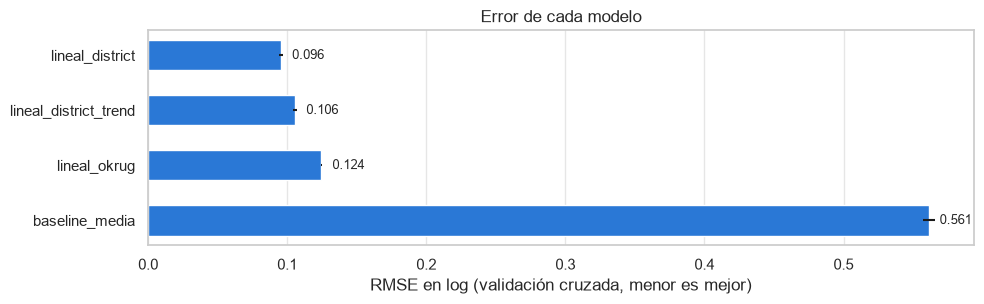

In [50]:
fig, ax = plt.subplots(figsize=(10, 3.2))
orden = comparacion_conjuntos.sort_values("cv_rmse_log", ascending=False)
ax.barh(orden.index, orden["cv_rmse_log"], xerr=orden["cv_rmse_log_std"], color=COLOR, height=0.55)
for i, v in enumerate(orden["cv_rmse_log"]):
    ax.text(v + 0.008, i, f"{v:.3f}", va="center", fontsize=9)
ax.set(xlabel="RMSE en log (validación cruzada, menor es mejor)", title="Error de cada modelo")
ax.grid(axis="y", visible=False)
plt.tight_layout(); guardar(fig, "modelos_comparacion"); plt.show()

**🔧 Qué hace el código**

- Gráfico de barras horizontales con el RMSE de validación cruzada de cada modelo, ordenado de peor a mejor. `xerr` agrega una barra de error con el desvío entre particiones.
- `ax.text` escribe el valor al final de cada barra.

**📊 Interpretación del resultado**

**Cómo leerlo:** cada barra es un modelo y su largo es el error típico en log (menor es mejor). La barra del baseline (≈ 0,56) es varias veces más larga que las de los modelos lineales (≈ 0,10–0,12): las variables reducen el error a menos de una quinta parte. Entre los modelos lineales, `district` es el más corto. Las barras de error son tan chicas que casi no se ven: las diferencias entre modelos no dependen de la partición.

### 14.8 Regularización: regresión Ridge

**📘 Concepto: regularización y regresión Ridge**
- **Qué es:** Ridge es una regresión lineal que, además de minimizar los errores al cuadrado, **penaliza los coeficientes grandes**: minimiza Σ(y − ŷ)² + α·Σβⱼ². El parámetro **α** controla la fuerza de la penalización (α = 0 equivale a la regresión común).
- **Para qué sirve:** cuando hay **muchas variables** (156 en `district`) o variables **correlacionadas**, los coeficientes de la regresión común pueden volverse inestables y el modelo puede **sobreajustar** (aprender el ruido del entrenamiento). Ridge "encoge" los coeficientes hacia 0 y reduce esa inestabilidad, a cambio de un pequeño sesgo.
- **Qué permite determinar:** si el modelo lineal común está sobreajustando. Si Ridge mejora la validación cruzada, había sobreajuste; si da lo mismo, no lo había.
- **`RidgeCV`:** prueba varios valores de α (acá 13, entre 0,001 y 1.000) con validación cruzada interna y elige el mejor automáticamente.
- **Si no se prueba:** no hay evidencia de que 156 variables no sean demasiadas para 39.000 filas.

In [51]:
ridge = RidgeCV(alphas=np.logspace(-3, 3, 13))
resultados["ridge_district"] = validacion_cruzada(conjuntos["district"], ridge)
registrar_run("ridge_district", "regularizacion", conjuntos["district"], ridge, resultados["ridge_district"],
              "Ridge con alpha elegido por validación cruzada interna.")

alpha_elegido = crear_pipeline(conjuntos["district"], ridge).fit(X_train[conjuntos["district"]], y_train)[-1].alpha_
print(f"alpha elegido por RidgeCV: {alpha_elegido}")
tabla_resultados(["lineal_district", "ridge_district"])

alpha elegido por RidgeCV: 0.0031622776601683794


,cv_r2_log,cv_r2_log_std,cv_rmse_log,cv_rmse_log_std,cv_mae_rub,cv_mape_rub,aic,bic
lineal_district,0.9710,0.0009,0.0955,0.0012,"14,974.9584",0.0765,"-72,539.6900","-71,194.0617"
ridge_district,0.9710,0.0009,0.0955,0.0012,"14,974.9927",0.0765,NaN,NaN


**🔧 Qué hace el código**

- `np.logspace(-3, 3, 13)` genera 13 valores de α espaciados logarítmicamente entre 10⁻³ y 10³ (0,001; 0,003; 0,01; …; 1.000).
- Se evalúa Ridge con validación cruzada y se registra en MLflow.
- Para ver qué α eligió, se entrena una vez con todo el entrenamiento y se consulta `alpha_`. `[-1]` toma el último paso del pipeline, es decir, el modelo.

**📊 Interpretación del resultado**

- **Ridge da los mismos resultados que la regresión común** (diferencias en el cuarto decimal o menos).
- Ridge no tiene AIC ni BIC en la tabla (celdas vacías), porque esos criterios no están definidos de forma estándar para modelos regularizados (§14.4).
- El α elegido es chico, es decir, la penalización óptima es débil: lo mejor es casi no regularizar.
- **Conclusión:** la regresión lineal común **no sobreajusta**. Con 39.000 filas y 156 variables (unas 250 filas por coeficiente) hay datos de sobra para estimar todos los coeficientes. Por **parsimonia** (ver §14.9) se sigue con la regresión lineal común, que es más simple y cuyos coeficientes no están "encogidos", así que se interpretan directamente.

### 14.9 Selección de variables por ablación

**📘 Concepto: estudio de ablación**
- **Qué es:** quitar **una variable por vez** del modelo y medir cuánto empeora (con validación cruzada). Si al quitarla el error no cambia, la variable no aportaba información que no estuviera ya en las demás.
- **Para qué sirve:** decidir qué variables eliminar **con evidencia predictiva**, no solo con su correlación aislada con el target. Una variable puede estar correlacionada con el precio y no aportar nada en el modelo, porque otra ya contiene esa información.
- **Qué permite determinar:** la contribución **marginal** de cada variable: lo que agrega teniendo en cuenta todas las demás.

**📘 Concepto: principio de parsimonia (navaja de Ockham)**
- **Qué es:** ante dos modelos con el mismo rendimiento, se prefiere **el más simple**.
- **Para qué sirve:** un modelo con menos variables es más fácil de interpretar y de mantener (hay que conseguir menos datos para predecir), y es menos propenso a sobreajustar.
- **Criterio que se usa acá:** se elimina una variable si, al quitarla, el RMSE de validación cruzada **no empeora más de 0,0002** en log (≈ 0,2% del error del modelo, por debajo del desvío entre particiones). Es decir, si el cambio no es distinguible del ruido.
- **Si no se aplica:** el modelo final arrastra variables que no aportan, y sus coeficientes (en general no significativos) confunden la interpretación.

**Variables evaluadas:** las candidatas de §13 (`is_agency`, `has_balcony`, `rooms`, `kitchen_area`, `log1p_to_center_km`) y las de tamaño y edificio que mostraron poca relación en el EDA (`total_area`, `floor`, `total_floors`, `building_age`). Como **control**, también se quitan variables que el EDA señaló como importantes (`log1p_metro_distance_min`, `ceiling_height` y los indicadores de piso): si el método funciona, al quitarlas el modelo **tiene** que empeorar.

In [52]:
UMBRAL = 0.0002
referencia = resultados["lineal_district"]["cv_rmse_log"]
candidatas = ["is_agency", "has_balcony", "rooms", "kitchen_area", "log1p_to_center_km",
              "total_area", "floor", "total_floors", "building_age",
              "log1p_metro_distance_min", "ceiling_height", "is_walk_to_metro", "is_first_floor", "is_last_floor"]

filas_ablacion = []
for var in candidatas:
    columnas = [c for c in conjuntos["district"] if c != var]
    modelo = LinearRegression()
    res = validacion_cruzada(columnas, modelo)
    res.update(criterios_informacion(columnas))
    registrar_run(f"sin_{var}", "ablacion", columnas, modelo, res, f"Conjunto 'district' sin {var}.")
    filas_ablacion.append({"variable quitada": var, "cv_rmse_log": res["cv_rmse_log"],
                           "Δ RMSE vs. completo": res["cv_rmse_log"] - referencia,
                           "Δ AIC": res["aic"] - resultados["lineal_district"]["aic"],
                           "Δ BIC": res["bic"] - resultados["lineal_district"]["bic"]})

ablacion = pd.DataFrame(filas_ablacion).sort_values("Δ RMSE vs. completo")
ablacion["decisión"] = np.where(ablacion["Δ RMSE vs. completo"] <= UMBRAL, "eliminar", "conservar")
ablacion["¿BIC coincide?"] = np.where((ablacion["Δ BIC"] < 0) == (ablacion["decisión"] == "eliminar"), "sí", "no")
ablacion.style.format({"cv_rmse_log": "{:.4f}", "Δ RMSE vs. completo": "{:+.4f}", "Δ AIC": "{:+,.1f}", "Δ BIC": "{:+,.1f}"})

,variable quitada,cv_rmse_log,Δ RMSE vs. completo,Δ AIC,Δ BIC,decisión,¿BIC coincide?
8,building_age,0.0955,-0.0000,-2.0,-10.6,eliminar,sí
5,total_area,0.0955,-0.0000,-1.4,-9.9,eliminar,sí
0,is_agency,0.0955,-0.0000,-2.0,-10.6,eliminar,sí
2,rooms,0.0955,-0.0000,-1.5,-10.1,eliminar,sí
6,floor,0.0955,-0.0000,-0.6,-9.2,eliminar,sí
3,kitchen_area,0.0955,-0.0000,+0.4,-8.2,eliminar,sí
7,total_floors,0.0955,+0.0000,-0.3,-8.8,eliminar,sí
4,log1p_to_center_km,0.0958,+0.0003,+273.3,+264.7,conservar,sí
10,ceiling_height,0.0959,+0.0004,+324.9,+316.3,conservar,sí
13,is_last_floor,0.0962,+0.0007,+542.8,+534.3,conservar,sí


**🔧 Qué hace el código**

- `referencia` es el RMSE de validación cruzada del modelo `district` completo.
- Por cada variable candidata arma el conjunto `district` **sin** esa variable, lo evalúa con validación cruzada (siempre con las mismas 5 particiones) y lo registra en MLflow con la etapa `ablacion`.
- Calcula cuánto cambió el RMSE respecto del modelo completo (Δ). Un Δ positivo significa que el modelo **empeora** al quitar la variable, o sea, que la variable aportaba.
- `np.where` asigna la decisión según el umbral: "eliminar" si Δ ≤ 0,0002 y "conservar" en caso contrario.
- Para cada variable también se calcula cuánto cambian el **AIC** y el **BIC** al quitarla (Δ AIC, Δ BIC). Un Δ **negativo** significa que el criterio **mejora** sin esa variable, o sea, que conviene quitarla. La última columna verifica si el BIC llega a la misma decisión que la validación cruzada: BIC negativo ↔ "eliminar".

**📊 Interpretación del resultado**

- **Variables que no aportan (Δ ≈ 0):** `is_agency`, `rooms`, `kitchen_area`, `total_area`, `floor`, `total_floors` y `building_age`. Al quitar cualquiera de ellas el error no cambia, lo que confirma el EDA:
  - el **tamaño** del departamento no influye en su precio *por m²*;
  - **quién vende** no influye;
  - el **piso como número** no influye (su efecto está en los indicadores de primer y último piso);
  - la **antigüedad** no agrega nada a lo que ya dice el **tipo de edificio** (§12.4).
- **Variables que aportan:**
  - **`log1p_metro_distance_min`** es por lejos la más importante: sin ella el RMSE empeora ≈ 0,016, un 17% más de error.
  - Le siguen `ceiling_height`, los indicadores de piso, `is_walk_to_metro` y `has_balcony`, con efectos chicos pero claramente por encima del ruido.
  - `log1p_to_center_km` aporta poco, aunque supera el umbral, coherente con §12.2 (con `district` en el modelo, casi no agrega).
- **El control funcionó:** las variables que el EDA señaló como importantes son justamente las que más empeoran el modelo al quitarse.
- **El BIC coincide en todas las variables:** para las 7 que se eliminan, el BIC **baja** al quitarlas (≈ −8 a −11: el ajuste no empeora y se ahorra la penalización de un parámetro). Para las que se conservan, el BIC **sube** entre ~265 y ~12.200 puntos (evidencia muy fuerte de que aportan; el mayor salto es el de la distancia al metro). El AIC, que penaliza menos, es más tolerante: para las 7 eliminables cambia entre −2 y +0,4, es decir, le resulta **indiferente** quitarlas (diferencias menores a 2), mientras que también sube mucho para las importantes. Las tres formas de evaluar (validación cruzada, AIC y BIC) llegan a la **misma selección de variables**.

La celda siguiente verifica que **quitar todas las eliminables juntas** tampoco empeora el modelo. Puede pasar que dos variables no aporten por separado porque cada una "cubre" a la otra (por ejemplo, `rooms` y `total_area`), y quitarlas juntas sí afecte.

In [53]:
eliminar = ablacion.loc[ablacion["decisión"] == "eliminar", "variable quitada"].tolist()
conjuntos["district_reducido"] = [c for c in conjuntos["district"] if c not in eliminar]

modelo = LinearRegression()
resultados["lineal_district_reducido"] = validacion_cruzada(conjuntos["district_reducido"], modelo)
resultados["lineal_district_reducido"].update(criterios_informacion(conjuntos["district_reducido"]))
registrar_run("lineal_district_reducido", "seleccion", conjuntos["district_reducido"], modelo,
              resultados["lineal_district_reducido"], f"Conjunto 'district' sin: {', '.join(eliminar)}.")

print("Variables eliminadas:", eliminar)
print(f"Variables: {len(conjuntos['district'])} → {len(conjuntos['district_reducido'])}")
tabla_resultados(["lineal_district", "lineal_district_reducido"])

Variables eliminadas: ['building_age', 'total_area', 'is_agency', 'rooms', 'floor', 'kitchen_area', 'total_floors']
Variables: 156 → 149


,cv_r2_log,cv_r2_log_std,cv_rmse_log,cv_rmse_log_std,cv_mae_rub,cv_mape_rub,aic,bic
lineal_district,0.9710,0.0009,0.0955,0.0012,"14,974.9584",0.0765,"-72,539.6900","-71,194.0617"
lineal_district_reducido,0.9710,0.0009,0.0955,0.0013,"14,971.1873",0.0765,"-72,547.7744","-71,262.1422"


**🔧 Qué hace el código**

- Toma la lista de variables marcadas como "eliminar" y crea el conjunto `district_reducido` sin ellas.
- Lo evalúa con validación cruzada, lo registra en MLflow (etapa `seleccion`) y lo compara con el modelo completo.

**📊 Interpretación del resultado**

- Al eliminar las 7 variables juntas, el modelo pasa de 156 a **149 variables** y sus métricas **no cambian** (diferencias en el cuarto decimal, dentro del ruido entre particiones).
- **AIC y BIC confirman la reducción:** los dos son menores en el modelo reducido. El BIC baja unos 68 puntos (evidencia fuerte a favor del reducido) y el AIC unos 8 (evidencia moderada): el ajuste es el mismo con 7 parámetros menos.
- Por parsimonia, **`district_reducido` es el modelo elegido**: rinde igual con menos variables, y todas las que conserva aportan.

### 14.10 Evaluación final en el conjunto de prueba

Es el **único** momento en que se usa el conjunto de prueba. El modelo elegido se entrena con **todo** el entrenamiento (las 5 particiones juntas) y se evalúa con la prueba.

**📘 Concepto: sobreajuste (*overfitting*) y subajuste (*underfitting*)**
- **Sobreajuste:** el modelo aprende detalles y ruido propios del entrenamiento que no se repiten en datos nuevos. Síntoma: **métricas mucho mejores en entrenamiento que en prueba**.
- **Subajuste:** el modelo es demasiado simple para captar la estructura de los datos. Síntoma: **métricas malas en los dos conjuntos**.
- **Qué permite determinar comparar entrenamiento con prueba:** si las métricas son parecidas, el modelo **generaliza**, y lo que aprendió vale para datos nuevos.

**📘 Concepto: corrección de *smearing* (Duan)**
- Al volver de log a rublos con exp(predicción) se obtiene una estimación de la **mediana**, que tiende a quedar un poco por debajo de la **media** (§12.1).
- La corrección de **smearing** multiplica la predicción por el promedio de exp(residuos de entrenamiento). Si ese factor es muy cercano a 1, el sesgo es despreciable y no hace falta corregir.

In [54]:
cols_final = conjuntos["district_reducido"]
modelo_final = crear_pipeline(cols_final, LinearRegression())
modelo_final.fit(X_train[cols_final], y_train)

pred_train = modelo_final.predict(X_train[cols_final])
pred_test = modelo_final.predict(X_test[cols_final])
met_train, met_test = metricas(y_train, pred_train), metricas(y_test, pred_test)

evaluacion = pd.DataFrame({"entrenamiento": met_train, "prueba": met_test,
                           "validación cruzada": {k: resultados["lineal_district_reducido"][f"cv_{k}"] for k in met_test}})
display(evaluacion.style.format("{:.4f}").format("{:,.0f}", subset=pd.IndexSlice[["rmse_rub", "mae_rub"], :]))

# Precisión práctica: ¿qué proporción de predicciones cae cerca del valor real?
error_pct = np.abs(np.exp(pred_test) - y_rub_test) / y_rub_test
for tol in [0.05, 0.10, 0.20]:
    print(f"Predicciones con error menor al {tol:.0%}: {(error_pct < tol).mean():.1%}")

# Corrección de smearing
smearing = np.mean(np.exp(y_train - pred_train))
print(f"\nFactor de smearing: {smearing:.4f}")
print(f"Sesgo medio en rublos (real − predicho) sin corrección: {(y_rub_test - np.exp(pred_test)).mean():,.0f}")
print(f"Sesgo medio en rublos con corrección                 : {(y_rub_test - np.exp(pred_test) * smearing).mean():,.0f}")

,entrenamiento,prueba,validación cruzada
r2_log,0.9713,0.9696,0.9710
rmse_log,0.0951,0.0959,0.0955
mae_log,0.0758,0.0769,0.0762
r2_rub,0.9644,0.9625,0.9640
rmse_rub,"21,507","21,700","21,606"
mae_rub,"14,901","15,068","14,971"
mape_rub,0.0761,0.0772,0.0765


Predicciones con error menor al 5%: 39.2%
Predicciones con error menor al 10%: 69.9%
Predicciones con error menor al 20%: 96.2%

Factor de smearing: 1.0045
Sesgo medio en rublos (real − predicho) sin corrección: 994
Sesgo medio en rublos con corrección                 : 116


**🔧 Qué hace el código**

- Se arma el pipeline del modelo elegido y se entrena con **todo** el conjunto de entrenamiento (`.fit`).
- Se predicen los dos conjuntos y se calculan las métricas de cada uno. La tabla pone lado a lado entrenamiento, prueba y el promedio de la validación cruzada. `display` muestra la tabla con formato aunque no sea la última línea de la celda.
- **Precisión práctica:** se calcula el error porcentual de cada predicción en rublos y la proporción que queda por debajo del 5%, el 10% y el 20%.
- **Smearing:** promedio de exp(residuos de entrenamiento), y sesgo medio en rublos con y sin la corrección.

**📊 Interpretación del resultado**

- **Rendimiento en datos nuevos (prueba):**
  - **R² ≈ 0,970 en log** (≈ 0,962 en rublos): el modelo explica el 97% de la variabilidad del precio por m².
  - **Error porcentual medio (MAPE) ≈ 7,7%** y **error absoluto medio ≈ 15.000 rublos/m²**, frente a una mediana de precio de ~171.000.
  - **El 39% de las predicciones** queda a menos del 5% del valor real, **el 70%** a menos del 10% y **el 96%** a menos del 20%.
- **No hay sobreajuste:** el R² de entrenamiento (≈ 0,971) y el de prueba (≈ 0,970) son prácticamente iguales, y la prueba coincide con la validación cruzada. Que la validación cruzada haya anticipado tan bien el resultado de la prueba confirma que **el procedimiento de selección fue honesto**.
- **Smearing:** el factor es ≈ 1,0045, es decir, exp(predicción) subestima el precio medio apenas un 0,45%. El sesgo medio sin corregir es de unos 1.000 rublos/m² (≈ 0,6% de la mediana) y con la corrección baja a ~100. Es despreciable frente al error típico (~15.000), así que se reportan las predicciones sin corregir.
- **Comparación con el baseline:** el error porcentual baja de ~50% a ~8%, y el error absoluto medio de ~80.000 a ~15.000 rublos/m².

### 14.11 Diagnóstico de residuos

**📘 Concepto: residuo**
- **Qué es:** residuo = valor real − valor predicho (en log). Es lo que el modelo **no** logra explicar. Un residuo de +0,10 significa que el departamento es ~10% más caro de lo que predice el modelo.
- **Para qué sirve analizarlos:** los supuestos de la regresión lineal (§14) se refieren a los **errores**, no a las variables. Los residuos son la única forma de verificarlos.
- **Si no se analizan:** un buen R² puede esconder errores **sistemáticos**, como un modelo que subestima siempre los departamentos caros o se equivoca siempre en una zona.

**📘 Los cuatro gráficos de diagnóstico y qué verifica cada uno**

| Gráfico | Supuesto que verifica | Qué se espera ver si se cumple | Señal de problema |
|---|---|---|---|
| **Real vs. predicho** | Ajuste general | Puntos pegados a la diagonal | Puntos que se alejan en algún tramo (por ejemplo, los caros) |
| **Residuos vs. predichos** | Linealidad y homocedasticidad | Nube horizontal centrada en 0, de ancho parejo | Curva (falta una transformación) o embudo (varianza que crece) |
| **Q-Q de residuos** | Normalidad de los errores | Puntos sobre la recta | Colas que se separan (errores extremos frecuentes) |
| **Residuos por okrug** | Ausencia de sesgo por zona | Cajas centradas en 0 | Zonas con la caja desplazada (el modelo sobre- o subestima esa zona) |

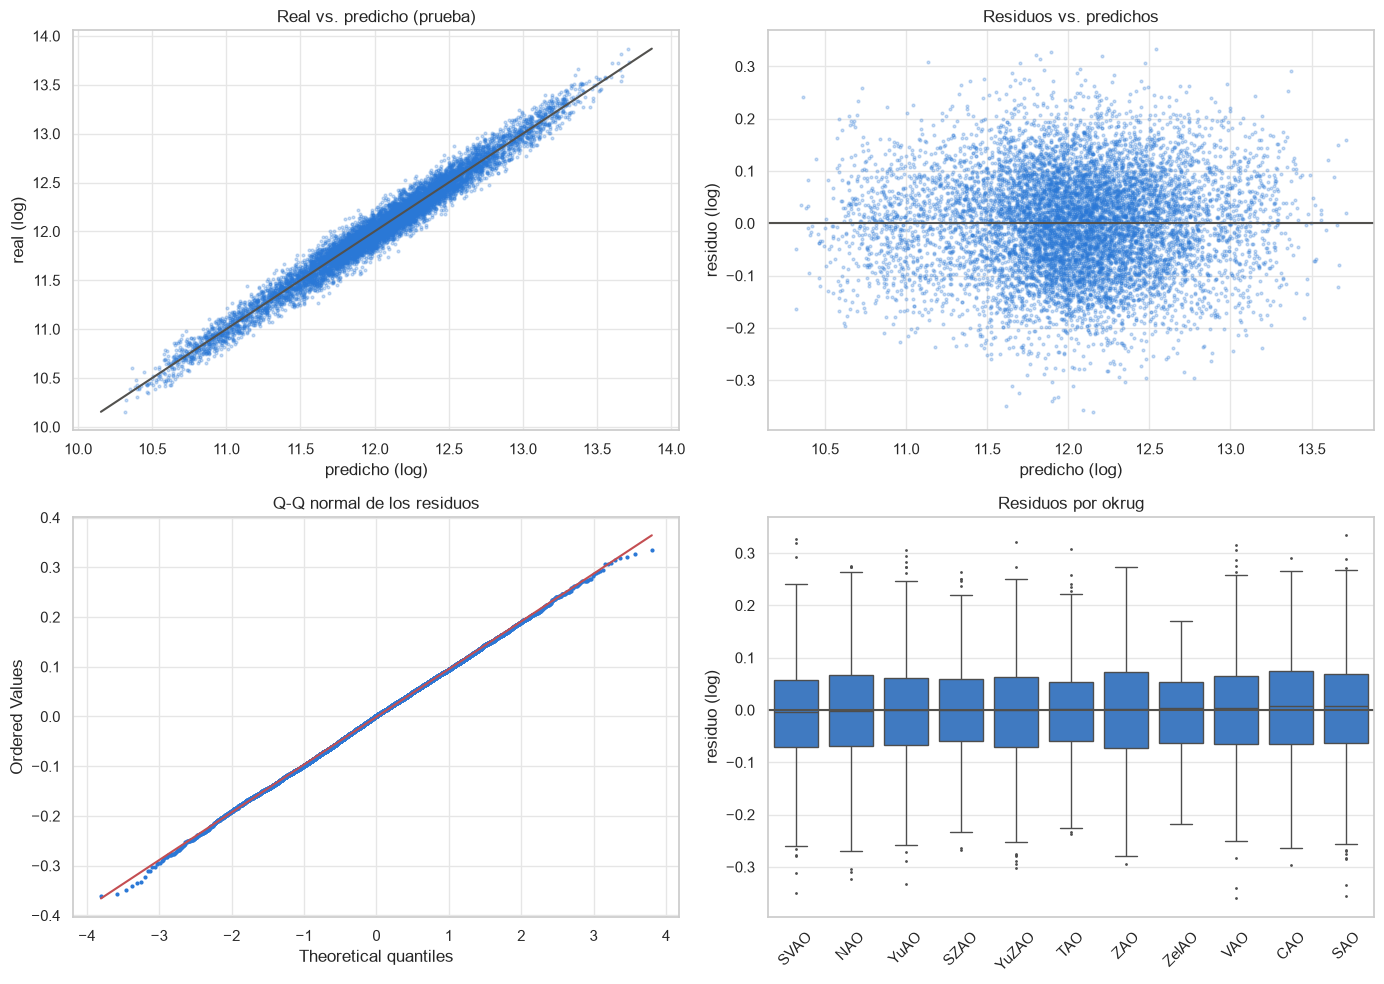

In [55]:
residuos_test = y_test - pred_test
okrug_test = pd.read_csv(config.CLEAN_CSV, usecols=["okrug"]).loc[X_test.index, "okrug"]

fig_res, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(pred_test, y_test, s=4, alpha=.25, color=COLOR)
lim = [y_test.min(), y_test.max()]
axes[0, 0].plot(lim, lim, color="#52514e", lw=1.5)
axes[0, 0].set(title="Real vs. predicho (prueba)", xlabel="predicho (log)", ylabel="real (log)")

axes[0, 1].scatter(pred_test, residuos_test, s=4, alpha=.25, color=COLOR)
axes[0, 1].axhline(0, color="#52514e", lw=1.5)
axes[0, 1].set(title="Residuos vs. predichos", xlabel="predicho (log)", ylabel="residuo (log)")

stats.probplot(residuos_test, dist="norm", plot=axes[1, 0])
axes[1, 0].get_lines()[0].set(color=COLOR, markersize=2)
axes[1, 0].set_title("Q-Q normal de los residuos")

orden_ok = residuos_test.groupby(okrug_test).median().sort_values().index
sns.boxplot(x=okrug_test, y=residuos_test, order=orden_ok, color=COLOR, fliersize=1, ax=axes[1, 1])
axes[1, 1].axhline(0, color="#52514e", lw=1.5)
axes[1, 1].set(title="Residuos por okrug", xlabel="", ylabel="residuo (log)")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout(); guardar(fig_res, "residuos_diagnostico"); plt.show()

**🔧 Qué hace el código**

- `residuos_test` = real − predicho, en el conjunto de prueba. Para agrupar por zona se recupera el `okrug` de cada fila del dataset limpio (`usecols` lee solo esa columna; `.loc[X_test.index]` toma las filas de prueba, porque el índice de las features coincide con el del dataset limpio).
- **Panel 1:** dispersión real vs. predicho, con la diagonal (`plot(lim, lim)`), que representa la predicción perfecta.
- **Panel 2:** residuos vs. predichos, con una línea horizontal en 0 (`axhline`).
- **Panel 3:** Q-Q plot de los residuos contra una normal.
- **Panel 4:** boxplot de los residuos por okrug, ordenado por mediana, con la línea en 0.

**📊 Interpretación del resultado**

- **Real vs. predicho:** los puntos forman una banda angosta y recta a lo largo de la diagonal, en **todo** el rango de precios, desde la periferia (~10,5) hasta el centro (~13,5). El modelo no pierde precisión en los extremos.
- **Residuos vs. predichos:** una nube **horizontal, centrada en 0 y de ancho parejo**. No hay curva (la linealidad se cumple: las transformaciones log del módulo C funcionaron) ni embudo (la varianza es constante: **homocedasticidad**). Ver la verificación numérica en la celda siguiente.
- **Q-Q de residuos:** los puntos están sobre la recta en prácticamente todo el rango. Solo unos pocos puntos del extremo izquierdo (por debajo de −3 en el eje X) quedan levemente debajo: hay apenas un puñado de departamentos que el modelo sobreestima un poco más de lo que tendría una normal. Los residuos son **casi exactamente normales**. El "hombro" que tenía el target (§4) **desapareció**: como se anticipó, `district` explica la diferencia entre la periferia y el resto.
- **Residuos por okrug:** todas las cajas están centradas en 0. El modelo **no sobre- ni subestima sistemáticamente ninguna zona**, ni siquiera CAO, que concentraba los atípicos del EDA.
- **Conclusión:** los supuestos de linealidad, homocedasticidad y normalidad se cumplen razonablemente.

In [56]:
# Verificación numérica de los supuestos
print(f"Residuos (prueba) — media: {residuos_test.mean():+.4f} | asimetría: {stats.skew(residuos_test):+.3f} | "
      f"curtosis en exceso: {stats.kurtosis(residuos_test):+.3f}")

print("\nDesvío de los residuos por quintil de la predicción (homocedasticidad):")
quintil = pd.qcut(pred_test, 5, labels=["Q1 (más baratos)", "Q2", "Q3", "Q4", "Q5 (más caros)"])
print(residuos_test.groupby(quintil, observed=True).agg(["mean", "std"]).round(4).to_string())

X_bp = sm.add_constant(X_train[cols_final])
_, bp_pvalor, _, _ = het_breuschpagan(y_train - pred_train, X_bp)
print(f"\nTest de Breusch-Pagan (H₀: varianza constante), p-valor: {bp_pvalor:.1e}")

Residuos (prueba) — media: -0.0008 | asimetría: -0.029 | curtosis en exceso: -0.034

Desvío de los residuos por quintil de la predicción (homocedasticidad):
                    mean    std
Q1 (más baratos)  0.0019 0.0948
Q2                0.0006 0.0964
Q3               -0.0077 0.0950
Q4               -0.0033 0.0958
Q5 (más caros)    0.0047 0.0973

Test de Breusch-Pagan (H₀: varianza constante), p-valor: 1.1e-42


**🔧 Qué hace el código**

- Calcula la media, la asimetría y la curtosis de los residuos de prueba (una normal tiene 0 en las tres).
- Divide las predicciones en **quintiles** (`pd.qcut` arma 5 grupos con la misma cantidad de filas, del más barato al más caro) y calcula la media y el desvío de los residuos en cada uno. Si el desvío es parejo entre quintiles, hay homocedasticidad.
- Aplica el test de **Breusch-Pagan** sobre los residuos de entrenamiento.

**📊 Interpretación del resultado**

- **Media ≈ 0, asimetría ≈ 0 y curtosis ≈ 0:** los residuos tienen la forma de una normal centrada en 0. Se confirma lo que mostró el Q-Q.
- **Desvío por quintil:** entre ≈ 0,095 y 0,097 en los cinco grupos. Los departamentos baratos y los caros tienen el **mismo** error típico (~10%). La media de cada quintil es ≈ 0: no hay sesgo por nivel de precio.
- **Breusch-Pagan rechaza la homocedasticidad** (p muy chico). **No se contradice con lo anterior:** con 39.000 filas, el test detecta diferencias de varianza minúsculas, como pasó con Shapiro-Wilk en §4.1. La diferencia real entre el quintil de menor y el de mayor desvío (0,0948 vs. 0,0973) es de ~3%, sin importancia práctica.
- **Decisión:** para que los p-valores y los intervalos de §14.12 sean válidos aunque exista esa heterocedasticidad leve, se calculan con **errores estándar robustos** (HC3).

**📘 Concepto: test de Breusch-Pagan**
- **Qué es:** una prueba de hipótesis con H₀ = "la varianza de los errores es constante". Ajusta una regresión de los residuos al cuadrado contra las variables: si las variables explican los residuos al cuadrado, la varianza depende de ellas.
- **Para qué sirve:** dar una respuesta formal sobre la homocedasticidad.
- **Limitación:** igual que todo test, con muestras grandes rechaza ante diferencias irrelevantes. Por eso se complementa con el gráfico de residuos y el desvío por quintiles, que muestran el **tamaño** del problema.

### 14.12 Interpretación de los coeficientes

Para interpretar se ajusta el mismo modelo con **statsmodels**, sobre las variables **sin estandarizar**, porque statsmodels reporta para cada coeficiente su error estándar, su p-valor y su intervalo de confianza. Las predicciones son idénticas a las del pipeline de scikit-learn.

**📘 Concepto: coeficiente en un modelo log-lineal**
- Como el target es log(precio), un coeficiente β se interpreta como un cambio **porcentual**: cuando la variable aumenta en 1 (y todo lo demás queda igual), el precio se multiplica por e^β. El cambio porcentual exacto es **(e^β − 1) × 100%**. Para β chicos, e^β − 1 ≈ β.
- **Variables 0/1 (binarias y one-hot):** β es la diferencia porcentual entre tener la característica y no tenerla (o respecto de la **categoría de referencia**, §12.7).
- **Variables en log1p (distancias):** β es una **elasticidad**: un aumento del 10% en la distancia se asocia con un cambio de ≈ β × 10% en el precio.
- **Variables en unidades** (`ceiling_height`): (e^β − 1) × 100% por cada unidad (1 metro); para 10 cm hay que dividir β por 10.
- ***Ceteris paribus*** ("lo demás constante"): cada coeficiente mide el efecto de su variable **comparando departamentos iguales en todas las demás variables del modelo**. Es la gran ventaja de la regresión sobre las comparaciones simples de §6.

**📘 Concepto: p-valor e intervalo de confianza de un coeficiente**
- **p-valor:** la probabilidad de observar un coeficiente tan alejado de 0 si en realidad la variable no tuviera efecto (H₀: β = 0). Con p < 0,05 se concluye que el efecto es distinto de 0.
- **Intervalo de confianza al 95%:** el rango de valores plausibles para el efecto real. Si no incluye el 0, el efecto es significativo. Su **ancho** indica la precisión de la estimación.

**📘 Concepto: errores estándar robustos (HC3)**
- **Qué es:** una forma de calcular los errores estándar de los coeficientes que **no supone homocedasticidad**.
- **Para qué sirve:** los coeficientes no cambian, pero sus p-valores e intervalos siguen siendo válidos aunque la varianza de los errores no sea perfectamente constante (§14.11).
- **Si no se usan con heterocedasticidad:** los intervalos pueden ser demasiado angostos y algunos p-valores, engañosamente chicos.

In [57]:
X_ols = sm.add_constant(X_train[cols_final])
ols = sm.OLS(y_train, X_ols).fit(cov_type="HC3")
print(f"R² (entrenamiento): {ols.rsquared:.4f} | R² ajustado: {ols.rsquared_adj:.4f} | observaciones: {int(ols.nobs):,}")
print(f"AIC: {ols.aic:,.1f} | BIC: {ols.bic:,.1f}")

intervalos = ols.conf_int()
coefs = pd.DataFrame({
    "coeficiente": ols.params,
    "efecto %": (np.exp(ols.params) - 1) * 100,
    "IC 95% inf. (%)": (np.exp(intervalos[0]) - 1) * 100,
    "IC 95% sup. (%)": (np.exp(intervalos[1]) - 1) * 100,
    "p-valor": ols.pvalues,
}).drop(index="const")

no_distrito = coefs[~coefs.index.str.startswith("district_")].sort_values("efecto %")
no_distrito.style.format({"coeficiente": "{:+.4f}", "efecto %": "{:+.1f}", "IC 95% inf. (%)": "{:+.1f}",
                          "IC 95% sup. (%)": "{:+.1f}", "p-valor": "{:.1e}"})

R² (entrenamiento): 0.9713 | R² ajustado: 0.9712 | observaciones: 38,983
AIC: -72,547.8 | BIC: -71,262.1


,coeficiente,efecto %,IC 95% inf. (%),IC 95% sup. (%),p-valor
building_type_khrushchev,-0.2085,-18.8,-19.1,-18.5,0.0e+00
log1p_metro_distance_min,-0.1427,-13.3,-13.5,-13.1,0.0e+00
building_type_panel,-0.1308,-12.3,-12.5,-12.0,0.0e+00
renovation_no_renovation,-0.1109,-10.5,-10.7,-10.3,0.0e+00
is_first_floor,-0.0710,-6.9,-7.2,-6.6,0.0e+00
log1p_to_center_km,-0.0612,-5.9,-6.6,-5.2,3.0e-57
building_type_modern_panel,-0.0460,-4.5,-4.8,-4.2,2.0e-184
is_last_floor,-0.0435,-4.3,-4.6,-3.9,1.1e-141
has_balcony,+0.0311,+3.2,+2.9,+3.4,2.6e-169
ceiling_height,+0.0473,+4.8,+4.3,+5.4,4.6e-72


**🔧 Qué hace el código**

- `sm.add_constant` agrega la columna del intercepto, porque statsmodels no la agrega automáticamente. `sm.OLS(...).fit(cov_type="HC3")` ajusta la regresión con errores estándar robustos.
- Se muestran el R² y el **R² ajustado**, que penaliza la cantidad de variables (si fuera mucho menor que el R², habría variables de más), y el **AIC** y el **BIC** del modelo final. Son los mismos valores que se calcularon en §14.9 y que figuran en MLflow: los errores robustos HC3 cambian los errores estándar, pero no la verosimilitud.
- Se arma una tabla con cada coeficiente, su efecto porcentual (e^β − 1), los límites del intervalo de confianza transformados a porcentaje y el p-valor.
- Se muestran todas las variables **menos los 128 distritos**, que se analizan aparte. Se ordenan de efecto más negativo a más positivo.

**📊 Interpretación del resultado**

**Lectura de los efectos** (todos con p-valor muy chico e intervalos angostos, así que son estimaciones precisas):
- **Tiempo** (referencia: 2020): a igual departamento, el precio por m² es ≈ +18% en 2021, +27% en 2022, +38% en 2023 y ≈ **+44%** en 2024. Después se estabiliza (≈ +42% en 2025 y +44% en 2026). Es el estancamiento que se vio en el EDA, ahora medido *ceteris paribus*.
- **Renovación** (referencia: cosmética): sin renovar ≈ **−10%**, euro ≈ **+16%**, de diseñador ≈ **+36%**. Es el factor más importante del departamento en sí.
- **Tipo de edificio** (referencia: ladrillo): khrushchev ≈ **−19%**, panel ≈ −12%, panel moderno ≈ −4%, monolito ≈ +5% y stalin ≈ **+15%**.
- **Distancia al metro:** elasticidad ≈ **−0,14**. Un 10% más de distancia se asocia con ≈ 1,4% menos de precio; duplicar la distancia, con ≈ 9–10% menos. Además, llegar **caminando** suma ≈ +5%.
- **Distancia al centro:** elasticidad ≈ −0,06. Es chica porque el distrito ya captura casi toda la ubicación (§12.2).
- **Piso:** primer piso ≈ **−7%**, último piso ≈ −4%.
- **Altura del techo:** ≈ +5% por metro (≈ +0,5% cada 10 cm).
- **Balcón:** ≈ **+3%**.

El **R² ajustado** es prácticamente igual al R², así que el modelo no tiene variables de más.

Distritos: 128 coeficientes (referencia: Aeroport)
No significativos (p > 0,05): 6

Los 5 distritos más baratos y los 5 más caros respecto de Aeroport (a igual departamento):
                         efecto %  IC 95% inf. (%)  IC 95% sup. (%)
Klyonovskoye             -63.6000         -64.4000         -62.8000
Shchapovskoye            -63.3000         -64.1000         -62.6000
Mikhaylovo-Yartsevskoye  -63.0000         -63.7000         -62.3000
Rogovskoye               -62.2000         -63.1000         -61.4000
Kievsky                  -62.1000         -63.0000         -61.3000
Khamovniki               119.3000         115.7000         123.0000
Arbat                    109.0000         105.5000         112.6000
Tverskoy                 103.1000          99.6000         106.6000
Yakimanka                 97.8000          94.4000         101.3000
Presnensky                93.1000          89.8000          96.4000


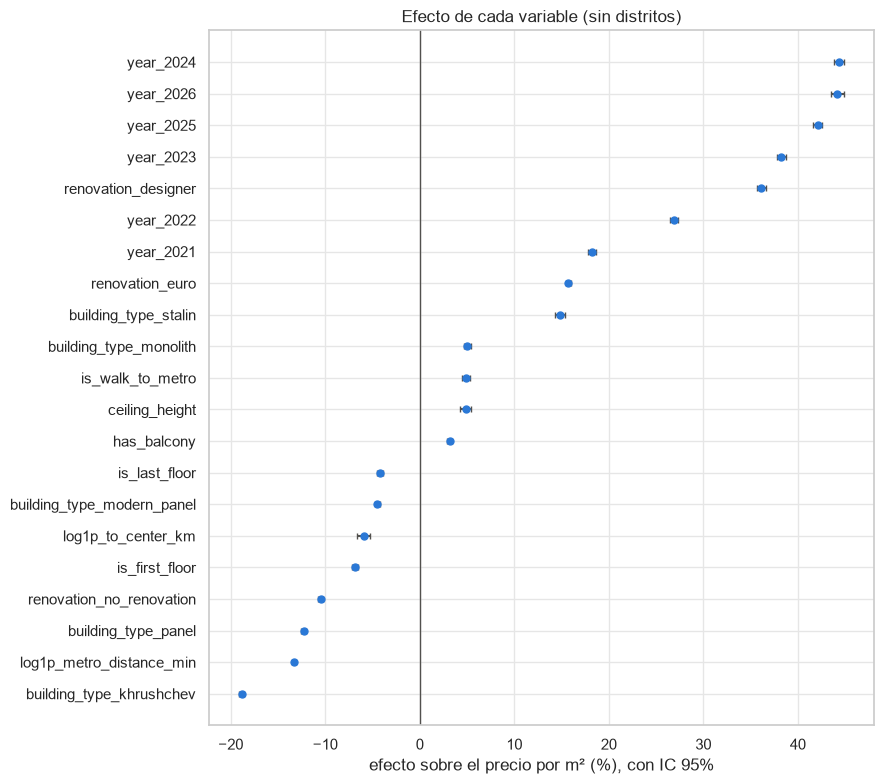

In [58]:
distritos = coefs[coefs.index.str.startswith("district_")]
print(f"Distritos: {len(distritos)} coeficientes (referencia: Aeroport)")
print(f"No significativos (p > 0,05): {(distritos['p-valor'] > 0.05).sum()}")
print("\nLos 5 distritos más baratos y los 5 más caros respecto de Aeroport (a igual departamento):")
extremos = pd.concat([distritos.nsmallest(5, "efecto %"), distritos.nlargest(5, "efecto %")])
extremos.index = extremos.index.str.replace("district_", "")
print(extremos[["efecto %", "IC 95% inf. (%)", "IC 95% sup. (%)"]].round(1).to_string())

fig_coef, ax = plt.subplots(figsize=(9, 8))
orden_c = no_distrito.sort_values("efecto %")
ax.errorbar(orden_c["efecto %"], range(len(orden_c)),
            xerr=[orden_c["efecto %"] - orden_c["IC 95% inf. (%)"], orden_c["IC 95% sup. (%)"] - orden_c["efecto %"]],
            fmt="o", color=COLOR, ecolor="#52514e", capsize=2, markersize=5)
ax.axvline(0, color="#52514e", lw=1)
ax.set_yticks(range(len(orden_c)), orden_c.index)
ax.set(xlabel="efecto sobre el precio por m² (%), con IC 95%", title="Efecto de cada variable (sin distritos)")
plt.tight_layout(); guardar(fig_coef, "coeficientes"); plt.show()

**🔧 Qué hace el código**

- Filtra los coeficientes de distrito, cuenta cuántos no son significativos y muestra los 5 de menor y los 5 de mayor efecto (`nsmallest` / `nlargest`). `str.replace` le quita el prefijo al nombre para que se lea mejor.
- **Gráfico de coeficientes:** cada punto es el efecto porcentual de una variable y la barra horizontal es su intervalo de confianza al 95% (`errorbar` con `xerr` asimétrico, porque al pasar a porcentaje el intervalo deja de ser simétrico). La línea vertical en 0 marca "sin efecto".

**📊 Interpretación del resultado**

- **Distritos:** los efectos van de alrededor de **−64%** (los distritos más baratos de la periferia, como Klyonovskoye) a **+119%** (los más caros del centro, como Khamovniki) respecto de Aeroport, comparando departamentos iguales en todo lo demás. Es la variable de mayor efecto del modelo. Unos pocos distritos no son significativos: tienen precios **iguales a los de Aeroport**, no "sin efecto".
- **Cómo leer el gráfico:** las variables a la izquierda del 0 bajan el precio y las de la derecha lo suben. Que **ningún intervalo cruce el 0** significa que todos los efectos son significativos. Que los intervalos sean **tan cortos** que casi no se ven indica que las estimaciones son muy precisas, gracias al tamaño de la muestra.
- Las variables de mayor efecto (año, renovación, tipo de edificio) son características del **momento** y de la **calidad** del departamento. Las de ubicación (distancias, distrito) completan la explicación.

### 14.13 Registro del modelo final en MLflow

**📘 Concepto: registrar el modelo como artefacto**
- **Qué es:** guardar el **pipeline entrenado completo** (estandarización + regresión) en MLflow, junto con un ejemplo de entrada y la descripción de las columnas que espera (la **firma** o *signature*).
- **Para qué sirve:** cualquiera puede cargar el modelo después (`mlflow.sklearn.load_model`) y predecir con datos nuevos **sin volver a entrenar** y sin tener que recordar qué transformación aplicar, porque el pipeline la incluye.
- **Qué más se guarda en el run final:** las métricas de prueba, entrenamiento y validación cruzada; los gráficos de diagnóstico y de coeficientes; la tabla de coeficientes y la lista de variables. Todo queda junto en un único run.
- **Si no se registra:** el modelo existe solo en la memoria del notebook y se pierde al cerrarlo.

In [59]:
with mlflow.start_run(run_name="modelo_final") as run_final:
    mlflow.set_tags({"origen": "notebook_01", "etapa": "final",
                     "mlflow.note.content": "Regresión lineal con district_reducido, evaluada una vez en prueba."})
    mlflow.log_params({"modelo": "LinearRegression", "conjunto": "district_reducido", "n_variables": len(cols_final),
                       "variables_eliminadas": ", ".join(eliminar), "test_size": 0.2,
                       "random_state": config.RANDOM_STATE, "target": config.TARGET_LOG})
    mlflow.log_metrics({f"test_{k}": float(v) for k, v in met_test.items()})
    mlflow.log_metrics({f"train_{k}": float(v) for k, v in met_train.items()})
    mlflow.log_metrics({k: float(v) for k, v in resultados["lineal_district_reducido"].items()})
    mlflow.log_metrics({"smearing": float(smearing), "breusch_pagan_pvalor": float(bp_pvalor),
                        "pct_error_menor_10": float((error_pct < 0.10).mean()),
                        "pct_error_menor_20": float((error_pct < 0.20).mean())})
    mlflow.log_text("\n".join(cols_final), "variables.txt")
    mlflow.log_text(coefs.to_csv(), "coeficientes.csv")
    mlflow.log_figure(fig_res, "residuos_diagnostico.png")
    mlflow.log_figure(fig_coef, "coeficientes.png")
    mlflow.sklearn.log_model(modelo_final, name="modelo", input_example=X_test[cols_final].head(3))

print("Run final:", run_final.info.run_id)
print("Artefactos del run final en:", cliente.get_run(run_final.info.run_id).info.artifact_uri, "(ruta relativa a la raíz del repo)")

# Todas las ejecuciones de este notebook, tal como se ven en MLflow
runs = mlflow.search_runs([experimento.experiment_id], filter_string="tags.origen = 'notebook_01'",
                          order_by=["metrics.cv_rmse_log ASC"])
runs[["tags.mlflow.runName", "tags.etapa", "params.n_variables", "metrics.cv_r2_log",
      "metrics.cv_rmse_log", "metrics.cv_mape_rub", "metrics.aic", "metrics.bic", "metrics.test_r2_log"]]

Run final: 6c13479867274ad9a0e5cdf3ed1f3fd9
Artefactos del run final en: mlartifacts/6c13479867274ad9a0e5cdf3ed1f3fd9/artifacts (ruta relativa a la raíz del repo)


,tags.mlflow.runName,tags.etapa,params.n_variables,metrics.cv_r2_log,metrics.cv_rmse_log,metrics.cv_mape_rub,metrics.aic,metrics.bic,metrics.test_r2_log
0,modelo_final,final,149,0.9710,0.0955,0.0765,"-72,547.7744","-71,262.1422",0.9696
1,lineal_district_reducido,seleccion,149,0.9710,0.0955,0.0765,"-72,547.7744","-71,262.1422",NaN
2,sin_building_age,ablacion,155,0.9710,0.0955,0.0765,"-72,541.6774","-71,204.6199",NaN
3,sin_total_area,ablacion,155,0.9710,0.0955,0.0765,"-72,541.0677","-71,204.0102",NaN
4,sin_is_agency,ablacion,155,0.9710,0.0955,0.0765,"-72,541.6890","-71,204.6316",NaN
5,sin_rooms,ablacion,155,0.9710,0.0955,0.0765,"-72,541.2351","-71,204.1777",NaN
6,sin_floor,ablacion,155,0.9710,0.0955,0.0765,"-72,540.3196","-71,203.2622",NaN
7,sin_kitchen_area,ablacion,155,0.9710,0.0955,0.0765,"-72,539.3270","-71,202.2696",NaN
8,ridge_district,regularizacion,156,0.9710,0.0955,0.0765,NaN,NaN,NaN
9,lineal_district,comparacion_conjuntos,156,0.9710,0.0955,0.0765,"-72,539.6900","-71,194.0617",NaN


**🔧 Qué hace el código**

- Abre el run `modelo_final` y registra:
  - **etiquetas** (`etapa = final`);
  - **parámetros**: modelo, conjunto, cantidad de variables, variables eliminadas, tamaño de la prueba, semilla y target;
  - **métricas**: de prueba (`test_`), de entrenamiento (`train_`), de validación cruzada (`cv_`), los criterios de información (`aic`, `bic`, `r2_ajustado`) y los diagnósticos (smearing, Breusch-Pagan, % de predicciones con error menor al 10% y al 20%);
  - **artefactos**: la lista de variables, la tabla de coeficientes en CSV, los dos gráficos (`log_figure`) y el **modelo** (`log_model`, con un ejemplo de 3 filas a partir del cual MLflow deduce la firma).
- Después, `search_runs` lista todos los runs de este notebook ordenados por RMSE de validación cruzada, con las columnas principales. Es la misma información que muestra la interfaz de MLflow.

**📊 Interpretación del resultado**

- El experimento queda con **un run por cada decisión del módulo**: el baseline, los 3 conjuntos, Ridge, las 14 ablaciones, el modelo reducido y el modelo final. En total, 21 runs.
- Ordenados por error, arriba quedan los modelos con `district` (completo, reducido y las ablaciones que no empeoran) y abajo `okrug`, las ablaciones de las variables importantes y el baseline.
- Solo el run `modelo_final` tiene métricas de prueba (`test_r2_log`): es el **único** modelo que se evaluó con el conjunto de prueba.
- Todos los runs tienen AIC y BIC, salvo `ridge_district` (no están definidos para Ridge). En la interfaz de MLflow se pueden agregar como columnas (`aic`, `bic`) y ordenar por ellas: el orden coincide con el de `cv_rmse_log`.

**Para verlo en la interfaz de MLflow**, desde la raíz del proyecto:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

Abrir http://127.0.0.1:5000 → experimento `moscow-secondary-price-per-sqm`. Desde ahí se pueden seleccionar varios runs y usar **Compare** para ver sus métricas lado a lado.

## 15. Conclusiones del modelado

### Respuesta a las preguntas del parcial

**¿Qué tan bien se puede predecir el precio por m²?** Una regresión lineal con 149 variables explica el **97% de la variabilidad** del precio por m² (R² = 0,970 en datos que el modelo no vio), con un **error porcentual medio de ~7,7%** (~15.000 rublos/m²). El 96% de las predicciones queda a menos del 20% del valor real. El baseline (predecir siempre la media) tenía un error de ~50%.

**¿Qué determina el precio?** En orden de importancia:
1. **Ubicación** (distrito y distancia al metro): es lo que más pesa. Entre el distrito más barato y el más caro hay una diferencia de varias veces a igual departamento, y cada 10% más de distancia al metro resta ~1,4%.
2. **Momento de publicación:** +44% entre 2020 y 2024, con un estancamiento posterior.
3. **Calidad del departamento:** la renovación (de −10% a +36% respecto de una cosmética) y el tipo de edificio (de −19% para un khrushchev a +15% para un stalin, respecto de uno de ladrillo).
4. **Detalles:** primer piso (−7%), último piso (−4%), balcón (+3%), techos altos (+5% por metro).

**¿Qué no lo determina?** El tamaño del departamento, la cantidad de ambientes, el número de piso, la antigüedad (más allá del tipo de edificio), quién lo vende y la tasa hipotecaria (cuya correlación era espuria).

### Validez del modelo

| Verificación | Resultado |
|---|---|
| Sobreajuste | No: R² de entrenamiento 0,971 vs. prueba 0,970 |
| Linealidad | Se cumple: residuos sin curvatura |
| Homocedasticidad | Se cumple en la práctica (desvío 0,095–0,097 en todos los tramos); se usan errores robustos HC3 por la heterocedasticidad leve que detecta Breusch-Pagan |
| Normalidad de los residuos | Se cumple: asimetría y curtosis ≈ 0, Q-Q recto |
| Sesgo por zona | No: residuos centrados en 0 en todos los okrugs |
| Multicolinealidad | Controlada: VIF < 5,2 en las numéricas y binarias (§12.9) |
| Selección del modelo | Validación cruzada, AIC y BIC eligen el mismo modelo y las mismas variables (§14.7, §14.9) |

### Limitaciones
- **Validación dentro del período:** la división aleatoria mide la capacidad de predecir departamentos nuevos **dentro de 2020–2026**. Para predecir años futuros haría falta una validación temporal, y los dummies de año no sirven para años no observados.
- **Ubicación como categoría:** el modelo solo puede predecir distritos que estén en los datos. Un distrito nuevo necesitaría una variable continua (como la distancia al centro, que también está en el modelo).
- **Los datos parecen haber pasado por un procesamiento previo** (cero nulos y relaciones muy limpias). El rendimiento con datos reales sin procesar probablemente sería menor.
- **Asociación, no causalidad:** los coeficientes describen cómo varía el precio entre departamentos con distintas características. No prueban que, por ejemplo, renovar un departamento concreto aumente su precio exactamente en ese porcentaje.

### Trazabilidad
Todas las comparaciones de este módulo están en MLflow (experimento `moscow-secondary-price-per-sqm`, 21 runs con la etiqueta `origen = notebook_01`). El run `modelo_final` contiene el modelo entrenado, sus métricas, los gráficos de diagnóstico y la tabla de coeficientes.